# Forecasting Israel's 2026 Knesset election

Israel elects its 26th Knesset on 27 October 2026. This notebook builds a seat forecast from public data, and tests
the method on past elections before applying it to 2026.

**The question:** how many of the 120 seats will each list win, and how likely is the bloc led by Benjamin Netanyahu
to reach the 61 seats it needs to form a government?

### Results at a glance

From the polls of 15–21 October 2026 combined with a flow model of every polling place, 20,000 simulated elections
(section 7):

| | Seats, median (80% interval) | Chance of 61 or more |
|---|---|---|
| Netanyahu bloc | 55 (51–60) | 7.7% |
| Opposition | 52 (47–56) | 1.0% |
| Arab lists | 13 (8–16) | – |
| Opposition and Arab lists together | 65 (60–69) | 88% |

- **Largest lists:** Likud 23 seats, Yashar! with Eisenkot 21.
- **Near the threshold:** Ra'am passes in 81% of the simulations, Hendel and Zelekha in 42%, Amkha Yisrael in 39%.
- **Two models:** the polls alone give the Netanyahu bloc 54 seats, the flow model alone 59; they are combined 77% to
  23% by their past accuracy.
- **Tested on the past:** the polls model, run from the final week of the 2021 and 2022 campaigns, put 21 of 24 lists
  inside their 80% intervals, and the Netanyahu bloc's result inside its interval both times (section 7).

## How Israeli elections work

The forecast has to reproduce these rules:

- **One national constituency.** Voters choose a party list, not a candidate, and seats are shared nationally in
  proportion to votes.
- **A 3.25% threshold.** A list needs 3.25% of the valid vote to win any seat (2% until 2014). Votes for lists below
  it are lost, so a list hovering near 3.25% can swing the result by four seats at once.
- **Bader-Ofer seat allocation**, a variant of D'Hondt. Two lists can sign a surplus-vote agreement that pools their
  leftover votes for the last seats.
- **Coalitions.** No list has ever won a majority alone. What decides who governs is whether the lists of a bloc
  together reach 61 seats.

## Approach

1. **Learn from the past.** Use the elections of 2013–2022 to measure turnout by sector, how stable each party's
   vote is, and how far the final polls missed.
2. **Start from the 2026 polls**, corrected by the errors measured in past elections.
3. **Add a flow model.** Every polling place votes as in its recent elections, with its 2026 population; the polls
   and the flow model are combined by how accurate each has been.
4. **Simulate.** Run the election thousands of times with the size of error seen in the past, and count the seats
   with the official rule.
5. **Test before trusting.** Run the same method from the final week of the 2021 and 2022 campaigns and compare it
   with what happened.

One rule holds throughout: the models are fitted on 2013–2022 only. 2026 figures other than the polls (the
published electoral roll, and the results once they are out) are used only to check them.

## Data

| Source | What it gives | Section |
|---|---|---|
| Central Elections Committee (CEC): results 2013–2022 | votes per locality and per ballot box in seven elections | 2 |
| Central Bureau of Statistics (CBS): localities file | each locality's population group, district and map coordinates | 2 |
| Published polls of the 2021 and 2022 campaigns | the polls to measure past errors against | 5 |
| CEC: the 2026 poll filings | every poll published during the campaign | 5 |
| CEC: the 2026 electoral roll | registered voters per polling station, used as a check | 6 |

`data/README.md` gives the source of every file.

## Contents

1. Introduction and setup
2. The data
3. What the past tells us
4. The seat rule
5. The polls and how they missed
6. Population, turnout and the flow model
7. The model, the back-test and the forecast
8. Limitations and scoring after the election
9. Manual scenarios

### Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "lines.linewidth": 2, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": "#898781", "ytick.color": "#898781",
})

# one colour per party family and per locality group, the same in every chart
FAMILY_COLORS = {"Likud": "#2a78d6", "Right": "#eb6834", "Haredi": "#1baf7a", "Yisrael Beiteinu": "#eda100",
                 "Centre": "#e87ba4", "Left": "#008300", "Arab lists": "#6250d6", "Other": "#898781"}
GROUP_COLORS = {"Jewish": "#c3c2b7", "Haredi": "#1baf7a", "Arab": "#6250d6", "Druze and others": "#eda100"}

## 2. The data

Two sources: the official results of the seven elections from the Central Elections Committee (CEC), and
the localities file of the Central Bureau of Statistics (CBS).

### 2.1 The election results

For each election the CEC publishes two files: votes per locality and votes per ballot box. Each row is a locality
or a box. The columns are the counts (registered voters, ballots cast, invalid and valid ballots), then one column per
list, named by the list's Hebrew ballot letters.

The numbers add up, but the layout is not the same from one election to the next:

- **Hebrew headers, and changing identifiers.** The box number is `מספר קלפי` until April 2019 and `קלפי` after. The
  polling-place code `ריכוז` (a building with one or more boxes) exists only from September 2019.
- **Trailing commas.** The 2020 and 2021 headers end with a comma, which creates an empty column.
- **Votes cast away from home.** Soldiers, diplomats, prisoners, hospital patients and others vote in "double
  envelopes". These are counted as one extra locality with no registered voters, and its code changes from
  election to election: 875, 0, 99999, 9999.
- **Reused ballot letters.** `מחל` is always Likud, but `פה` is Yesh Atid in 2013 and Blue and White in 2019.

In [2]:
ELECTIONS = pd.DataFrame(
    [("K19", "2013-01-22", "k19_2013", 2.00),
     ("K20", "2015-03-17", "k20_2015", 3.25),
     ("K21", "2019-04-09", "k21_2019a", 3.25),
     ("K22", "2019-09-17", "k22_2019b", 3.25),
     ("K23", "2020-03-02", "k23_2020", 3.25),
     ("K24", "2021-03-23", "k24_2021", 3.25),
     ("K25", "2022-11-01", "k25_2022", 3.25)],
    columns=["election", "date", "folder", "threshold_pct"],
).set_index("election")
ELECTIONS["date"] = pd.to_datetime(ELECTIONS["date"])

RAW = {(e, kind): pd.read_csv(DATA / "cec_results" / ELECTIONS.loc[e, "folder"] / f"results_by_{kind}.csv",
                              encoding="utf-8-sig", dtype={"קלפי": str, "מספר קלפי": str})
       for e in ELECTIONS.index for kind in ("town", "box")}
ELECTIONS

,date,folder,threshold_pct
election,,,
K19,2013-01-22,k19_2013,2.00
K20,2015-03-17,k20_2015,3.25
K21,2019-04-09,k21_2019a,3.25
K22,2019-09-17,k22_2019b,3.25
K23,2020-03-02,k23_2020,3.25
K24,2021-03-23,k24_2021,3.25
K25,2022-11-01,k25_2022,3.25


This is what a raw file looks like: the first rows and columns of the 2022 ballot-box file.

In [3]:
RAW["K25", "box"].iloc[:5, :16]

,סמל ועדה,ברזל,שם ישוב,סמל ישוב,קלפי,ריכוז,שופט,בזב,מצביעים,פסולים,כשרים,אמת,אצ,ב,ג,ד
0,18,10619,אבו גווייעד שבט,967,3.1,1,0,570,173,4,169,0,0,0,0,4
1,18,10620,אבו גווייעד שבט,967,3.2,1,0,570,96,1,95,1,0,0,0,0
2,18,10621,אבו גווייעד שבט,967,3.3,1,0,570,169,1,168,0,0,0,0,0
3,18,10622,אבו גווייעד שבט,967,3.4,1,0,569,111,3,108,0,0,0,0,0
4,2,806,אבו גוש,472,1.1,5,0,598,360,7,353,1,0,0,0,171


And this is how the layout changes between elections:

In [4]:
EXTERNAL_CODES = {0, 875, 9999, 99999}   # the "double envelopes" locality, coded differently over the years


def layout(e):
    town, box = RAW[e, "town"], RAW[e, "box"]
    empty = town.columns.str.startswith("Unnamed")
    return {
        "box file id columns": ", ".join(box.columns[:box.columns.get_loc("בזב")]),
        "empty columns": int(empty.sum()),
        "lists on the ballot": int(len(town.columns) - town.columns.get_loc("כשרים") - 1 - empty.sum()),
        "envelopes code, town file": ", ".join(map(str, sorted(set(town["סמל ישוב"]) & EXTERNAL_CODES))),
        "envelopes code, box file": ", ".join(map(str, sorted(set(box["סמל ישוב"]) & EXTERNAL_CODES))),
    }


pd.DataFrame([layout(e) for e in ELECTIONS.index], index=ELECTIONS.index)

,box file id columns,empty columns,lists on the ballot,"envelopes code, town file","envelopes code, box file"
election,,,,,
K19,"שם ישוב, סמל ישוב, מספר קלפי",0,34,875,875
K20,"שם ישוב, סמל ישוב, מספר קלפי",0,26,0,875
K21,"שם ישוב, סמל ישוב, מספר קלפי",0,43,99999,99999
K22,"סמל ועדה, ברזל, שם ישוב, סמל ישוב, קלפי, ריכוז...",0,32,9999,9999
K23,"סמל ועדה, ברזל, שם ישוב, סמל ישוב, קלפי, ריכוז...",1,30,9999,9999
K24,"סמל ועדה, ברזל, שם ישוב, סמל ישוב, קלפי, ריכוז...",1,39,9999,9999
K25,"סמל ועדה, ברזל, שם ישוב, סמל ישוב, קלפי, ריכוז...",0,40,9999,9999


#### One clean shape for every election

`clean()` gives every file the same English column names and keeps the list columns under their ballot letters.
The double-envelope rows are kept and flagged, because they count in the national totals but have no registered
voters, so they must be left out of turnout by locality.

In [5]:
COUNTS = {"בזב": "registered", "מצביעים": "voted", "פסולים": "invalid", "כשרים": "valid"}
IDS = {"סמל ישוב": "locality_code", "שם ישוב": "locality_name", "מספר קלפי": "box", "קלפי": "box", "ריכוז": "place"}


def clean(raw):
    """English id and count columns, the list columns under their ballot letters, the envelopes flagged."""
    df = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]          # the 2020 and 2021 headers end with a comma
    letters = list(df.columns[df.columns.get_loc("כשרים") + 1:])
    df = df.rename(columns={**IDS, **COUNTS})
    ids = [c for c in ["locality_code", "locality_name", "box", "place"] if c in df.columns]
    df = df[ids + list(COUNTS.values()) + letters].copy()
    df["locality_name"] = df["locality_name"].fillna("").str.strip()
    df["external"] = df["locality_code"].isin(EXTERNAL_CODES)
    return df, letters


town, box, LETTERS = {}, {}, {}
for e in ELECTIONS.index:
    town[e], LETTERS[e] = clean(RAW[e, "town"])
    box[e], box_letters = clean(RAW[e, "box"])
    assert set(box_letters) == set(LETTERS[e]), e

town["K25"].iloc[:5, :12]

,locality_code,locality_name,registered,voted,invalid,valid,אמת,אצ,ב,ג,ד,ום
0,967,אבו גווייעד שבט,2279,549,9,540,1,0,0,0,4,38
1,472,אבו גוש,5094,2809,40,2769,14,1,1,3,1263,312
2,473,אבו סנאן,10013,5458,76,5382,34,0,3,0,677,2030
3,958,אבו עבדון שבט,154,41,0,41,0,0,0,0,1,1
4,968,אבו קורינאת שבט,3386,1215,6,1209,5,0,1,0,10,65


#### Checks

Before using the files, three checks for every election:

1. The ballot-box file adds up exactly to the locality file, for every count and every list.
2. On every row, valid plus invalid ballots equal the ballots cast.
3. On every row, the votes of the lists add up to the valid ballots.

In [6]:
def checks(e):
    t, b = town[e], box[e]
    numbers = list(COUNTS.values()) + LETTERS[e]
    return {
        "box file sums to locality file": bool((t[numbers].sum() == b[numbers].sum()).all()),
        "valid + invalid = voted": all((d["valid"] + d["invalid"] == d["voted"]).all() for d in (t, b)),
        "list votes sum to valid": all((d[LETTERS[e]].sum(axis=1) == d["valid"]).all() for d in (t, b)),
    }


check_table = pd.DataFrame([checks(e) for e in ELECTIONS.index], index=ELECTIONS.index)
assert check_table.all().all()
check_table

,box file sums to locality file,valid + invalid = voted,list votes sum to valid
election,,,
K19,True,True,True
K20,True,True,True
K21,True,True,True
K22,True,True,True
K23,True,True,True
K24,True,True,True
K25,True,True,True


Every check passes in every election: the two files agree to the vote and every row adds up. The data needs
reshaping, not repairing.

#### Lists and families

The lists change almost every election: parties merge, split and rename. To compare elections, each main list is
given a **family**:

- **Likud**
- **Right**: the parties to Likud's right (Jewish Home, Yamina, Religious Zionism, Otzma Yehudit)
- **Haredi**: the ultra-Orthodox parties (Shas, United Torah Judaism)
- **Yisrael Beiteinu**
- **Centre**: Yesh Atid, Blue and White, Kulanu, New Hope and others
- **Left**: Labor and Meretz
- **Arab lists**

The main lists, with their ballot letters and official seats, are in `data/lists_2013_2022.csv`. Every other list
is "Other".

In [7]:
FAMILIES = ["Likud", "Right", "Haredi", "Yisrael Beiteinu", "Centre", "Left", "Arab lists", "Other"]

LISTS = pd.read_csv(DATA / "lists_2013_2022.csv")
assert LISTS.groupby("election")["seats"].sum().eq(120).all()

(LISTS.assign(entry=LISTS["list"] + " (" + LISTS["seats"].astype(str) + ")")
      .groupby(["family", "election"])["entry"].agg(", ".join)
      .unstack().reindex(FAMILIES[:-1]).fillna(""))

election,K19,K20,K21,K22,K23,K24,K25
family,,,,,,,
Likud,Likud Yisrael Beiteinu (31),Likud (30),Likud (35),Likud (32),Likud (36),Likud (30),Likud (32)
Right,"Jewish Home (12), Otzma LeYisrael (0)","Jewish Home (8), Yachad (0)","Union of Right-Wing Parties (5), New Right (0)...","Yamina (7), Otzma Yehudit (0)","Yamina (6), Otzma Yehudit (0)","Yamina (7), Religious Zionism (6)","Religious Zionism (14), Jewish Home (0)"
Haredi,"Shas (11), United Torah Judaism (7)","Shas (7), United Torah Judaism (6)","Shas (8), United Torah Judaism (8)","Shas (9), United Torah Judaism (7)","Shas (9), United Torah Judaism (7)","Shas (9), United Torah Judaism (7)","Shas (11), United Torah Judaism (7)"
Yisrael Beiteinu,,Yisrael Beiteinu (6),Yisrael Beiteinu (5),Yisrael Beiteinu (8),Yisrael Beiteinu (7),Yisrael Beiteinu (7),Yisrael Beiteinu (6)
Centre,"Yesh Atid (19), Hatnua (6), Kadima (2)","Yesh Atid (11), Kulanu (10)","Blue and White (35), Kulanu (4), Gesher (0)",Blue and White (33),Blue and White (33),"Yesh Atid (17), Blue and White (8), New Hope (6)","Yesh Atid (24), National Unity (12)"
Left,"Labor (15), Meretz (6)","Zionist Union (24), Meretz (5)","Labor (6), Meretz (4)","Labor-Gesher (6), Democratic Camp (5)",Labor-Gesher-Meretz (7),"Labor (7), Meretz (6)","Labor (4), Meretz (0)"
Arab lists,"Ra'am-Ta'al (4), Hadash (4), Balad (3)",Joint List (13),"Hadash-Ta'al (6), Ra'am-Balad (4)",Joint List (13),Joint List (15),"Joint List (6), Ra'am (4)","Ra'am (5), Hadash-Ta'al (5), Balad (0)"


#### National results per list

Summing the locality file gives every list's national vote. The national table then checks that the seats match
the threshold: **the lists that won seats must be exactly the lists above it.** It also checks 2013 and 2015
against the CEC's official summaries.

In [8]:
frames = []
for e in ELECTIONS.index:
    votes = town[e][LETTERS[e]].sum()
    frames.append(pd.DataFrame({"election": e, "letters": votes.index, "votes": votes.values}))

list_votes = pd.concat(frames, ignore_index=True).merge(LISTS, on=["election", "letters"], how="left")
list_votes["list"] = list_votes["list"].fillna("Other: " + list_votes["letters"])
list_votes["family"] = list_votes["family"].fillna("Other")
list_votes["seats"] = list_votes["seats"].fillna(0).astype(int)
list_votes["share_pct"] = 100 * list_votes["votes"] / list_votes.groupby("election")["votes"].transform("sum")
list_votes["passed"] = list_votes["share_pct"] >= list_votes["election"].map(ELECTIONS["threshold_pct"])

assert (list_votes["passed"] == (list_votes["seats"] > 0)).all()

for e in ["K19", "K20"]:
    official = (pd.read_csv(DATA / "cec_results" / ELECTIONS.loc[e, "folder"] / "official_summary.csv")
                  .rename(columns={"אותיות": "letters", "קולות כשרים": "votes", "מנדטים": "seats"}))
    official = official.set_index("letters")[["votes", "seats"]]
    ours = list_votes[list_votes["election"] == e].set_index("letters").loc[official.index, ["votes", "seats"]]
    assert (official == ours).all().all(), e

(list_votes[list_votes["election"] == "K25"]
   .sort_values("votes", ascending=False).head(15)
   .drop(columns="election").reset_index(drop=True)
   .style.format({"votes": "{:,}", "share_pct": "{:.2f}"}))

,letters,votes,list,family,seats,share_pct,passed
0,מחל,"1,115,336",Likud,Likud,32,23.41,True
1,פה,"847,435",Yesh Atid,Centre,24,17.79,True
2,ט,"516,470",Religious Zionism,Right,14,10.84,True
3,כן,"432,482",National Unity,Centre,12,9.08,True
4,שס,"392,964",Shas,Haredi,11,8.25,True
5,ג,"280,194",United Torah Judaism,Haredi,7,5.88,True
6,ל,"213,687",Yisrael Beiteinu,Yisrael Beiteinu,6,4.48,True
7,עם,"194,047",Ra'am,Arab lists,5,4.07,True
8,ום,"178,735",Hadash-Ta'al,Arab lists,5,3.75,True
9,אמת,"175,992",Labor,Left,4,3.69,True


In 2022 ten lists passed. Meretz missed the threshold by 0.09 points (3.16%), and with Balad (2.91%) and Jewish
Home (1.19%) almost 9% of the valid vote was lost.

#### National totals per election

In [9]:
def national_row(e):
    t, b, lv = town[e], box[e], list_votes[list_votes["election"] == e]
    total = t[list(COUNTS.values())].sum()
    return {
        **total.to_dict(),
        "turnout_pct": 100 * total["voted"] / total["registered"],
        "envelopes_pct": 100 * t.loc[t["external"], "voted"].sum() / total["voted"],
        "localities": int((~t["external"]).sum()),
        "boxes": int((~b["external"]).sum()),
        "lists": len(lv),
        "lists_passed": int(lv["passed"].sum()),
        "below_threshold_pct": lv.loc[~lv["passed"], "share_pct"].sum(),
    }


national = pd.DataFrame([national_row(e) for e in ELECTIONS.index], index=ELECTIONS.index)

# the CEC's published totals for 2022
assert national.loc["K25", ["registered", "voted", "valid"]].tolist() == [6_788_804, 4_794_593, 4_764_742]

national.style.format({c: "{:,.0f}" for c in ["registered", "voted", "invalid", "valid", "localities", "boxes",
                                              "lists", "lists_passed"]}
                      | {c: "{:.2f}" for c in ["turnout_pct", "envelopes_pct", "below_threshold_pct"]})

,registered,voted,invalid,valid,turnout_pct,envelopes_pct,localities,boxes,lists,lists_passed,below_threshold_pct
election,,,,,,,,,,,
K19,"5,656,705","3,833,646","40,904","3,792,742",67.77,5.63,"1,184","9,881",34,12,7.09
K20,"5,881,696","4,254,738","43,854","4,210,884",72.34,5.51,"1,195","10,119",26,10,4.50
K21,"6,339,729","4,340,253","30,983","4,309,270",68.46,5.55,"1,213","10,460",43,11,8.49
K22,"6,391,218","4,465,168","28,362","4,436,806",69.86,6.33,"1,213","10,539",32,9,2.86
K23,"6,453,255","4,615,135","25,073","4,590,062",71.52,7.15,"1,213","10,631",30,8,0.80
K24,"6,578,084","4,436,365","26,313","4,410,052",67.44,9.59,"1,214","12,127",39,13,1.47
K25,"6,788,804","4,794,593","29,851","4,764,742",70.63,9.65,"1,215","11,707",40,10,8.76


Three things already stand out:

- **Turnout moves fast.** It fell four points between two elections a year apart (71.5% in March 2020, 67.4% in
  March 2021).
- **Votes lost below the threshold swing widely**, from 0.8% (2020) to 8.8% (2022). A list just under 3.25% takes
  about four seats' worth of votes out of the count, which raises every other list's seats.
- **Double envelopes grew** from about 5.5% of the ballots to 9.6% since 2021, so they cannot be ignored.

#### Tidy tables by family

For the rest of the notebook, the votes of each locality and each ballot box are grouped into the eight families.
The double envelopes are left out here: they belong to no locality.

The ballot boxes need one more key. A box number such as `3.2` means sub-box 2 of station 3, and the station
numbers were reassigned in 2021 and 2022. So each box gets its `station` (the part before the dot), and, from
September 2019, its `place`: the polling-place code, which stays the same from election to election.

In [10]:
def family_votes(df, e):
    family_of = list_votes[list_votes["election"] == e].set_index("letters")["family"]
    return df[LETTERS[e]].T.groupby(family_of).sum().T.reindex(columns=FAMILIES, fill_value=0)


def tidy(files, ids):
    frames = []
    for e in ELECTIONS.index:
        d = files[e][~files[e]["external"]]
        out = d.reindex(columns=ids + list(COUNTS.values())).join(family_votes(d, e))
        out.insert(0, "election", e)
        frames.append(out)
    return pd.concat(frames, ignore_index=True)


towns = tidy(town, ["locality_code", "locality_name"])
boxes = tidy(box, ["locality_code", "locality_name", "box", "place"])
boxes.insert(4, "station", boxes["box"].str.split(".").str[0].astype(int))
boxes["place"] = boxes["place"].astype("Int64")

# one name per locality: the latest (the 2013 and 2015 files cut names at 17 characters)
latest_name = towns.sort_values("election").groupby("locality_code")["locality_name"].last()
for d in (towns, boxes):
    d["locality_name"] = d["locality_code"].map(latest_name)
    d["turnout_pct"] = 100 * d["voted"] / d["registered"]

# grouping must not lose a vote
assert (towns[FAMILIES].sum(axis=1) == towns["valid"]).all() and (boxes[FAMILIES].sum(axis=1) == boxes["valid"]).all()

print(f"towns: {len(towns):,} rows, {towns['locality_code'].nunique():,} localities")
print(f"boxes: {len(boxes):,} rows")
boxes[boxes["election"] == "K25"].head()

towns: 8,447 rows, 1,222 localities
boxes: 75,464 rows


,election,locality_code,locality_name,box,station,place,registered,voted,invalid,valid,Likud,Right,Haredi,Yisrael Beiteinu,Centre,Left,Arab lists,Other,turnout_pct
63757,K25,967,אבו גווייעד שבט,3.1,3,1,570,173,4,169,9,0,0,0,1,0,157,2,30.350877
63758,K25,967,אבו גווייעד שבט,3.2,3,1,570,96,1,95,1,0,0,0,0,1,92,1,16.842105
63759,K25,967,אבו גווייעד שבט,3.3,3,1,570,169,1,168,0,0,2,0,4,0,162,0,29.649123
63760,K25,967,אבו גווייעד שבט,3.4,3,1,569,111,3,108,2,0,2,0,1,0,99,4,19.507909
63761,K25,472,אבו גוש,1.1,1,5,598,360,7,353,11,1,0,0,5,11,324,1,60.200669


### 2.2 Population groups (CBS)

The CEC files give each locality a code and a Hebrew name. The CBS localities file 2023 (`bycode2023Sofi.xlsx`) uses
the same codes, so it joins directly. It gives each locality its English name, district, population group (the CBS
"locality religion" code: Jewish, Arab, Bedouin tribe or mixed), municipal status, population and map coordinates.

In [11]:
DISTRICTS = {1: "Jerusalem", 2: "North", 3: "Haifa", 4: "Center", 5: "Tel Aviv", 6: "South", 7: "Judea and Samaria"}
CBS_GROUPS = {1: "Jewish", 2: "Arab", 3: "Bedouin tribe", 4: "Mixed"}   # the CBS "locality religion" code


def municipal_status(code):
    if pd.isna(code):
        return "none"
    return {0: "city", 99: "local council"}.get(int(code), "regional council")


cbs = pd.read_excel(DATA / "cbs" / "bycode2023Sofi.xlsx")
itm = cbs["קואורדינטות"].astype("Int64").astype("string")   # ITM easting and northing (metres) as one 12-digit number
itm = itm.where(itm.str.len() == 12)

cbs_localities = pd.DataFrame({
    "locality_code": cbs["סמל יישוב"].astype(int),
    "name_en": cbs["שם יישוב באנגלית"].fillna(cbs["תעתיק"].str.title()).str.strip(),
    "district": cbs["סמל מחוז"].map(DISTRICTS),
    "cbs_group": cbs["דת יישוב"].map(CBS_GROUPS),
    "municipal_status": cbs["סמל מעמד מונציפאלי"].map(municipal_status),
    "population_2023": cbs["סך הכל אוכלוסייה 2023 (סופי)"],
    "x_itm": itm.str[:6].astype(float),
    "y_itm": itm.str[6:].astype(float),
}).set_index("locality_code")

cbs_localities.head()

,name_en,district,cbs_group,municipal_status,population_2023,x_itm,y_itm
locality_code,,,,,,,
967,Abu Juway'ad,South,Bedouin tribe,none,NaN,204000.0,571000.0
472,Abu Ghosh,Jerusalem,Arab,local council,8797.0,210524.0,634814.0
473,Abu Sinan,North,Arab,local council,14252.0,216163.0,762852.0
935,Abu Surayhan,South,Bedouin tribe,none,NaN,186500.0,574500.0
958,Abu 'Abdun,South,Bedouin tribe,none,NaN,185000.0,579000.0


#### Joining the CBS data to the election localities

One row per locality that appears in any of the seven elections. The check that matters is not how many
localities match, but how many **voters** do. The few without a population group are Hebron and some army bases
(about 1,300 voters in 2022); they form an "Unknown" group.

In [12]:
localities = towns.groupby("locality_code").agg(locality_name=("locality_name", "last"),
                                                elections=("election", "size"))
localities["registered_2022"] = towns[towns["election"] == "K25"].set_index("locality_code")["registered"]
localities = localities.join(cbs_localities)

joined = towns.join(localities["cbs_group"], on="locality_code")
with_group = joined["registered"].where(joined["cbs_group"].notna(), 0).groupby(joined["election"]).sum()
coverage = 100 * with_group / joined.groupby("election")["registered"].sum()
print(f"Voters in a locality with a CBS population group: {coverage.min():.2f}–{coverage.max():.2f}% per election")

Voters in a locality with a CBS population group: 99.89–99.98% per election


### 2.3 Sectors and groups

Arab and Jewish citizens vote very differently, both in which parties they choose and in how many turn out. So
every ballot box is put in a **sector**:

- a box in an Arab or Bedouin locality is in the **Arab sector**;
- a box in a Jewish locality is in the **Jewish sector**;
- a box in a mixed city (Jerusalem, Tel Aviv-Yafo, Haifa, Lod, Ramla, Acre and a few others), or in a locality with
  no population group, is in the Arab sector if the Arab lists won at least half its valid votes, and in the Jewish
  sector otherwise.

The box-level rule matters in the mixed cities, where Arab neighbourhoods such as Jaffa or those of Haifa vote at their
own polling stations.

For describing the past, each locality also gets a finer **group**:

- **Haredi**: Jewish localities where the Haredi lists won more than 60% of the valid votes over 2013–2022: the
  seven Haredi towns (Bnei Brak, Modi'in Illit, Beitar Illit, El'ad, Rekhasim, Kiryat Ye'arim, Immanuel), which hold
  98% of the group's voters, and seven small religious villages.
- **Druze and others**: Arab localities where the Arab lists won less than half of the valid votes over 2013–2022.
  These are mostly the Druze and Circassian villages, and a few Bedouin localities.

The groups use the votes of all seven elections, which is fine for description. The models of later sections use
the sector, which depends only on each election's own votes.

In [13]:
HAREDI_MIN = 0.60       # Haredi lists' share of the valid votes, 2013-2022
ARAB_LISTS_MIN = 0.50   # Arab lists' share, for Arab localities and for boxes in mixed cities

totals = towns.groupby("locality_code")[["valid", "Haredi", "Arab lists"]].sum()
haredi_vote = totals["Haredi"] / totals["valid"]
arab_vote = totals["Arab lists"] / totals["valid"]

jewish = localities["cbs_group"].eq("Jewish")
arab = localities["cbs_group"].isin(["Arab", "Bedouin tribe"])
localities["group"] = np.select(
    [jewish & (haredi_vote > HAREDI_MIN), jewish, arab & (arab_vote < ARAB_LISTS_MIN), arab,
     localities["cbs_group"].eq("Mixed")],
    ["Haredi", "Jewish", "Druze and others", "Arab", "Mixed city"],
    default="Unknown")

GROUPS = ["Jewish", "Haredi", "Arab", "Druze and others", "Mixed city", "Unknown"]
localities["group"].value_counts().reindex(GROUPS)

group
Jewish              1040
Haredi                14
Arab                 123
Druze and others      24
Mixed city             9
Unknown               12
Name: count, dtype: int64

Now the sector of every ballot box, and the group and district of every locality and box:

In [14]:
for d in (towns, boxes):
    d["group"] = d["locality_code"].map(localities["group"])
    d["district"] = d["locality_code"].map(localities["district"])

arab_share = boxes["Arab lists"] / boxes["valid"].where(boxes["valid"] > 0)
boxes["sector"] = np.where(
    boxes["group"].isin(["Arab", "Druze and others"])
    | (boxes["group"].isin(["Mixed city", "Unknown"]) & (arab_share >= ARAB_LISTS_MIN)),
    "Arab", "Jewish")

roll = boxes.pivot_table(index="election", columns="sector", values="registered", aggfunc="sum")
roll["Arab share of the roll (%)"] = 100 * roll["Arab"] / roll.sum(axis=1)
roll.style.format({"Arab": "{:,}", "Jewish": "{:,}", "Arab share of the roll (%)": "{:.1f}"})

sector,Arab,Jewish,Arab share of the roll (%)
election,,,
K19,"755,315","4,901,390",13.4
K20,"819,173","5,062,523",13.9
K21,"903,164","5,436,565",14.2
K22,"937,276","5,453,942",14.7
K23,"957,785","5,495,470",14.8
K24,"970,005","5,608,079",14.7
K25,"1,025,978","5,762,826",15.1


The Arab sector grows faster than the Jewish sector: its share of the roll rose from 13.4% in 2013 to 15.1% in
2022.

A check that the rule separates the two sectors: how each sector voted in 2022, as shares of its valid votes in the
ballot boxes.

In [15]:
k25 = boxes[boxes["election"] == "K25"]
by_sector = k25.groupby("sector")[FAMILIES].sum()
by_sector.div(by_sector.sum(axis=1), axis=0).mul(100).round(1)

,Likud,Right,Haredi,Yisrael Beiteinu,Centre,Left,Arab lists,Other
sector,,,,,,,,
Arab,2.5,0.5,0.6,2.0,5.0,3.6,85.1,0.8
Jewish,26.4,13.1,16.5,4.7,29.9,7.2,0.9,1.5


The Arab lists win 85% of the Arab sector's vote and under 1% of the Jewish sector's, and every Jewish family wins
almost all its votes in the Jewish sector. The groups, in 2022:

In [16]:
k25_towns = towns[towns["election"] == "K25"]
group_2022 = k25_towns.groupby("group").agg(localities=("locality_code", "size"), registered=("registered", "sum"),
                                            valid=("valid", "sum"), haredi=("Haredi", "sum"),
                                            arab_lists=("Arab lists", "sum")).reindex(GROUPS)
group_2022["% of the roll"] = 100 * group_2022["registered"] / group_2022["registered"].sum()
group_2022["Haredi lists %"] = 100 * group_2022["haredi"] / group_2022["valid"]
group_2022["Arab lists %"] = 100 * group_2022["arab_lists"] / group_2022["valid"]
(group_2022.drop(columns=["valid", "haredi", "arab_lists"])
   .style.format({"registered": "{:,}", "% of the roll": "{:.1f}", "Haredi lists %": "{:.1f}", "Arab lists %": "{:.1f}"}))

,localities,registered,% of the roll,Haredi lists %,Arab lists %
group,,,,,
Jewish,1038,"4,279,005",63.0,11.2,0.3
Haredi,14,"217,901",3.2,90.2,0.0
Arab,122,"836,093",12.3,0.4,93.2
Druze and others,24,"102,308",1.5,1.7,18.4
Mixed city,9,"1,352,170",19.9,18.7,7.0
Unknown,8,"1,327",0.0,1.1,0.0


#### The map

The CBS coordinates are enough to draw the localities without a basemap. Each circle is a locality, its area
proportional to its registered voters in 2022.

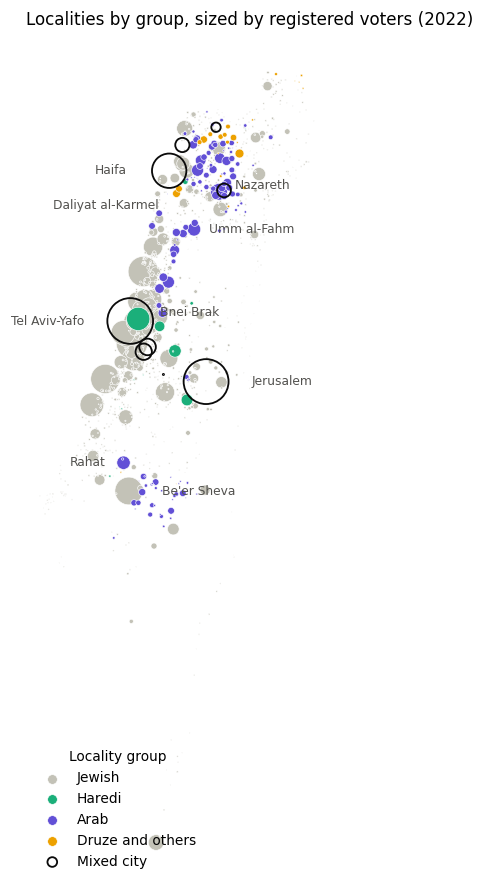

In [17]:
LABELS = {3000: ("Jerusalem", 30, 0), 5000: ("Tel Aviv-Yafo", -30, 0), 6100: ("Bnei Brak", 14, 4),
          4000: ("Haifa", -28, 0), 494: ("Daliyat al-Karmel", -12, -8), 7300: ("Nazareth", 10, 4),
          2710: ("Umm al-Fahm", 10, 0), 1161: ("Rahat", -12, 0), 9000: ("Be'er Sheva", 22, 0)}   # name, label offset (points)

on_map = localities.dropna(subset=["x_itm", "registered_2022"]).sort_values("registered_2022", ascending=False)
area = on_map["registered_2022"] / 500

fig, ax = plt.subplots(figsize=(6.5, 10))
for group, colour in GROUP_COLORS.items():
    g = on_map["group"] == group
    ax.scatter(on_map.loc[g, "x_itm"], on_map.loc[g, "y_itm"], s=area[g], color=colour,
               edgecolor="white", linewidth=0.4, label=group)
mixed = on_map["group"] == "Mixed city"
ax.scatter(on_map.loc[mixed, "x_itm"], on_map.loc[mixed, "y_itm"], s=area[mixed], facecolor="none",
           edgecolor="#0b0b0b", linewidth=1.2, label="Mixed city")
for locality, (label, dx, dy) in LABELS.items():
    x, y = on_map.loc[locality, ["x_itm", "y_itm"]]
    ax.annotate(label, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=8, color="#52514e",
                va="center", ha="left" if dx > 0 else "right")

ax.set_aspect("equal")
ax.axis("off")
legend = ax.legend(loc="lower left", frameon=False, fontsize=9, title="Locality group", title_fontsize=9)
for handle in legend.legend_handles:
    handle.set_sizes([40])
ax.set_title("Localities by group, sized by registered voters (2022)", fontsize=11, loc="left")
plt.show()

Next: what the seven elections say about turnout, the party families and the threshold.

## 3. What the past tells us

Four questions about 2013–2022, each of which shapes a choice in the model:

1. How much does turnout move, and in which groups?
2. How do the party families' votes move?
3. How often does a list land near the threshold?
4. Does each family's geography stay put from one election to the next?

In [18]:
ELECTIONS["label"] = ["2013", "2015", "Apr 2019", "Sep 2019", "2020", "2021", "2022"]
ELECTIONS["short"] = ["'13", "'15", "'19a", "'19b", "'20", "'21", "'22"]
x = np.arange(len(ELECTIONS))

### 3.1 Turnout by group

Turnout here is ballots cast at the ballot boxes divided by registered voters. It leaves out the double envelopes
(5–10% of all ballots, mostly soldiers and other Jewish voters away from home), so the Jewish sector's true turnout
is a few points higher. Section 6 splits the envelopes between the sectors.

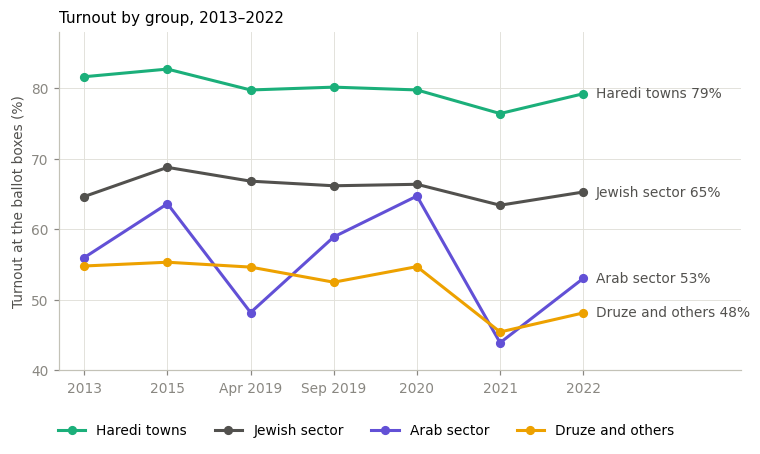

series,Haredi towns,Jewish sector,Arab sector,Druze and others
label,,,,
2013,81.6,64.6,56.0,54.8
2015,82.7,68.8,63.6,55.3
Apr 2019,79.7,66.8,48.2,54.6
Sep 2019,80.1,66.2,58.9,52.5
2020,79.7,66.4,64.7,54.7
2021,76.4,63.4,43.9,45.5
2022,79.2,65.3,53.0,48.2


In [19]:
TURNOUT_COLORS = {"Haredi towns": GROUP_COLORS["Haredi"], "Jewish sector": "#52514e",
                  "Arab sector": GROUP_COLORS["Arab"], "Druze and others": GROUP_COLORS["Druze and others"]}

series = pd.Series(np.select([boxes["group"].eq("Haredi"), boxes["group"].eq("Druze and others"), boxes["sector"].eq("Jewish")],
                             ["Haredi towns", "Druze and others", "Jewish sector"], default="Arab sector"),
                   index=boxes.index, name="series")
counts = boxes.groupby([boxes["election"], series])[["registered", "voted"]].sum()
turnout = (100 * counts["voted"] / counts["registered"]).unstack()[list(TURNOUT_COLORS)]

fig, ax = plt.subplots(figsize=(8, 4))
for name, colour in TURNOUT_COLORS.items():
    ax.plot(x, turnout[name], color=colour, marker="o", markersize=5, label=name)
    ax.annotate(f"{name} {turnout[name].iloc[-1]:.0f}%", (x[-1], turnout[name].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.set_xticks(x, ELECTIONS["label"])
ax.set_xlim(-0.3, len(x) + 0.9)
ax.set_ylim(40, 88)
ax.set_ylabel("Turnout at the ballot boxes (%)")
ax.set_title("Turnout by group, 2013–2022")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=4)
plt.show()

turnout.set_index(ELECTIONS["label"]).round(1)

- **Arab turnout is the volatile one.** It moves by 21 points, from 43.9% (2021) to 64.7% (2020). It was highest when
  the Arab parties ran together as the Joint List (2015, September 2019, 2020) and lowest when they split (April 2019,
  2021).
- **Jewish turnout is steady**, within five points (63.4–68.8%), and the Haredi towns vote at 76–83% every time.
- **The Druze and others vote at 45–55% whatever the Arab parties do**, so their gap to the Arab sector opens and
  closes with Arab turnout.

So Arab turnout gets its own model and wide uncertainty (section 6).

### 3.2 The party families over time

Each family's share of the national valid vote. The last panel is the share lost below the threshold.

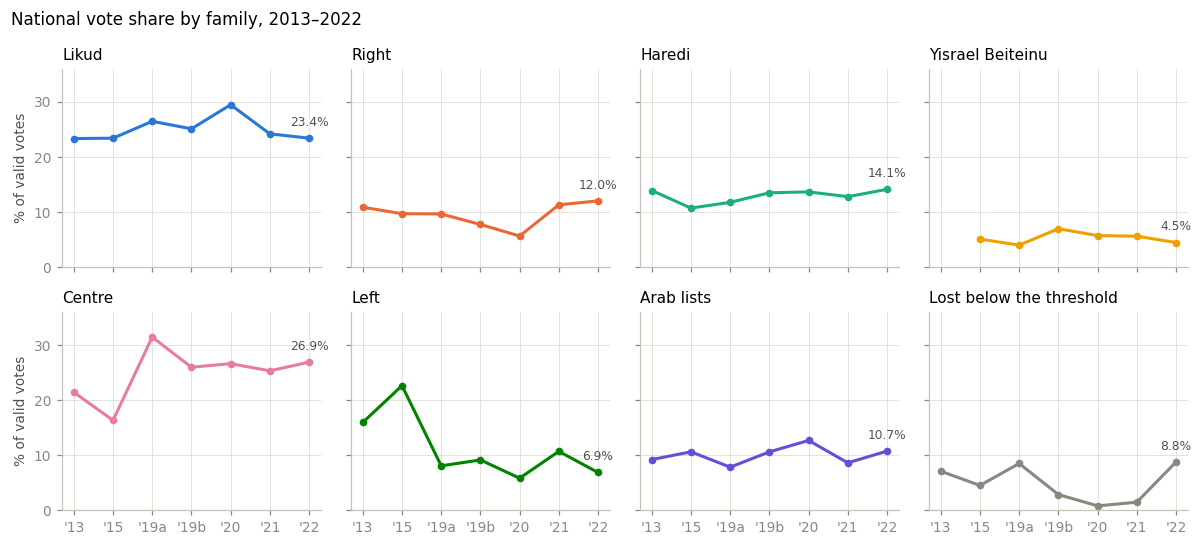

label,2013,2015,Apr 2019,Sep 2019,2020,2021,2022
family,,,,,,,
Likud,23.3% (31),23.4% (30),26.5% (35),25.1% (32),29.5% (36),24.2% (30),23.4% (32)
Right,10.9% (12),9.7% (8),9.7% (5),7.8% (7),5.7% (6),11.3% (13),12.0% (14)
Haredi,13.9% (18),10.7% (13),11.8% (16),13.5% (16),13.7% (16),12.8% (16),14.1% (18)
Yisrael Beiteinu,with Likud,5.1% (6),4.0% (5),7.0% (8),5.7% (7),5.6% (7),4.5% (6)
Centre,21.4% (27),16.3% (21),31.4% (39),25.9% (33),26.6% (33),25.3% (31),26.9% (36)
Left,15.9% (21),22.6% (29),8.1% (10),9.1% (11),5.8% (7),10.7% (13),6.9% (4)
Arab lists,9.2% (11),10.6% (13),7.8% (10),10.6% (13),12.7% (15),8.6% (10),10.7% (10)


In [20]:
shares = list_votes.pivot_table(index="election", columns="family", values="share_pct", aggfunc="sum")[FAMILIES]
seats = list_votes.pivot_table(index="election", columns="family", values="seats", aggfunc="sum")[FAMILIES]
shares.loc["K19", "Yisrael Beiteinu"] = np.nan   # in 2013 it ran on one list with Likud

fig, axes = plt.subplots(2, 4, figsize=(11, 5), sharex=True, sharey=True)
panels = [(f, shares[f], FAMILY_COLORS[f]) for f in FAMILIES[:-1]]
panels.append(("Lost below the threshold", national["below_threshold_pct"], FAMILY_COLORS["Other"]))
for ax, (title, values, colour) in zip(axes.flat, panels):
    ax.plot(x, values, color=colour, marker="o", markersize=4)
    ax.annotate(f"{values.iloc[-1]:.1f}%", (x[-1], values.iloc[-1]), xytext=(0, 8), textcoords="offset points",
                ha="center", color="#52514e", fontsize=8)
    ax.set_title(title)
    ax.set_xticks(x, ELECTIONS["short"])
    ax.set_ylim(0, 36)
for ax in axes[:, 0]:
    ax.set_ylabel("% of valid votes")
fig.suptitle("National vote share by family, 2013–2022", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

table = shares.round(1).astype(str) + "% (" + seats.fillna(0).astype(int).astype(str) + ")"
table.loc["K19", "Yisrael Beiteinu"] = "with Likud"
table.set_index(ELECTIONS["label"]).T.drop("Other")

The table gives each family's vote share and, in brackets, its seats.

- **The centre and the left trade places.** The left fell from 22.6% (2015) to 6.9% (2022); the centre peaked at 31.4%
  with Blue and White in April 2019. The families in the middle of the spectrum are where parties merge, split and
  rename.
- **Likud moves within 23–30%, and the Haredi parties are the steadiest**, between 10.7% and 14.1%.
- **The Arab lists follow Arab turnout**: 7.8% in April 2019, 12.7% in 2020.

### 3.3 The threshold

Every list with between 1% and 6% of the vote. Filled dots passed the threshold (the dashed line), open dots did not.

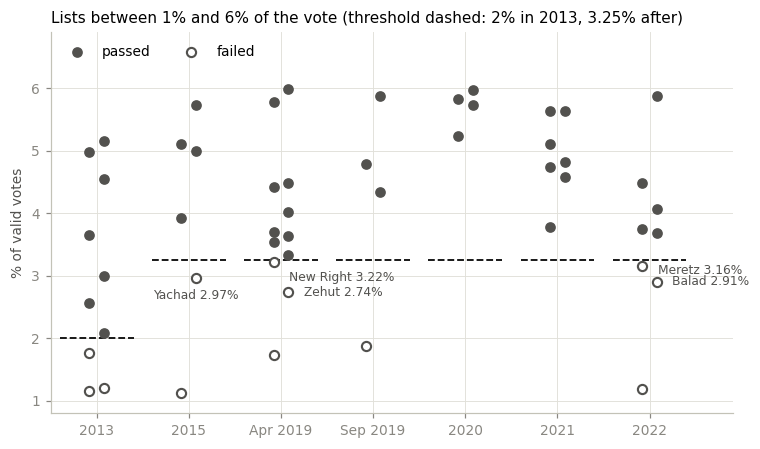

,election,list,share_pct,margin,passed
31,2013,Other: קנ,1.15,-0.85,False
27,2013,Other: ץ,1.20,-0.80,False
17,2013,Otzma LeYisrael,1.76,-0.24,False
12,2013,Kadima,2.08,0.08,True
2,2013,Balad,2.56,0.56,True
6,2013,Hadash,2.99,0.99,True
57,2015,Yachad,2.97,-0.28,False
48,2015,Meretz,3.93,0.68,True
64,Apr 2019,Zehut,2.74,-0.51,False
79,Apr 2019,New Right,3.22,-0.03,False


In [21]:
near = list_votes[list_votes["share_pct"].between(1, 6)].copy()
near["threshold"] = near["election"].map(ELECTIONS["threshold_pct"])
near["margin"] = near["share_pct"] - near["threshold"]
rank = near.groupby("election")["share_pct"].rank()
near["x"] = near["election"].map(dict(zip(ELECTIONS.index, x))) + np.where(rank % 2, -0.08, 0.08)   # dodge neighbours

LABELLED = {("K20", "Yachad"): (0, -12, "center"), ("K21", "Zehut"): (10, 0, "left"),
            ("K21", "New Right"): (10, -10, "left"), ("K25", "Meretz"): (10, -3, "left"),
            ("K25", "Balad"): (10, 0, "left")}   # label offset (points) and alignment

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, e in enumerate(ELECTIONS.index):
    ax.hlines(ELECTIONS.loc[e, "threshold_pct"], i - 0.4, i + 0.4, color="#0b0b0b", linewidth=1.2, linestyle="--")
passed = near[near["passed"]]
failed = near[~near["passed"]]
ax.scatter(passed["x"], passed["share_pct"], s=36, color="#52514e", zorder=3, label="passed")
ax.scatter(failed["x"], failed["share_pct"], s=36, facecolor="white", edgecolor="#52514e", linewidth=1.4,
           zorder=3, label="failed")
for (e, name), (dx, dy, ha) in LABELLED.items():
    row = near[(near["election"] == e) & (near["list"] == name)].iloc[0]
    ax.annotate(f"{name} {row['share_pct']:.2f}%", (row["x"], row["share_pct"]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va="center", fontsize=8, color="#52514e")
ax.set_xticks(x, ELECTIONS["label"])
ax.set_xlim(-0.5, len(x) - 0.1)
ax.set_ylim(0.8, 6.9)
ax.set_ylabel("% of valid votes")
ax.set_title("Lists between 1% and 6% of the vote (threshold dashed: 2% in 2013, 3.25% after)")
ax.legend(loc="upper left", ncol=2)
plt.show()

close = near[near["margin"].abs() <= 1].sort_values(["election", "share_pct"])
close.assign(election=close["election"].map(ELECTIONS["label"]))[["election", "list", "share_pct", "margin", "passed"]].round(2)

The table lists every list within one point of the threshold, either side. Only September 2019 and 2020 had none:

- **8 lists missed by less than a point**, including Otzma LeYisrael (2013), Yachad (2015), New Right and Zehut
  (April 2019), and Balad and Meretz (2022). The two unnamed 2013 lists, shown by their ballot letters, are small
  lists that won no seats.
- **13 passed with less than a point to spare**, five of them in April 2019 alone.
- **The closest calls:** New Right missed by 0.03 points and Meretz by 0.09; Kadima (2013) and Ra'am-Balad (April
  2019) passed by 0.08.

A list that misses takes about four seats' worth of votes out of the count, and every other list gains. So the model
cannot fix a list's pass or fail in advance: it has to simulate it, election by election.

### 3.4 Does each family's geography stay put?

If the places where a family is strong change little between elections, a forecast can start from the past map and
only move the national levels. The test: the correlation of each family's share across the same places in two
consecutive elections, weighted by votes. The Jewish families are compared across Jewish-sector places, the Arab
lists across Arab-sector places. Places with fewer than 50 valid votes are left out.

Localities can be followed across all seven elections; polling places only from September 2019, when the CEC started
to publish a stable polling-place code.

In [22]:
MIN_VALID = 50


def weighted_corr(a, b, w):
    ma, mb = np.average(a, weights=w), np.average(b, weights=w)
    va, vb = np.average((a - ma) ** 2, weights=w), np.average((b - mb) ** 2, weights=w)
    if va == 0 or vb == 0:
        return np.nan
    return np.average((a - ma) * (b - mb), weights=w) / np.sqrt(va * vb)


def paired(units, keys, before, after):
    """The same units at two elections side by side, both with at least MIN_VALID valid votes."""
    a = units[units["election"] == before].set_index(keys)
    b = units[units["election"] == after].set_index(keys)
    pair = a.join(b, lsuffix="_before", rsuffix="_after", how="inner")
    return pair[(pair["valid_before"] >= MIN_VALID) & (pair["valid_after"] >= MIN_VALID)]


def in_sector(pair, family):
    return pair[pair.index.get_level_values("sector") == ("Arab" if family == "Arab lists" else "Jewish")]


def stability(units, keys, pairs):
    table = {}
    for before, after in pairs:
        pair = paired(units, keys, before, after)
        column = {}
        for f in FAMILIES[:-1]:
            p = in_sector(pair, f)
            column[f] = weighted_corr(p[f"{f}_before"] / p["valid_before"], p[f"{f}_after"] / p["valid_after"],
                                      p["valid_after"])
        table[f"{ELECTIONS.loc[before, 'short']} → {ELECTIONS.loc[after, 'short']}"] = column
    return pd.DataFrame(table)


locality_units = (towns[towns["group"].isin(["Jewish", "Haredi", "Arab", "Druze and others"])]
                  .assign(sector=lambda d: np.where(d["group"].isin(["Arab", "Druze and others"]), "Arab", "Jewish")))
place_units = (boxes[boxes["place"].notna()]
               .groupby(["election", "locality_code", "place", "sector"], as_index=False)[["valid"] + FAMILIES].sum())

consecutive = list(zip(ELECTIONS.index[:-1], ELECTIONS.index[1:]))
by_locality = stability(locality_units, ["locality_code", "sector"], consecutive)
by_place = stability(place_units, ["locality_code", "place", "sector"], consecutive[3:])

print("Between localities")
display(by_locality.round(2))
print("Between polling places")
display(by_place.round(2))

Between localities


,'13 → '15,'15 → '19a,'19a → '19b,'19b → '20,'20 → '21,'21 → '22
Likud,0.92,0.98,0.99,0.99,0.99,0.99
Right,0.97,0.98,0.99,0.99,0.98,0.98
Haredi,0.99,1.00,1.00,1.00,1.00,1.00
Yisrael Beiteinu,NaN,0.99,0.97,0.99,0.99,0.99
Centre,0.88,0.79,0.99,0.99,0.97,0.99
Left,0.97,0.93,0.99,0.99,0.98,0.99
Arab lists,0.94,0.93,0.94,0.97,0.98,0.98


Between polling places


,'19b → '20,'20 → '21,'21 → '22
Likud,0.99,0.98,0.98
Right,0.99,0.97,0.97
Haredi,1.00,0.99,1.00
Yisrael Beiteinu,0.99,0.97,0.97
Centre,0.99,0.97,0.98
Left,0.98,0.97,0.99
Arab lists,0.96,0.97,0.97


Between localities, every correlation but two is 0.92 or more; between polling places, all are 0.96 or more. Both
exceptions are the centre: 0.88 from 2013 to 2015, and 0.79 from 2015 to April 2019, when Blue and White was founded
and drew voters from new places. A family's map changes when its parties change, and otherwise barely moves.

High correlations partly reflect how different places are (the Haredi share runs from almost 0 to 97%). The
scatter plots show the other half: from 2021 to 2022, polling places sit close to a line, with any change a shift
of the whole cloud.

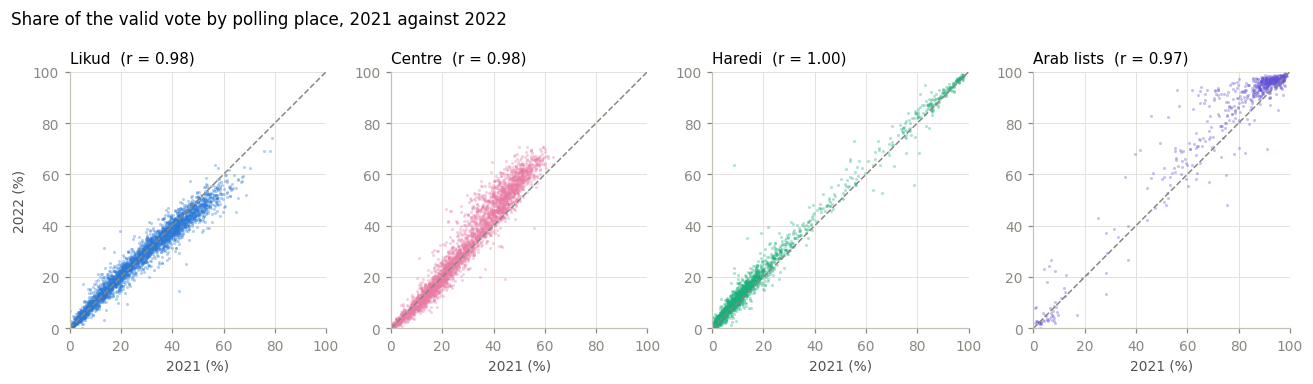

In [23]:
pair = paired(place_units, ["locality_code", "place", "sector"], "K24", "K25")
r = by_place["'21 → '22"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, f in zip(axes, ["Likud", "Centre", "Haredi", "Arab lists"]):
    p = in_sector(pair, f)
    before = 100 * p[f"{f}_before"] / p["valid_before"]
    after = 100 * p[f"{f}_after"] / p["valid_after"]
    ax.scatter(before, after, s=4, alpha=0.35, color=FAMILY_COLORS[f], linewidth=0)
    ax.plot([0, 100], [0, 100], color="#898781", linewidth=1, linestyle="--")
    ax.set(xlim=(0, 100), ylim=(0, 100), aspect="equal", xlabel="2021 (%)")
    ax.set_title(f"{f}  (r = {r[f]:.2f})")
axes[0].set_ylabel("2022 (%)")
fig.suptitle("Share of the valid vote by polling place, 2021 against 2022", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

So a polling place's past vote is a good guide to its next one, which is what the flow model of section 6.6 uses.
What moves between elections is mostly the national level, which is what the polls measure.

### 3.5 What this means for the model

| Finding | Consequence |
|---|---|
| Arab turnout swings by 20 points, Jewish turnout by 5 | Arab turnout gets its own model and the widest uncertainty |
| A family's map barely changes; its national level does | A flow model carries each polling place's vote forward (6.6); the polls give today's level |
| Lists often land within a point of the threshold | Simulate each list's pass or fail in every draw |
| The centre-left trades voters through mergers and new parties | Expect larger poll errors there than for Likud, the Haredi parties or the Arab lists (tested in section 5) |

Next: the seat rule. Bader-Ofer with surplus agreements, tested against the official seats of every election.

## 4. The seat rule

Votes become seats in three steps (Knesset Elections Law, section 81):

1. **Threshold.** Lists under the threshold are removed.
2. **Seats between units.** The 120 seats are shared by the **D'Hondt** method (largest averages): each seat in turn
   goes to the unit with the highest votes ÷ (seats already won + 1). Each list is a unit, except that two lists with
   a **surplus agreement** count as one unit.
3. **Seats inside a pair.** A pair's seats are split between its two lists by the same method.

Israel calls this the Bader-Ofer method. An agreement only moves the last seat or two, but in a close race that can
decide the majority.

In [24]:
def dhondt(votes, seats):
    """Largest averages: each seat in turn goes to the highest votes / (seats already won + 1)."""
    won = np.zeros(len(votes), dtype=int)
    for _ in range(seats):
        won[np.argmax(votes / (won + 1))] += 1
    return won


def bader_ofer(votes, agreements=(), threshold_pct=3.25, seats=120):
    """Seats per list. votes: valid votes per list (a Series); agreements: pairs of list names."""
    passed = 100 * votes / votes.sum() >= threshold_pct
    counted = votes.where(passed, 0).astype(float)
    unit = pd.Series(votes.index, index=votes.index)    # each list is its own unit...
    for a, b in agreements:                             # ...except the two lists of a surplus agreement
        if a in unit and b in unit:
            unit[[a, b]] = f"{a} + {b}"
    unit_votes = counted.groupby(unit).sum()
    unit_seats = dict(zip(unit_votes.index, dhondt(unit_votes.to_numpy(), seats)))
    result = pd.Series(0, index=votes.index)
    for u, members in unit.groupby(unit).groups.items():
        result[members] = dhondt(counted[members].to_numpy(), unit_seats[u])
    return result

A list under the threshold counts as zero votes, so an agreement with a list that failed changes nothing: the
partner keeps its own seats.

### 4.1 The surplus agreements, 2013–2022

The agreements each election's lists signed, from the Hebrew Wikipedia page of each election (section
"הסכמי עודפים"). Agreements between two lists that both failed the threshold are left out, since they could not move
a seat. Where a partner failed and is not among the main lists (Am Shalem in 2013, the New Economic Party in 2021,
Noam in September 2019), it is listed anyway and has no effect.

In [25]:
AGREEMENTS = {
    "K19": [("Likud Yisrael Beiteinu", "Jewish Home"), ("Labor", "Yesh Atid"), ("Hatnua", "Meretz"),
            ("Shas", "United Torah Judaism"), ("Hadash", "Balad"), ("Kadima", "Am Shalem")],
    "K20": [("Likud", "Jewish Home"), ("Zionist Union", "Meretz"), ("Yisrael Beiteinu", "Kulanu"),
            ("Shas", "United Torah Judaism")],
    "K21": [("Likud", "Union of Right-Wing Parties"), ("Labor", "Meretz"), ("New Right", "Yisrael Beiteinu"),
            ("Hadash-Ta'al", "Ra'am-Balad"), ("Shas", "United Torah Judaism")],
    "K22": [("Likud", "Yamina"), ("Blue and White", "Yisrael Beiteinu"), ("Labor-Gesher", "Democratic Camp"),
            ("Shas", "United Torah Judaism"), ("Otzma Yehudit", "Noam")],
    "K23": [("Likud", "Yamina"), ("Blue and White", "Labor-Gesher-Meretz"), ("Shas", "United Torah Judaism")],
    "K24": [("Likud", "Religious Zionism"), ("Yesh Atid", "Yisrael Beiteinu"), ("Yamina", "New Hope"),
            ("Labor", "Meretz"), ("Blue and White", "New Economic Party"), ("Shas", "United Torah Judaism")],
    "K25": [("Likud", "Religious Zionism"), ("Yesh Atid", "National Unity"), ("Labor", "Meretz"),
            ("Shas", "United Torah Judaism")],
}

### 4.2 Test: does the rule give the official seats?

Each election is run twice, without and with the agreements, and compared with the CEC's official seats.

In [26]:
def seats_moved(computed, official):
    return int((computed - official).abs().sum() // 2)


rows, differences = [], {}
for e in ELECTIONS.index:
    lv = list_votes[list_votes["election"] == e].set_index("list")
    threshold = ELECTIONS.loc[e, "threshold_pct"]
    without = bader_ofer(lv["votes"], (), threshold)
    with_agreements = bader_ofer(lv["votes"], AGREEMENTS[e], threshold)
    rows.append({"seats moved without agreements": seats_moved(without, lv["seats"]),
                 "seats moved with agreements": seats_moved(with_agreements, lv["seats"])})
    gap = (without - lv["seats"])[lambda s: s != 0]
    differences[ELECTIONS.loc[e, "label"]] = ", ".join(f"{name} {d:+d}" for name, d in gap.items())

test = pd.DataFrame(rows, index=ELECTIONS["label"])
test["without agreements, against the official seats"] = pd.Series(differences)
assert (test["seats moved with agreements"] == 0).all()
test

,seats moved without agreements,seats moved with agreements,"without agreements, against the official seats"
label,,,
2013,0,0,
2015,1,0,"Joint List +1, Kulanu -1"
Apr 2019,1,0,"United Torah Judaism -1, Likud +1"
Sep 2019,0,0,
2020,0,0,
2021,1,0,"Likud +1, Meretz -1"
2022,1,0,"Labor +1, Likud -1"


With the agreements the rule reproduces every official seat in all seven elections. Without them, four elections
come out one seat wrong. In 2022 Labor would have had 5 seats and Likud 31; Likud's agreement with Religious Zionism
pooled their remainders and took the last seat, which moved it across the blocs.

### 4.3 What one list at the threshold can do

A list that passes wins at least four seats, so the lists near the threshold matter far beyond their
size. Two 2022 counterfactuals show it, each moving
votes inside a family so that the total stays the same:

- **Meretz passes**: 4,062 votes move from Labor to Meretz (0.09% of the vote), which lifts Meretz to 3.25%.
- **Balad passes**: 16,238 votes move from Hadash-Ta'al to Balad.

The Netanyahu bloc of 2022 is Likud, Religious Zionism, Shas and United Torah Judaism.

In [27]:
NETANYAHU_2022 = ["Likud", "Religious Zionism", "Shas", "United Torah Judaism"]
votes_2022 = list_votes[list_votes["election"] == "K25"].set_index("list")["votes"]


def lift_to_threshold(votes, lifted, donor):
    """Move just enough votes from donor to lifted for lifted to reach 3.25%."""
    moved = int(np.ceil(0.0325 * votes.sum())) - votes[lifted]
    return votes.add(pd.Series({lifted: moved, donor: -moved}), fill_value=0), moved


meretz_votes, meretz_moved = lift_to_threshold(votes_2022, "Meretz", "Labor")
balad_votes, balad_moved = lift_to_threshold(votes_2022, "Balad", "Hadash-Ta'al")
scenarios = pd.DataFrame({
    "actual": bader_ofer(votes_2022, AGREEMENTS["K25"]),
    f"Meretz passes (+{meretz_moved:,} votes)": bader_ofer(meretz_votes, AGREEMENTS["K25"]),
    f"Balad passes (+{balad_moved:,} votes)": bader_ofer(balad_votes, AGREEMENTS["K25"]),
})
scenarios = scenarios[(scenarios > 0).any(axis=1)].sort_values("actual", ascending=False)
scenarios.loc["Netanyahu bloc"] = scenarios.loc[NETANYAHU_2022].sum()
scenarios

,actual,"Meretz passes (+4,062 votes)","Balad passes (+16,238 votes)"
list,,,
Likud,32,30,31
Yesh Atid,24,23,23
Religious Zionism,14,14,14
National Unity,12,12,12
Shas,11,11,11
United Torah Judaism,7,7,7
Yisrael Beiteinu,6,5,5
Hadash-Ta'al,5,4,4
Ra'am,5,5,5


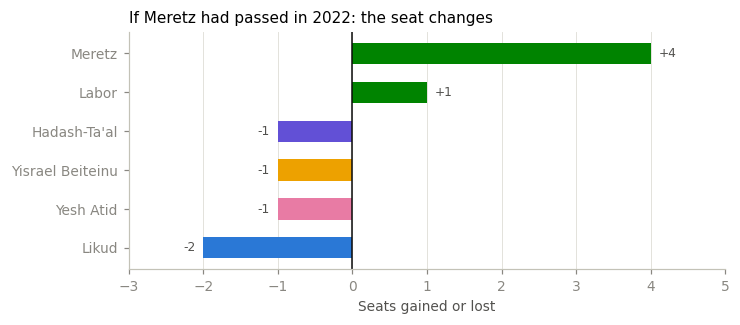

In [28]:
seat_change = (scenarios.iloc[:, 1] - scenarios["actual"]).drop("Netanyahu bloc")
seat_change = seat_change[seat_change != 0].sort_values()
family_2022 = list_votes[list_votes["election"] == "K25"].set_index("list")["family"]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(seat_change.index, seat_change, height=0.55, color=[FAMILY_COLORS[family_2022[n]] for n in seat_change.index])
ax.axvline(0, color="#0b0b0b", linewidth=1)
for y, value in enumerate(seat_change):
    ax.annotate(f"{value:+d}", (value, y), xytext=(5 if value > 0 else -5, 0), textcoords="offset points",
                ha="left" if value > 0 else "right", va="center", fontsize=8, color="#52514e")
ax.set_xlim(-3, 5)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Seats gained or lost", title="If Meretz had passed in 2022: the seat changes")
plt.show()

0.09% of the vote, moved inside the left, takes the Netanyahu bloc from 64 seats to 62. Meretz's four seats come
mostly from Likud (−2), Yesh Atid, Yisrael Beiteinu and Hadash-Ta'al (−1 each); Labor gains a seat because its
agreement with Meretz now counts. Balad passing costs the bloc one seat.

### 4.4 A fast version for the simulation

`bader_ofer` takes about 10 milliseconds per election, so 10,000 simulated elections would take minutes. The
simulation in section 7 uses a vectorised version that counts all draws at once. D'Hondt gives a unit as many seats
as it has quotients (votes ÷ 1, ÷ 2, ÷ 3 …) among the 120 largest, so the fast version computes every quotient,
finds the 120th largest per draw, and counts.

A list that fails the threshold has zero votes, so its agreement unit is simply its partner. That is why the units
can be fixed in advance, whatever passes in each draw.

In [29]:
def top_quotients(votes, seats):
    """D'Hondt for many rows at once. votes: (draws, parties); seats: (draws,) -> seats per party."""
    if seats.max() == 0:
        return np.zeros(votes.shape, dtype=int)
    quotients = votes[:, :, None] / np.arange(1, seats.max() + 1)
    ranked = -np.sort(-quotients.reshape(len(votes), -1), axis=1)
    cutoff = ranked[np.arange(len(votes)), np.maximum(seats - 1, 0)]
    won = (quotients >= cutoff[:, None, None]).sum(axis=2)
    return np.where(seats[:, None] > 0, won, 0)


def agreement_units(lists, agreements):
    """A unit number per list; the two lists of an agreement share one."""
    unit = {name: name for name in lists}
    for a, b in agreements:
        if a in unit and b in unit:
            unit[b] = unit[a]
    return pd.factorize(pd.Series([unit[name] for name in lists]))[0]


def bader_ofer_fast(votes, units, threshold_pct=3.25, seats=120, chunk=2_000):
    """Seats for many elections. votes: (draws, lists); units: from agreement_units."""
    votes = np.asarray(votes, dtype=float)
    counted = np.where(100 * votes / votes.sum(axis=1, keepdims=True) >= threshold_pct, votes, 0.0)
    membership = np.eye(units.max() + 1)[units]                  # (lists, units)
    result = np.zeros(counted.shape, dtype=int)
    for start in range(0, len(counted), chunk):
        part = counted[start:start + chunk]
        unit_seats = top_quotients(part @ membership, np.full(len(part), seats))
        for u in range(membership.shape[1]):
            cols = np.flatnonzero(units == u)
            if len(cols) == 1:
                result[start:start + chunk, cols[0]] = unit_seats[:, u]
            else:
                result[start:start + chunk, cols] = top_quotients(part[:, cols], unit_seats[:, u])
    return result

The test: the fast version must give exactly the reference seats, first for the seven elections, then for 500
random elections built by shaking the 2022 votes (each list's votes times a random factor of about ±30%), so that
lists cross the threshold in both directions.

In [30]:
for e in ELECTIONS.index:
    lv = list_votes[list_votes["election"] == e].set_index("list")
    fast = bader_ofer_fast(lv["votes"].to_numpy()[None, :], agreement_units(lv.index, AGREEMENTS[e]),
                           ELECTIONS.loc[e, "threshold_pct"])
    assert (fast[0] == lv["seats"].to_numpy()).all(), e

rng = np.random.default_rng(2026)
shaken = votes_2022.to_numpy() * rng.lognormal(0, 0.3, size=(500, len(votes_2022)))
units_2022 = agreement_units(votes_2022.index, AGREEMENTS["K25"])

start = pd.Timestamp.now()
reference = np.array([bader_ofer(pd.Series(row, index=votes_2022.index), AGREEMENTS["K25"]).to_numpy() for row in shaken])
reference_time = (pd.Timestamp.now() - start).total_seconds()
start = pd.Timestamp.now()
fast = bader_ofer_fast(shaken, units_2022)
fast_time = (pd.Timestamp.now() - start).total_seconds()

assert (fast == reference).all() and (fast.sum(axis=1) == 120).all()
crossings = ((100 * shaken / shaken.sum(axis=1, keepdims=True) >= 3.25) != (votes_2022 / votes_2022.sum() >= 0.0325).to_numpy()).any(axis=1)
print(f"500 random elections: identical seats in all of them; {crossings.mean():.0%} had a list cross the threshold")
print(f"reference {reference_time:.1f} s, fast {fast_time:.3f} s ({reference_time / fast_time:,.0f} times faster)")

500 random elections: identical seats in all of them; 91% had a list cross the threshold
reference 6.1 s, fast 0.029 s (207 times faster)


Next: the polls, and how the final polls of 2021 and 2022 compared with the results.

## 5. The polls and how they missed

The forecast starts from the polls, so the first question is how good the polls have been. This section uses the
published polls of the last two campaigns (2021 and 2022, seats per list) to measure:

- how far the final-week poll average missed, list by list and family by family;
- whether any family is missed in the same direction every time, so that a correction is justified;
- which way of averaging the polls worked best;
- how large an error the simulation should draw.

It ends with the 2026 polls and their average, the starting point of the forecast.

In [31]:
polls = {e: pd.read_csv(DATA / "polls" / f"polls_{e.lower()}.csv", encoding="utf-8-sig", parse_dates=["date"])
         for e in ["K24", "K25", "K26"]}
for d in polls.values():
    d["pollster"] = d["pollster_en"]

LISTS_2026 = pd.read_csv(DATA / "lists_2026.csv", keep_default_na=False).set_index("key")

# each poll column -> the list it stood for on election day (some columns change list during a campaign)
POLL_LISTS = {
    "K24": {"likud": "Likud", "yesh_atid": "Yesh Atid", "shas": "Shas", "blue_white": "Blue and White",
            "yamina": "Yamina", "labor": "Labor", "utj": "United Torah Judaism", "yisrael_beiteinu": "Yisrael Beiteinu",
            "religious_zionism": "Religious Zionism", "joint_list": "Joint List", "new_hope": "New Hope",
            "meretz": "Meretz", "raam": "Ra'am", "economic_party": "Other: יז"},
    "K25": {"likud": "Likud", "yesh_atid": "Yesh Atid", "religious_zionism": "Religious Zionism",
            "national_unity": "National Unity", "shas": "Shas", "utj": "United Torah Judaism",
            "yisrael_beiteinu": "Yisrael Beiteinu", "raam": "Ra'am", "joint_list": "Hadash-Ta'al", "labor": "Labor",
            "meretz": "Meretz", "zionist_spirit": "Jewish Home"},
    "K26": LISTS_2026["list"].to_dict(),
}

pd.DataFrame({ELECTIONS.loc[e, "label"] if e in ELECTIONS.index else "2026":
              {"polls": len(d), "pollsters": d["pollster"].nunique(),
               "first": d["date"].min().date(), "last": d["date"].max().date()}
              for e, d in polls.items()})

,2021,2022,2026
polls,125,127,120
pollsters,8,7,10
first,2020-08-06,2022-01-06,2026-07-29
last,2021-03-19,2022-10-28,2026-10-21


### 5.1 How the final polls missed

The poll average here is each pollster's last poll in the final week of the campaign, with equal weights (5.4
compares it with other averages). The Economic Party of 2021 is left out: polled at 0 seats, it won 0.

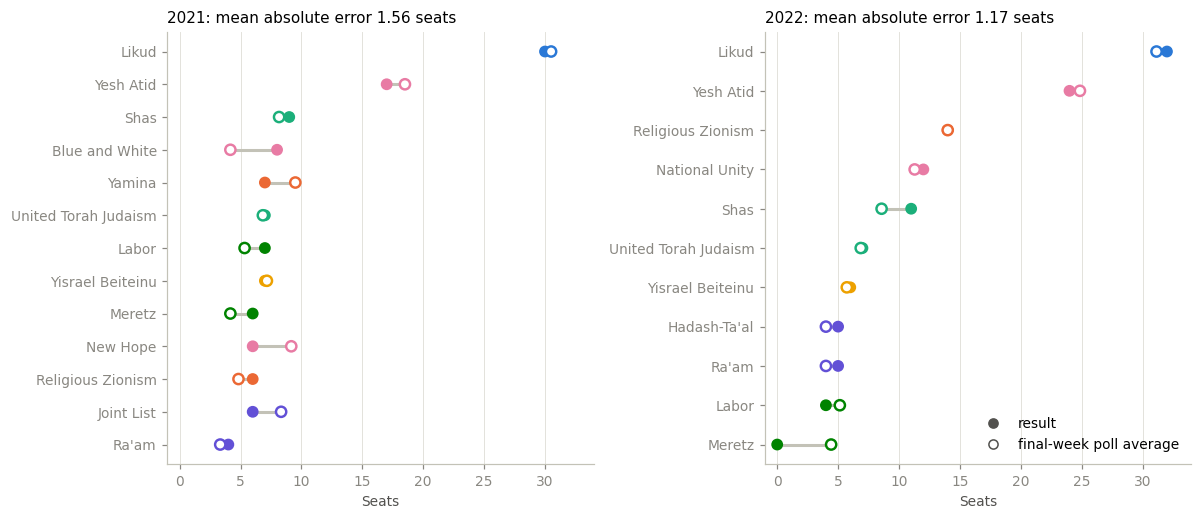

In [32]:
NETANYAHU = {"K24": ["Likud", "Shas", "United Torah Judaism", "Religious Zionism"],
             "K25": ["Likud", "Religious Zionism", "Shas", "United Torah Judaism"]}


def final_week(e, days=7, last_per_pollster=True, by_sample=False):
    """Average seats per list over the `days` days up to the newest poll."""
    d = polls[e]
    window = d[d["date"] > d["date"].max() - pd.Timedelta(days=days)]
    if last_per_pollster:
        window = window.sort_values("date").groupby("pollster").tail(1)
    seats = window[list(POLL_LISTS[e])].rename(columns=POLL_LISTS[e]).dropna(axis=1, how="all")
    weight = window["respondents"] if by_sample else pd.Series(1.0, index=window.index)
    return seats.mul(weight, axis=0).sum() / seats.notna().mul(weight, axis=0).sum()


def poll_errors(e, **method):
    poll = final_week(e, **method)
    result = list_votes[list_votes["election"] == e].set_index("list").loc[poll.index]
    out = pd.DataFrame({"election": e, "list": poll.index, "family": result["family"], "poll": poll,
                        "result": result["seats"], "error": poll - result["seats"]}).reset_index(drop=True)
    return out[(out["poll"] > 0) | (out["result"] > 0)]


errors = pd.concat([poll_errors(e) for e in ["K24", "K25"]], ignore_index=True)
mae = errors.groupby("election")["error"].apply(lambda s: s.abs().mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, e in zip(axes, ["K24", "K25"]):
    d = errors[errors["election"] == e].sort_values("result")
    y = np.arange(len(d))
    colours = [FAMILY_COLORS[f] for f in d["family"]]
    ax.hlines(y, d["poll"], d["result"], color="#c3c2b7", linewidth=2)
    ax.scatter(d["result"], y, s=45, color=colours, zorder=3)
    ax.scatter(d["poll"], y, s=45, facecolor="white", edgecolor=colours, linewidth=1.6, zorder=3)
    ax.set_yticks(y, d["list"])
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Seats", xlim=(-1, 34), title=f"{ELECTIONS.loc[e, 'label']}: mean absolute error {mae[e]:.2f} seats")
handles = [plt.Line2D([], [], marker="o", linestyle="", color="#52514e", label="result"),
           plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="#52514e",
                      label="final-week poll average")]
axes[1].legend(handles=handles, loc="lower right")
fig.tight_layout()
plt.show()

The polls miss by 1.2–1.6 seats per list on average, and the largest misses are the lists of the shifting centre and
right: in 2021 Blue and White was underestimated by almost 4 seats and New Hope and Yamina overestimated by 3 and 2.5.
In 2022 Meretz polled 4.4 seats and fell below the threshold.

### 5.2 Is any family missed the same way every time?

The errors added up by family. A positive error means the polls gave the family too many seats.

In [33]:
family_error = (errors.pivot_table(index="family", columns="election", values="error", aggfunc="sum")
                      .rename(columns=ELECTIONS["label"]))
family_error["mean"] = family_error.mean(axis=1)
family_error["same sign"] = np.sign(family_error["2021"]) == np.sign(family_error["2022"])

bloc_error = pd.Series({ELECTIONS.loc[e, "label"]: errors[(errors["election"] == e) & errors["list"].isin(NETANYAHU[e])]["error"].sum()
                        for e in ["K24", "K25"]}, name="Netanyahu bloc")
print("Netanyahu bloc, poll average minus result (seats):", bloc_error.round(1).to_dict())
family_error.round(2)

Netanyahu bloc, poll average minus result (seats): {'2021': -1.7, '2022': -3.4}


election,2021,2022,mean,same sign
family,,,,
Arab lists,1.67,-2.00,-0.17,False
Centre,0.83,0.14,0.49,True
Haredi,-1.00,-2.57,-1.79,True
Left,-3.50,5.57,1.04,False
Likud,0.50,-0.86,-0.18,False
Right,1.33,0.00,0.67,False
Yisrael Beiteinu,0.17,-0.29,-0.06,False


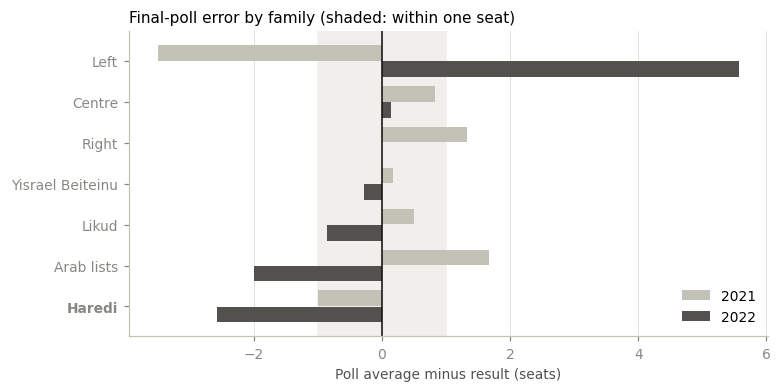

In [34]:
fe = family_error[["2021", "2022"]].sort_values("2022")
y = np.arange(len(fe))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axvspan(-1, 1, color="#f0efec", zorder=0)
ax.barh(y + 0.2, fe["2021"], height=0.38, color="#c3c2b7", label="2021")
ax.barh(y - 0.2, fe["2022"], height=0.38, color="#52514e", label="2022")
ax.axvline(0, color="#0b0b0b", linewidth=1)
ax.set_yticks(y, fe.index)
ax.get_yticklabels()[list(fe.index).index("Haredi")].set_fontweight("bold")
ax.grid(axis="y", visible=False)
ax.set(xlabel="Poll average minus result (seats)", title="Final-poll error by family (shaded: within one seat)")
ax.legend(loc="lower right")
plt.show()

Only the Haredi parties are missed in the same direction in both elections by more than a seat on average: the polls
gave them 1.0 seat too few in 2021 and 2.6 too few in 2022. A common explanation is that Haredi voters are hard to
reach by phone and online panels, while their towns turn out at 76–83% (section 3). The other families flip sign
between the two elections.

The rule for a correction, fixed before looking at 2026: **correct a family only when its error has the same sign
in both elections and averages more than one seat.** Only the Haredi family qualifies, by +1.8 seats.

The Netanyahu bloc was also underestimated both times (by 1.7 and 3.4 seats); the Haredi miss is more than half of
that.

In [35]:
corrected_families = family_error[family_error["same sign"] & (family_error["mean"].abs() > 1)]
POLL_CORRECTION = (-corrected_families["mean"]).round(2).to_dict()     # seats added to the poll average, by family
print("Correction (seats):", POLL_CORRECTION)


def correct(poll, family, correction):
    """Add each family's correction (split over its lists by seats), then rescale to the same total."""
    out = poll.astype(float).copy()
    for fam, add in correction.items():
        members = poll.index[family.reindex(poll.index) == fam]
        out[members] += add * poll[members] / poll[members].sum()
    return out * poll.sum() / out.sum()


for e in ["K24", "K25"]:
    d = errors[errors["election"] == e].set_index("list")
    fixed = correct(d["poll"], d["family"], POLL_CORRECTION)
    fixed_error = fixed - d["result"]
    print(f"{ELECTIONS.loc[e, 'label']}: mean absolute error {d['error'].abs().mean():.2f} -> {fixed_error.abs().mean():.2f}, "
          f"Netanyahu bloc error {d.loc[NETANYAHU[e], 'error'].sum():+.1f} -> {fixed_error[NETANYAHU[e]].sum():+.1f}")

Correction (seats): {'Haredi': 1.79}
2021: mean absolute error 1.56 -> 1.46, Netanyahu bloc error -1.7 -> -0.6
2022: mean absolute error 1.17 -> 1.18, Netanyahu bloc error -3.4 -> -2.6


The correction shrinks the bloc error in both elections and the list error in 2021; in 2022 the list error stays
the same. It is fitted on these same two elections, so this is a description, not a test.
The back-test in section 7 is no fairer, for the same reason; section 7 also shows the 2026 forecast with and
without it.

### 5.3 Pollster by pollster

Each pollster's last poll in the final week.

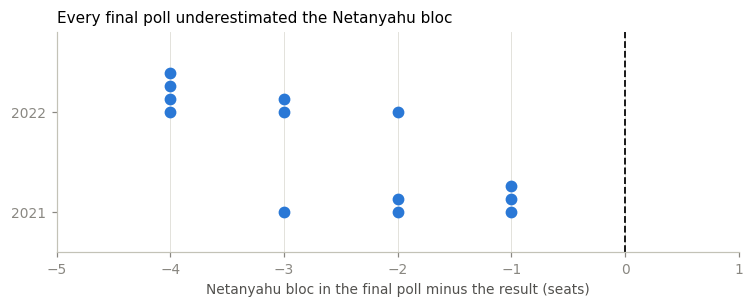

In [36]:
rows = []
for e in ["K24", "K25"]:
    d = polls[e]
    result = list_votes[list_votes["election"] == e].set_index("list")["seats"]
    last = d[d["date"] > d["date"].max() - pd.Timedelta(days=7)].sort_values("date").groupby("pollster").tail(1)
    for _, poll in last.iterrows():
        seats = poll[list(POLL_LISTS[e])].rename(POLL_LISTS[e]).dropna().astype(float)
        error = (seats - result[seats.index])[(seats > 0) | (result[seats.index] > 0)]
        rows.append({"election": ELECTIONS.loc[e, "label"], "pollster": poll["pollster"], "date": poll["date"].date(),
                     "mean abs. error": error.abs().mean(), "Netanyahu bloc error": error[NETANYAHU[e]].sum(),
                     "Haredi error": error[["Shas", "United Torah Judaism"]].sum()})
pollsters = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (label, d) in enumerate(pollsters.groupby("election", sort=False)):
    stack = d.groupby("Netanyahu bloc error").cumcount()
    ax.scatter(d["Netanyahu bloc error"], i + 0.13 * stack, s=45, color=FAMILY_COLORS["Likud"], zorder=3)
ax.axvline(0, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.set_yticks([0, 1], pollsters["election"].unique())
ax.set(xlim=(-5, 1), ylim=(-0.4, 1.8), xlabel="Netanyahu bloc in the final poll minus the result (seats)",
       title="Every final poll underestimated the Netanyahu bloc")
ax.grid(axis="y", visible=False)
plt.show()

All thirteen final polls had the Netanyahu bloc too low, by 1 to 4 seats; no pollster was consistently better than
the others. The firms of 2026 only partly match those of 2021–2022, and two elections are too few to estimate any
one firm's lean, so the model does not correct pollsters individually.

### 5.4 Which poll average?

Four ways to average the final polls, scored by their mean absolute error in seats.

In [37]:
METHODS = {"each pollster's last poll, 7 days": dict(days=7, last_per_pollster=True),
           "all polls, 7 days": dict(days=7, last_per_pollster=False),
           "all polls, 14 days": dict(days=14, last_per_pollster=False),
           "all polls, 7 days, weighted by sample": dict(days=7, last_per_pollster=False, by_sample=True)}

scores = pd.DataFrame({name: {ELECTIONS.loc[e, "label"]: poll_errors(e, **m)["error"].abs().mean() for e in ["K24", "K25"]}
                       for name, m in METHODS.items()}).T
scores["mean"] = scores.mean(axis=1)
scores.round(2)

,2021,2022,mean
"each pollster's last poll, 7 days",1.56,1.17,1.37
"all polls, 7 days",1.62,1.12,1.37
"all polls, 14 days",1.86,1.11,1.49
"all polls, 7 days, weighted by sample",1.63,1.05,1.34


The differences are small. Weighting by sample size scores best on average, but only because of 2022: it is worse
than the simplest average in 2021. Its edge is 0.03 seats, far smaller than the gap between the two elections. In
2026 it would give Next Data alone 37% of the weight (several polls of about 2,000 respondents in the final week),
and Next Data has by far the largest Likud. The notebook keeps **each
pollster's last poll in the final week, equal weights**: one vote per pollster, no tuning. Section 7 shows the
sample-weighted average as a sensitivity.

### 5.5 How large an error to simulate

The simulation needs the size of a list's poll error. It is measured on the lists that won seats (Meretz 2022 is left
out: its miss was a threshold flip, which the simulation produces by itself) and converted to share points with each
election's seat price, (100 − % lost below the threshold) / 120.

In [38]:
seated = errors[errors["result"] > 0].copy()
seat_price = (100 - national["below_threshold_pct"]) / 120              # share points per seat, by election
seated["error_points"] = seated["error"] * seated["election"].map(seat_price)

LIST_ERROR_SEATS = float(np.sqrt((seated["error"] ** 2).mean()))
LIST_ERROR_POINTS = float(np.sqrt((seated["error_points"] ** 2).mean()))
print(f"{len(seated)} lists: root-mean-square error {LIST_ERROR_SEATS:.2f} seats = {LIST_ERROR_POINTS:.2f} share points")

23 lists: root-mean-square error 1.60 seats = 1.30 share points


Should the simulation also draw a shared swing between the blocs, on top of the list errors? Independent list errors
already move the bloc totals, because a bloc is several lists and the seats must add up to 120. A quick simulation
gives the bloc error that independent errors of this size produce, to compare with the bloc errors of 2021 and 2022
after the Haredi correction.

In [39]:
rng = np.random.default_rng(6)
implied, observed = {}, {}
for e in ["K24", "K25"]:
    d = errors[errors["election"] == e].set_index("list")
    draws = rng.normal(0, LIST_ERROR_SEATS, size=(20_000, len(d)))
    draws -= draws.mean(axis=1, keepdims=True)                          # the seats still add up to 120
    implied[ELECTIONS.loc[e, "label"]] = draws[:, d.index.isin(NETANYAHU[e])].sum(axis=1).std()
    fixed = correct(d["poll"], d["family"], POLL_CORRECTION)
    observed[ELECTIONS.loc[e, "label"]] = (fixed - d["result"])[NETANYAHU[e]].sum()

print("Bloc error from independent list errors, standard deviation:",
      ", ".join(f"{k} ±{v:.1f}" for k, v in implied.items()), "seats")
print("Bloc error left after the Haredi correction:", ", ".join(f"{k} {v:+.1f}" for k, v in observed.items()), "seats")

Bloc error from independent list errors, standard deviation:

 2021 ±2.7, 2022 ±2.5 seats
Bloc error left after the Haredi correction: 2021 -0.6, 2022 -2.6 seats


Independent list errors alone give the bloc an error of about ±2.6 seats (one standard deviation), as large as the
errors left after the Haredi correction (−0.6 and −2.6). Both are still negative, but two elections cannot separate a
shared swing from that, so the model draws independent list errors only; section 7 adds a bloc swing as a
sensitivity test.

### 5.6 The 2026 campaign

Every national poll of the 2026 campaign, one panel per list. The line is a centred average of the nine nearest
polls.

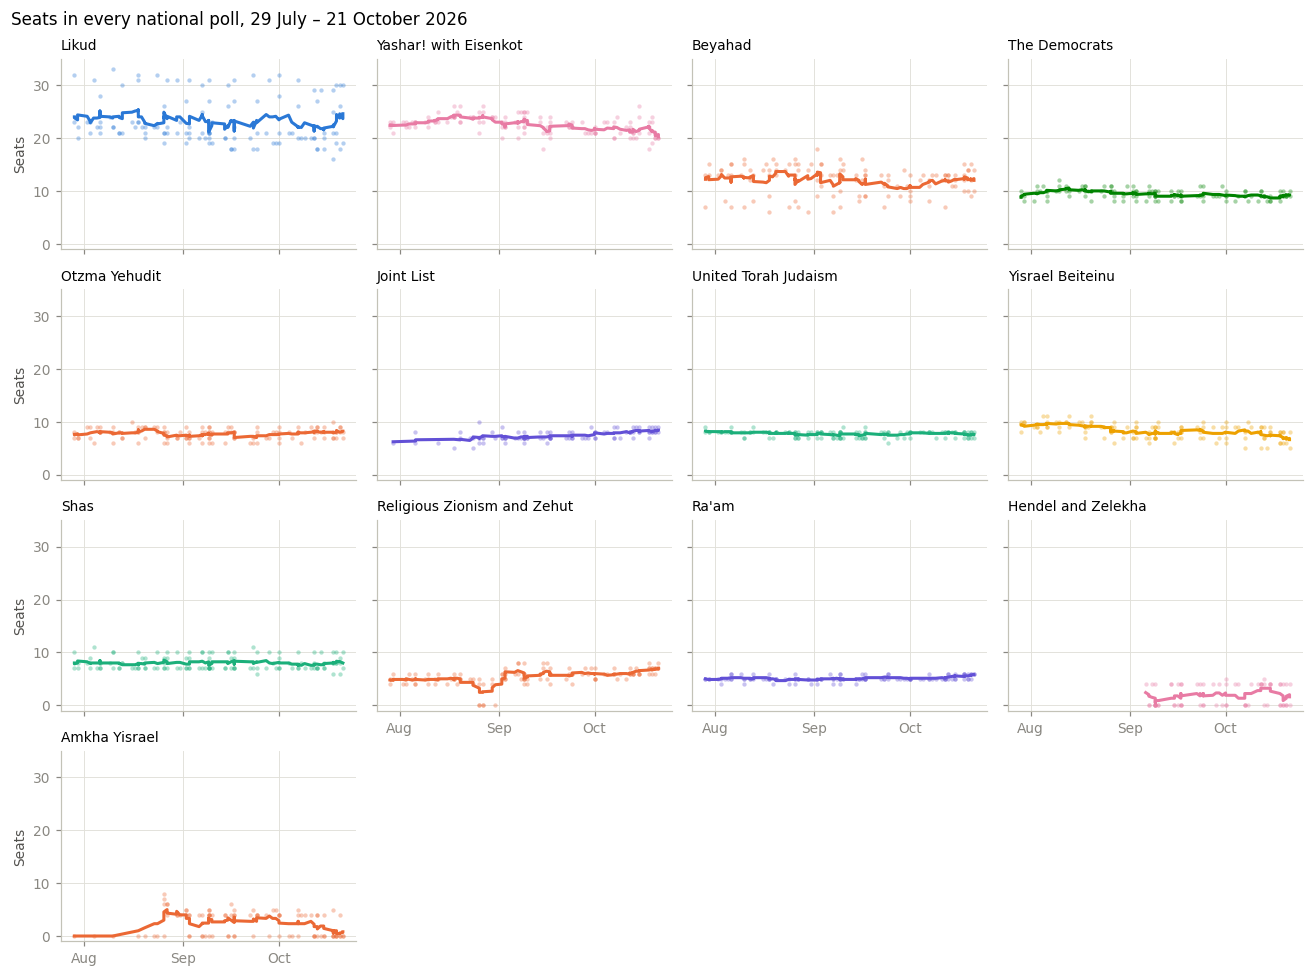

In [40]:
import matplotlib.dates as mdates

k26 = polls["K26"]
on_ballot = LISTS_2026.index[LISTS_2026["on_ballot"] == "yes"]

fig, axes = plt.subplots(4, 4, figsize=(12, 9), sharex=True, sharey=True)
for ax, key in zip(axes.flat, on_ballot):
    d = k26[["date", key]].dropna().sort_values("date")
    colour = FAMILY_COLORS[LISTS_2026.loc[key, "family"]]
    ax.scatter(d["date"], d[key], s=8, alpha=0.35, color=colour, linewidth=0)
    ax.plot(d["date"], d[key].rolling(9, center=True, min_periods=5).mean(), color=colour)
    ax.set_title(LISTS_2026.loc[key, "list"], fontsize=9)
    ax.set_ylim(-1, 35)
for ax in axes.flat[len(on_ballot):]:
    ax.axis("off")
for ax in axes.flat:
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes[-2, 1:]:
    ax.tick_params(labelbottom=True)                                 # the panels below them are empty
for ax in axes[:, 0]:
    ax.set_ylabel("Seats")
fig.suptitle("Seats in every national poll, 29 July – 21 October 2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

#### The 2026 poll average

The same average as for 2021 and 2022: each pollster's last poll in the week up to the newest poll (15–21 October).
Blue and White withdrew on 19 October; it had no seats in these polls.

In [41]:
window = k26[k26["date"] > k26["date"].max() - pd.Timedelta(days=7)].sort_values("date").groupby("pollster").tail(1)
assert window["blue_white"].fillna(0).eq(0).all()

final_2026 = window.set_index("pollster")[list(on_ballot)].rename(columns=LISTS_2026["list"])
final_2026.insert(0, "date", window.set_index("pollster")["date"].dt.strftime("%d %b"))
netanyahu_2026 = LISTS_2026.loc[on_ballot].query("bloc == 'Netanyahu'")["list"]
final_2026["Netanyahu bloc"] = final_2026[netanyahu_2026].sum(axis=1)
final_2026.loc["average"] = final_2026.drop(columns="date").mean()
final_2026.T.style.format(precision=1, na_rep="")

pollster,Tatika,Kantar Israel,Midgam (Mano Geva),Menachem Lazar,Maagar Mochot,Direct Polls,Next Data,Shmuel Rosner,average
date,15 Oct,18 Oct,19 Oct,19 Oct,20 Oct,20 Oct,21 Oct,21 Oct,
Likud,20.0,21.0,21.0,19.0,18.0,26.0,30.0,19.0,21.8
Yashar! with Eisenkot,26.0,23.0,24.0,23.0,21.0,20.0,20.0,20.0,22.1
Beyahad,11.0,12.0,14.0,14.0,15.0,12.0,10.0,14.0,12.8
The Democrats,8.0,9.0,9.0,9.0,9.0,9.0,9.0,10.0,9.0
Otzma Yehudit,7.0,8.0,8.0,8.0,9.0,9.0,8.0,7.0,8.0
Joint List,8.0,8.0,9.0,8.0,9.0,8.0,8.0,9.0,8.4
United Torah Judaism,8.0,7.0,7.0,7.0,7.0,8.0,7.0,8.0,7.4
Yisrael Beiteinu,9.0,8.0,8.0,8.0,7.0,7.0,5.0,8.0,7.5
Shas,8.0,8.0,8.0,8.0,6.0,8.0,10.0,7.0,7.9


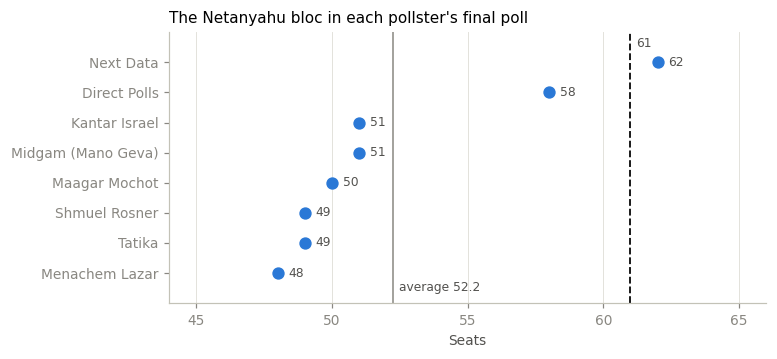

In [42]:
bloc_by_pollster = final_2026["Netanyahu bloc"].drop("average").astype(float).sort_values()
average_bloc = final_2026.loc["average", "Netanyahu bloc"]
y = np.arange(len(bloc_by_pollster))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvline(61, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.axvline(average_bloc, color="#898781", linewidth=1)
ax.scatter(bloc_by_pollster, y, s=50, color=FAMILY_COLORS["Likud"], zorder=3)
for yy, value in zip(y, bloc_by_pollster):
    ax.annotate(f"{value:.0f}", (value, yy), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8,
                color="#52514e")
ax.annotate("61", (61, len(y) - 0.5), xytext=(4, 0), textcoords="offset points", fontsize=8, color="#52514e")
ax.annotate(f"average {average_bloc:.1f}", (average_bloc, -0.6), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color="#52514e")
ax.set_yticks(y, bloc_by_pollster.index)
ax.set(xlim=(44, 66), ylim=(-1, len(y)), xlabel="Seats", title="The Netanyahu bloc in each pollster's final poll")
ax.set_xticks(range(45, 66, 5))
ax.grid(axis="y", visible=False)
plt.show()

The pollsters disagree most about Likud (18 to 30 seats) and so about the bloc: Next Data, the pollster with the
largest Likud, is the only one to give the Netanyahu bloc 61 or more.

The model works in vote shares, not seats: a list just under the threshold polls at 0 seats but may be at 3.1%, and
that difference matters. Most pollsters print each list's share beside its seats. Each poll's shares are divided by
the sum of all the list shares it prints (the undecided left out), so that they add up to 100 with the small lists
outside the table as "others". Rosner prints seats only and is left out of the share average. Blue and White's share,
where printed, goes to the other opposition lists of that poll in proportion.

In [43]:
share_columns = [c for c in k26.columns if c.endswith("_pct") and c not in ("undecided_pct", "not_voting_pct", "moe_pct")]
with_shares = window[window[share_columns].notna().any(axis=1)].set_index("pollster")
raw = with_shares[share_columns].fillna(0)
raw.columns = [c.removesuffix("_pct") for c in raw.columns]
shares_2026 = raw.div(raw.sum(axis=1), axis=0) * 100

opposition = LISTS_2026.index[(LISTS_2026["bloc"] == "Opposition") & (LISTS_2026["on_ballot"] == "yes")]
withdrawn = shares_2026.pop("blue_white")
shares_2026[opposition] += shares_2026[opposition].mul(withdrawn / shares_2026[opposition].sum(axis=1), axis=0)
shares_2026["others"] = shares_2026.drop(columns=on_ballot).sum(axis=1)
shares_2026 = shares_2026[list(on_ballot) + ["others"]]
assert np.allclose(shares_2026.sum(axis=1), 100)

baseline_2026 = LISTS_2026.loc[on_ballot, ["list", "family", "bloc", "pair"]].copy()
baseline_2026["seats (8 pollsters)"] = final_2026.loc["average", baseline_2026["list"]].to_numpy()
baseline_2026["seats, lowest–highest"] = [f"{final_2026[n].iloc[:-1].min():.0f}–{final_2026[n].iloc[:-1].max():.0f}"
                                           for n in baseline_2026["list"]]
baseline_2026["share % (7 pollsters)"] = shares_2026[on_ballot].mean()
baseline_2026["share %, lowest–highest"] = [f"{shares_2026[k].min():.1f}–{shares_2026[k].max():.1f}" for k in on_ballot]
OTHERS_2026 = shares_2026["others"].mean()
print(f"Others (lists outside the table): {OTHERS_2026:.2f}% on average")
baseline_2026.drop(columns="pair").round(2)

Others (lists outside the table): 0.87% on average


,list,family,bloc,seats (8 pollsters),"seats, lowest–highest",share % (7 pollsters),"share %, lowest–highest"
key,,,,,,,
likud,Likud,Likud,Netanyahu,21.75,18–30,17.31,14.3–23.8
yashar,Yashar! with Eisenkot,Centre,Opposition,22.12,20–26,17.24,15.0–19.9
beyahad,Beyahad,Right,Opposition,12.75,10–15,10.05,7.9–12.1
democrats,The Democrats,Left,Opposition,9.00,8–10,7.30,6.6–7.9
otzma_yehudit,Otzma Yehudit,Right,Netanyahu,8.00,7–9,6.47,5.6–7.7
joint_list,Joint List,Arab lists,Arab lists,8.38,8–9,6.61,6.1–7.7
utj,United Torah Judaism,Haredi,Netanyahu,7.38,7–8,5.71,5.4–6.2
yisrael_beiteinu,Yisrael Beiteinu,Yisrael Beiteinu,Opposition,7.50,5–9,6.11,4.0–7.6
shas,Shas,Haredi,Netanyahu,7.88,6–10,6.32,4.4–7.9


Three lists sit close to the threshold. Hendel and Zelekha average 3.1% (2.2–4.1% across pollsters) and Amkha
Yisrael 2.8% (1.7–3.3%), both under 3.25% on average; Ra'am averages 4.6%, and its lowest poll is 4.0%. Whether
these lists pass is one of the largest uncertainties of the election.

Next: turnout, and what it means for the Arab lists.

## 6. Population, turnout and the flow model

The polls measure opinion today. This section builds what the past elections and population growth say on their own:

- **the 2026 electorate**, locality by locality and sector by sector, forecast from 2013–2022 (6.1, 6.2);
- **turnout by sector**, and a model linking Arab turnout to the Arab lists' share (6.3–6.5);
- **a flow model**: every polling place votes as it has in its recent elections, with its 2026 population (6.6).
  Section 7 combines it with the polls.

Everything is fitted on 2013–2022; the 2026 roll the CEC published is only a check.

### 6.1 Forecasting the 2026 roll

Each locality's roll is projected forward at an annual growth rate. Three candidates:

- **group rate**: every locality grows at the rate of its group (Jewish, Haredi, Arab, Druze and others, mixed);
- **own trend**: every locality grows at its own log-linear trend over the elections it was present in all of;
- **half and half**: the average of the two rates.

A locality without a full history takes its group's rate. The candidates are scored before 2026 is looked at, on
every rolling fold the data allow: fit on the elections up to one date, forecast each later election, and measure
the weighted absolute percentage error over localities (WAPE).

In [44]:
REG = towns.pivot_table(index="locality_code", columns="election", values="registered", aggfunc="sum")
YEARS = (ELECTIONS["date"] - ELECTIONS["date"].iloc[0]).dt.days / 365.25
ELECTION_DAY_2026 = pd.Timestamp("2026-10-27")
GROWTH_MODELS = {"group rate": 0.0, "half and half": 0.5, "own trend": 1.0}   # weight on the locality's own trend


def growth_rates(train):
    """Annual log growth per locality: its own trend (if present in every training election) and its group's."""
    t = YEARS[train].to_numpy() - YEARS[train].mean()
    complete = REG[train].gt(0).all(axis=1)
    logs = np.log(REG.loc[complete, train])
    own = logs.sub(logs.mean(axis=1), axis=0).mul(t).sum(axis=1) / (t ** 2).sum()
    group_logs = np.log(REG.loc[complete, train].groupby(localities["group"]).sum())
    group_rate = group_logs.sub(group_logs.mean(axis=1), axis=0).mul(t).sum(axis=1) / (t ** 2).sum()
    return own.reindex(REG.index), localities["group"].reindex(REG.index).map(group_rate)


def roll_forecast(train, target_date, weight):
    own, group = growth_rates(train)
    rate = (weight * own + (1 - weight) * group).fillna(group)
    horizon = (target_date - ELECTIONS.loc[train[-1], "date"]).days / 365.25
    return REG[train[-1]] * np.exp(rate * horizon)


def wape(forecast, actual):
    both = forecast.dropna().index.intersection(actual.dropna().index)
    return 100 * (forecast[both] - actual[both]).abs().sum() / actual[both].sum()


order = list(ELECTIONS.index)
folds = [(end, test) for end in order[2:-1] for test in order[order.index(end) + 1:]]   # at least 3 elections to fit
fold_scores = pd.DataFrame(
    {name: [wape(roll_forecast(order[:order.index(end) + 1], ELECTIONS.loc[test, "date"], w), REG[test]) for end, test in folds]
     for name, w in GROWTH_MODELS.items()},
    index=pd.MultiIndex.from_tuples(
        [(ELECTIONS.loc[end, "label"], ELECTIONS.loc[test, "label"],
          round((ELECTIONS.loc[test, "date"] - ELECTIONS.loc[end, "date"]).days / 365.25, 1)) for end, test in folds],
        names=["fitted up to", "forecast", "years ahead"]))
fold_scores.loc[("mean", "", "")] = fold_scores.mean()
CHOSEN_GROWTH = fold_scores.loc[("mean", "", "")].idxmin()
print("Chosen:", CHOSEN_GROWTH)
fold_scores.round(2)

Chosen:

 own trend


group rate  half and half  own trend
fitted up to forecast years ahead                                      
Apr 2019     Sep 2019 0.4                0.52           0.41       0.39
             2020     0.9                0.94           0.73       0.69
             2021     2.0                1.99           1.51       1.29
             2022     3.6                3.53           2.69       2.41
Sep 2019     2020     0.5                0.57           0.47       0.44
             2021     1.5                1.65           1.26       1.07
             2022     3.1                3.16           2.42       2.19
2020         2021     1.1                1.18           0.91       0.76
             2022     2.7                2.69           2.07       1.91
2021         2022     1.6                1.69           1.32       1.37
mean                                     1.79           1.38       1.25

The locality's own trend scores best on average and in nine of the ten folds, so it is the model. Now the 2026 check:
fitted on all seven elections, forecast for 27 October 2026, compared with the roll the CEC published.

The sector totals need one more step. A locality's voters are split between the sectors by its 2022 ballot boxes
(section 2), so a mixed city counts in both. A locality with no boxes in 2022 is all in the sector of its CBS group.

In [45]:
roll_2026_published = (pd.read_csv(DATA / "cec_2026" / "registered_voters_2026_by_locality.csv", encoding="utf-8-sig")
                         .set_index("locality_code")["registered_voters"])

k25_boxes = boxes[boxes["election"] == "K25"]
arab_part = (k25_boxes["registered"].where(k25_boxes["sector"] == "Arab", 0).groupby(k25_boxes["locality_code"]).sum()
             / k25_boxes.groupby("locality_code")["registered"].sum())


def by_sector(roll):
    share = arab_part.reindex(roll.index)
    share = share.fillna(localities["cbs_group"].reindex(roll.index).isin(["Arab", "Bedouin tribe"]).astype(float))
    return pd.Series({"Arab": (roll * share).sum(), "Jewish": (roll * (1 - share)).sum()})


forecasts_2026 = {name: roll_forecast(order, ELECTION_DAY_2026, w) for name, w in GROWTH_MODELS.items()}
roll_2026 = forecasts_2026[CHOSEN_GROWTH]
new_localities = roll_2026_published.drop(REG.index, errors="ignore")

check = pd.DataFrame({name: {"town WAPE (%)": wape(f, roll_2026_published),
                             **{f"{s} sector": v for s, v in by_sector(f.dropna()).items()},
                             "national": f.sum()}
                      for name, f in forecasts_2026.items()})
check["published roll"] = {"town WAPE (%)": np.nan, **{f"{s} sector": v for s, v in by_sector(roll_2026_published).items()},
                           "national": roll_2026_published.sum()}
print(f"{len(new_localities)} new localities in 2026 ({new_localities.sum():,} voters) cannot be forecast and are left out")
check.style.format("{:,.0f}", na_rep="").format("{:.2f}", subset=pd.IndexSlice["town WAPE (%)", :], na_rep="")

9 new localities in 2026 (4,829 voters) cannot be forecast and are left out


,group rate,half and half,own trend,published roll
town WAPE (%),3.63,3.06,3.87,
Arab sector,"1,151,134","1,153,517","1,157,329","1,126,536"
Jewish sector,"6,161,128","6,190,301","6,246,030","6,205,445"
national,"7,312,262","7,343,818","7,403,358","7,331,981"


The chosen model is off by 3.9% per locality in 2026, worse than the 2.4% it scored at a similar horizon before.
The roll grew more slowly than its 2013–2022 trend: the forecast is 1% too high nationally and 2.7% too high in the
Arab sector. The half-and-half model would have done better here, which is a reminder that a choice made on folds
that share one target year (2022) is fragile. The choice stands: changing it after seeing 2026 would turn the
check into fitting.

The forecast below is the electorate the model uses.

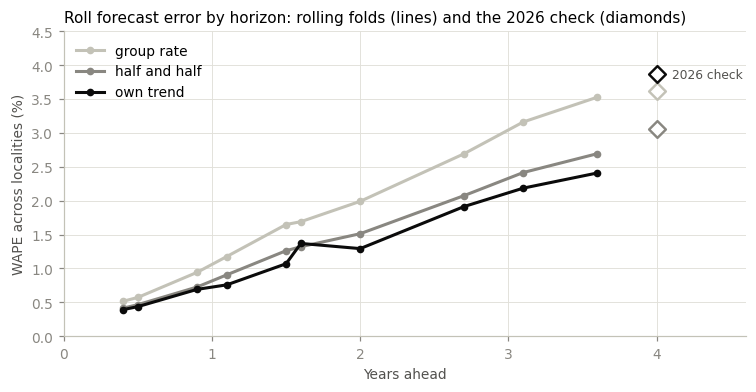

Arab      1157329.0
Jewish    6246030.0
dtype: float64

In [46]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, w), colour in zip(GROWTH_MODELS.items(), ["#c3c2b7", "#898781", "#0b0b0b"]):          # the chosen model darkest
    s = fold_scores.drop(("mean", "", ""))[name].reset_index()
    by_horizon = s.groupby("years ahead")[name].mean()
    ax.plot(by_horizon.index, by_horizon, color=colour, marker="o", markersize=4, label=name)
    ax.scatter([4.0], [check.loc["town WAPE (%)", name]], s=60, marker="D", facecolor="white", edgecolor=colour,
               linewidth=1.6, zorder=3)
ax.annotate("2026 check", (4.0, check.loc["town WAPE (%)", "own trend"]), xytext=(10, 0), textcoords="offset points",
            va="center", color="#52514e", fontsize=8)
ax.set(xlabel="Years ahead", ylabel="WAPE across localities (%)", xlim=(0, 4.6), ylim=(0, 4.5),
       title="Roll forecast error by horizon: rolling folds (lines) and the 2026 check (diamonds)")
ax.legend(loc="upper left")
plt.show()

ELECTORATE_2026 = by_sector(roll_2026.dropna())
ELECTORATE_2026.round(0)

### 6.2 Growth by sector

How fast is each part of the electorate growing? The ballot boxes of every election are grouped by how they voted:

- **Arab sector**: the sector rule of section 2;
- **Haredi**: Jewish-sector boxes where the Haredi lists won 60% or more of the valid votes, wherever they are. Unlike
  the locality groups of section 2, this counts the Haredi neighbourhoods of Jerusalem, Beit Shemesh or Ashdod;
- **other Jewish**: the rest.

A box changes group only if its vote changes, and these groups vote very stably (section 3.4).

In [47]:
haredi_vote_share = boxes["Haredi"] / boxes["valid"].where(boxes["valid"] > 0)
boxes["growth_group"] = np.select([boxes["sector"].eq("Arab"), haredi_vote_share >= HAREDI_MIN],
                                  ["Arab sector", "Haredi"], default="Other Jewish")
GROWTH_GROUPS = ["Haredi", "Arab sector", "Other Jewish"]
group_roll = boxes.pivot_table(index="election", columns="growth_group", values="registered", aggfunc="sum")[GROWTH_GROUPS]

tc = YEARS.to_numpy() - YEARS.mean()
log_roll = np.log(group_roll)
annual_growth = np.exp(log_roll.sub(log_roll.mean()).mul(tc, axis=0).sum() / (tc ** 2).sum()) - 1
group_roll.set_index(ELECTIONS["label"]).style.format("{:,}")

growth_group,Haredi,Arab sector,Other Jewish
label,,,
2013,"326,974","755,315","4,574,416"
2015,"328,375","819,173","4,734,148"
Apr 2019,"409,346","903,164","5,027,219"
Sep 2019,"421,597","937,276","5,032,345"
2020,"440,792","957,785","5,054,678"
2021,"448,448","970,005","5,159,631"
2022,"486,548","1,025,978","5,276,278"


For a 2026 forecast of each group, the roll is forecast for every polling place (the CEC's place code is stable from
September 2019). Each place grows at its own 2019–2022 trend, capped at −10% and +15% a year, and the places of a
locality are scaled to add up to the locality forecast of 6.1. A place's voters are then split between the groups as
its 2022 boxes were.

In [48]:
PLACE_ELECTIONS = ["K22", "K23", "K24", "K25"]
PLACE_KEYS = ["locality_code", "place"]
place_boxes = boxes[boxes["place"].notna()]
place_roll = place_boxes.pivot_table(index=PLACE_KEYS, columns="election", values="registered",
                                     aggfunc="sum")[PLACE_ELECTIONS]

tc = YEARS[PLACE_ELECTIONS].to_numpy() - YEARS[PLACE_ELECTIONS].mean()
complete = place_roll.gt(0).all(axis=1)
log_place = np.log(place_roll[complete])
place_rate = log_place.sub(log_place.mean(axis=1), axis=0).mul(tc).sum(axis=1) / (tc ** 2).sum()
own_rate, group_rate = growth_rates(order)
locality_rate = own_rate.fillna(group_rate)
fallback = pd.Series(locality_rate.reindex(place_roll.index.get_level_values("locality_code")).to_numpy(),
                     index=place_roll.index)
place_rate = place_rate.reindex(place_roll.index).fillna(fallback).clip(-0.10, 0.15)

horizon = (ELECTION_DAY_2026 - ELECTIONS.loc["K25", "date"]).days / 365.25
raw = place_roll["K25"].dropna() * np.exp(place_rate.reindex(place_roll["K25"].dropna().index) * horizon)
locality = raw.index.get_level_values("locality_code")
scale = roll_2026.reindex(locality).to_numpy() / raw.groupby(locality).transform("sum").to_numpy()
place_2026 = raw * np.where(np.isfinite(scale), scale, 1)

composition = (boxes[boxes["election"] == "K25"]
               .pivot_table(index=PLACE_KEYS, columns="growth_group", values="registered", aggfunc="sum").fillna(0))
composition = composition.div(composition.sum(axis=1), axis=0)
group_2026 = composition.reindex(place_2026.index).mul(place_2026, axis=0).sum()[GROWTH_GROUPS]

growth_table = pd.DataFrame({
    "roll 2013": group_roll.loc["K19"], "roll 2022": group_roll.loc["K25"], "forecast 2026": group_2026,
    "growth per year 2013–2022 %": 100 * annual_growth,
    "growth 2022–2026 %": 100 * (group_2026 / group_roll.loc["K25"] - 1),
    "share 2013 %": 100 * group_roll.loc["K19"] / group_roll.loc["K19"].sum(),
    "share 2022 %": 100 * group_roll.loc["K25"] / group_roll.loc["K25"].sum(),
    "share 2026 %": 100 * group_2026 / group_2026.sum(),
})
print(f"{len(place_2026):,} polling places")
growth_table.style.format("{:,.0f}", subset=["roll 2013", "roll 2022", "forecast 2026"]).format(
    "{:.1f}", subset=[c for c in growth_table.columns if c.endswith("%")])

4,206 polling places


,roll 2013,roll 2022,forecast 2026,growth per year 2013–2022 %,growth 2022–2026 %,share 2013 %,share 2022 %,share 2026 %
growth_group,,,,,,,,
Haredi,"326,974","486,548","553,260",4.5,13.7,5.8,7.2,7.5
Arab sector,"755,315","1,025,978","1,159,033",3.1,13.0,13.4,15.1,15.7
Other Jewish,"4,574,416","5,276,278","5,691,065",1.5,7.9,80.9,77.7,76.9


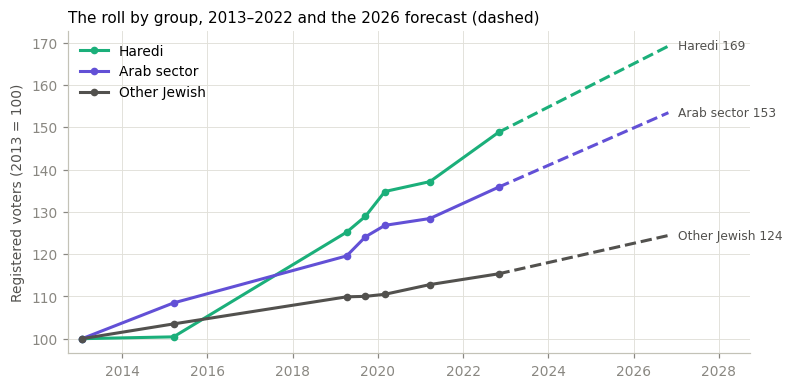

In [49]:
GROWTH_COLORS = {"Haredi": GROUP_COLORS["Haredi"], "Arab sector": GROUP_COLORS["Arab"], "Other Jewish": "#52514e"}

fig, ax = plt.subplots(figsize=(8, 3.8))
for g in GROWTH_GROUPS:
    index = 100 * group_roll[g] / group_roll.loc["K19", g]
    end = 100 * group_2026[g] / group_roll.loc["K19", g]
    ax.plot(ELECTIONS["date"], index, color=GROWTH_COLORS[g], marker="o", markersize=4, label=g)
    ax.plot([ELECTIONS.loc["K25", "date"], ELECTION_DAY_2026], [index.iloc[-1], end], color=GROWTH_COLORS[g],
            linestyle="--")
    ax.annotate(f"{g} {end:.0f}", (ELECTION_DAY_2026, end), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8, color="#52514e")
ax.set_xlim(ELECTIONS.loc["K19", "date"] - pd.Timedelta(days=120), ELECTION_DAY_2026 + pd.Timedelta(days=700))
ax.set(ylabel="Registered voters (2013 = 100)", title="The roll by group, 2013–2022 and the 2026 forecast (dashed)")
ax.legend(loc="upper left")
plt.show()

- **The Haredi electorate grows fastest**: 4.5% a year, three times the rest of the Jewish sector (1.5%). Counting
  only the Haredi towns, as in section 2, would miss more than half of these voters: the Haredi boxes held 486,548
  voters in 2022, the Haredi towns 217,901.
- **The Arab sector grows 3.1% a year.** Its share of the roll rises from 13.4% in 2013 to 15.1% in 2022, and to
  15.7% in the 2026 forecast.
- **By 2026 the Haredi boxes hold 7.5% of the roll** (5.8% in 2013) and the other Jewish boxes 76.9% (80.9%).

So even if every place voted exactly as before, the national result would move toward the Haredi parties and the
Arab lists. The flow model (6.6) carries that through to the seats.

### 6.3 Turnout by sector, with the double envelopes

Section 3 measured turnout at the ballot boxes. The double envelopes (soldiers, diplomats, hospital patients and
others voting away from home) are counted nationally, so they have to be split between the sectors by how they
voted. With *a* the Arab lists' share of the valid vote in each place:

$$\text{Arab share of the envelopes} = \frac{a_\text{envelopes} - a_\text{Jewish boxes}}{a_\text{Arab boxes} - a_\text{Jewish boxes}}$$

This assumes each sector's envelope voters vote like the voters in its boxes. The other quantities the model needs:

- **loyalty**: the Arab lists' share of the Arab sector's valid votes;
- **the Arab lists' share of the Jewish sector**: their few votes among Jewish voters;
- **invalid rates** per sector, and the **envelope factor**: Arab ballots including envelopes ÷ Arab ballots at the
  boxes.

In [50]:
def sector_history(e):
    b = boxes[boxes["election"] == e]
    g = b.groupby("sector")[["registered", "voted", "invalid", "valid", "Arab lists"]].sum()
    envelopes = town[e][town[e]["external"]]
    env_ballots, env_valid = envelopes["voted"].sum(), envelopes["valid"].sum()
    a_env = family_votes(envelopes, e)["Arab lists"].sum() / env_valid
    loyalty = g.loc["Arab", "Arab lists"] / g.loc["Arab", "valid"]
    a_jewish = g.loc["Jewish", "Arab lists"] / g.loc["Jewish", "valid"]
    arab_envelopes = (a_env - a_jewish) / (loyalty - a_jewish) * env_ballots

    total = national.loc[e]
    ballots_arab = g.loc["Arab", "voted"] + arab_envelopes
    invalid_arab = g.loc["Arab", "invalid"] / g.loc["Arab", "voted"]
    valid_arab = ballots_arab * (1 - invalid_arab)
    ballots_jewish = total["voted"] - ballots_arab
    valid_jewish = total["valid"] - valid_arab
    arab_lists = list_votes[(list_votes["election"] == e) & (list_votes["family"] == "Arab lists")]["votes"].sum()
    return {
        "roll_arab": g.loc["Arab", "registered"], "roll_jewish": g.loc["Jewish", "registered"],
        "turnout_arab": g.loc["Arab", "voted"] / g.loc["Arab", "registered"],        # at the boxes
        "turnout_jewish": ballots_jewish / g.loc["Jewish", "registered"],              # with its envelopes
        "envelope_factor": ballots_arab / g.loc["Arab", "voted"],
        "invalid_arab": invalid_arab, "invalid_jewish": 1 - valid_jewish / ballots_jewish,
        "loyalty": loyalty, "arab_lists_jewish": (arab_lists - valid_arab * loyalty) / valid_jewish,
    }


history = pd.DataFrame([sector_history(e) for e in ELECTIONS.index], index=ELECTIONS.index)
shown = history.copy()
for c in ["turnout_arab", "turnout_jewish", "invalid_arab", "invalid_jewish", "loyalty", "arab_lists_jewish"]:
    shown[c] *= 100
shown.set_index(ELECTIONS["label"]).style.format(
    {"roll_arab": "{:,.0f}", "roll_jewish": "{:,.0f}", "envelope_factor": "{:.4f}", "arab_lists_jewish": "{:.2f}"}
    | {c: "{:.1f}" for c in ["turnout_arab", "turnout_jewish", "invalid_arab", "invalid_jewish", "loyalty"]})

,roll_arab,roll_jewish,turnout_arab,turnout_jewish,envelope_factor,invalid_arab,invalid_jewish,loyalty,arab_lists_jewish
label,,,,,,,,,
2013,"755,315","4,901,390",55.9,69.5,1.0129,1.5,1.0,76.9,0.74
2015,"819,173","5,062,523",62.8,73.7,1.0140,0.9,1.0,81.8,0.65
Apr 2019,"903,164","5,436,565",48.9,71.6,1.0181,1.1,0.7,70.6,0.61
Sep 2019,"937,276","5,453,942",58.3,71.6,1.0232,1.1,0.6,79.9,0.72
2020,"957,785","5,495,470",63.7,72.6,1.0286,0.6,0.5,87.0,0.98
2021,"970,005","5,608,079",44.1,71.1,1.0445,1.1,0.5,79.7,0.69
2022,"1,025,978","5,762,826",52.6,73.4,1.0423,1.0,0.6,85.1,0.90


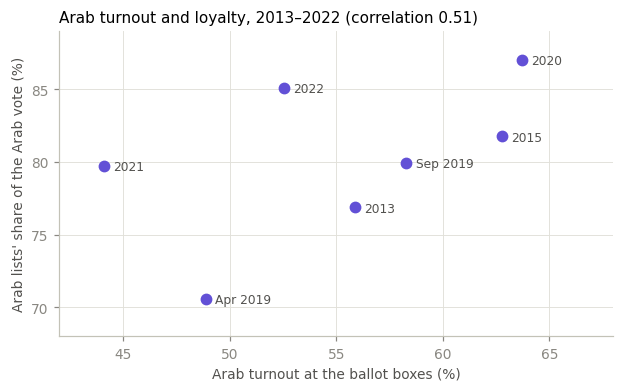

In [51]:
r = np.corrcoef(history["turnout_arab"], history["loyalty"])[0, 1]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(100 * history["turnout_arab"], 100 * history["loyalty"], s=45, color=FAMILY_COLORS["Arab lists"], zorder=3)
for e in ELECTIONS.index:
    ax.annotate(ELECTIONS.loc[e, "label"], (100 * history.loc[e, "turnout_arab"], 100 * history.loc[e, "loyalty"]),
                xytext=(6, -3), textcoords="offset points", fontsize=8, color="#52514e")
ax.set(xlim=(42, 68), ylim=(68, 89), xlabel="Arab turnout at the ballot boxes (%)",
       ylabel="Arab lists' share of the Arab vote (%)", title=f"Arab turnout and loyalty, 2013–2022 (correlation {r:.2f})")
ax.set_yticks(range(70, 90, 5))
plt.show()

Percentages except the rolls and the envelope factor. Jewish turnout including the envelopes is 69.5–73.7%, Arab
turnout at the boxes 44.1–63.7%. Loyalty moves with Arab turnout: it was highest (87%) when Arab turnout was highest
(2020). The envelopes now add over 4% to the Arab sector's ballots, up from about 1% in 2013.

### 6.4 The two-sector model

Given each sector's roll and turnout, the model gives the valid votes and the Arab lists' votes:

- Arab sector valid votes: $V_A = R_A \cdot t_A \cdot f_\text{env} \cdot (1 - i_A)$
- Jewish sector valid votes: $V_J = R_J \cdot t_J \cdot (1 - i_J)$
- Arab lists' votes: $V_A \cdot \text{loyalty} + V_J \cdot a_J$, and their share is that divided by $V_A + V_J$.

With each election's own parameters it must give back that election's ballots, valid votes and Arab-list votes.

In [52]:
def sector_model(p):
    """Two-sector turnout model. p: a mapping with the keys of `history`."""
    ballots_arab = p["roll_arab"] * p["turnout_arab"] * p["envelope_factor"]
    ballots_jewish = p["roll_jewish"] * p["turnout_jewish"]
    valid_arab = ballots_arab * (1 - p["invalid_arab"])
    valid_jewish = ballots_jewish * (1 - p["invalid_jewish"])
    arab_lists = valid_arab * p["loyalty"] + valid_jewish * p["arab_lists_jewish"]
    valid = valid_arab + valid_jewish
    return {"ballots": ballots_arab + ballots_jewish, "valid": valid, "arab_lists": arab_lists,
            "arab_lists_share": 100 * arab_lists / valid}


replay = pd.DataFrame([sector_model(history.loc[e]) for e in ELECTIONS.index], index=ELECTIONS.index)
actual_arab_lists = list_votes[list_votes["family"] == "Arab lists"].groupby("election")["votes"].sum()
assert np.allclose(replay["ballots"], national["voted"]) and np.allclose(replay["valid"], national["valid"])
assert np.allclose(replay["arab_lists"], actual_arab_lists)
print("The model gives back every election's ballots, valid votes and Arab-list votes.")

The model gives back every election's ballots, valid votes and Arab-list votes.


### 6.5 What the 2026 polls imply about Arab turnout

For 2026 every parameter takes its 2022 value, except the electorate (6.1) and Arab turnout, which is unknown. The
polls put the Joint List and Ra'am together at 11.2% of the vote. Solving the model for the Arab turnout that gives
that share shows what the polls assume.

Polls: Arab lists 11.21% of the vote -> Arab turnout 53.3% at the boxes, at 2022's loyalty (85.1%) and Jewish turnout (73.4%)


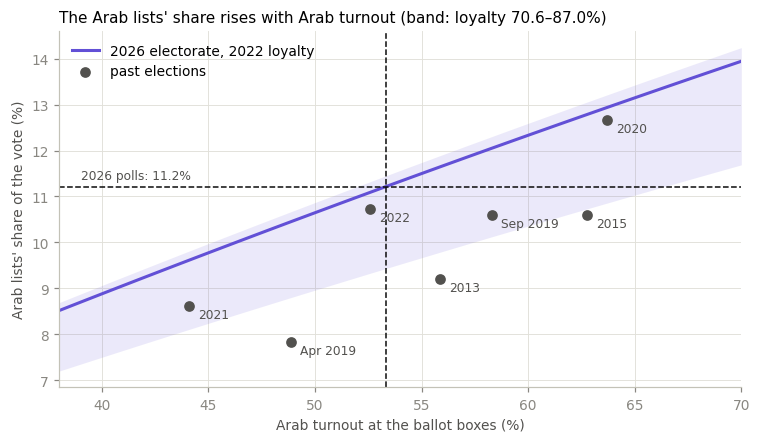

In [53]:
PARAMS_2026 = history.loc["K25"].copy()
PARAMS_2026["roll_arab"], PARAMS_2026["roll_jewish"] = ELECTORATE_2026["Arab"], ELECTORATE_2026["Jewish"]
ARAB_POLL_SHARE = baseline_2026.loc[["joint_list", "raam"], "share % (7 pollsters)"].sum()


def implied_arab_turnout(share_pct, p):
    """The Arab turnout (at the boxes) at which the model gives the Arab lists share_pct of the vote."""
    s = share_pct / 100
    valid_jewish = p["roll_jewish"] * p["turnout_jewish"] * (1 - p["invalid_jewish"])
    valid_arab = valid_jewish * (s - p["arab_lists_jewish"]) / (p["loyalty"] - s)
    return valid_arab / (p["roll_arab"] * p["envelope_factor"] * (1 - p["invalid_arab"]))


PARAMS_2026["turnout_arab"] = implied_arab_turnout(ARAB_POLL_SHARE, PARAMS_2026)
print(f"Polls: Arab lists {ARAB_POLL_SHARE:.2f}% of the vote -> Arab turnout {100 * PARAMS_2026['turnout_arab']:.1f}% "
      f"at the boxes, at 2022's loyalty ({100 * PARAMS_2026['loyalty']:.1f}%) and Jewish turnout ({100 * PARAMS_2026['turnout_jewish']:.1f}%)")

turnouts = np.linspace(0.38, 0.70, 65)
curve = [sector_model({**PARAMS_2026, "turnout_arab": t})["arab_lists_share"] for t in turnouts]
low = [sector_model({**PARAMS_2026, "turnout_arab": t, "loyalty": history["loyalty"].min()})["arab_lists_share"] for t in turnouts]
high = [sector_model({**PARAMS_2026, "turnout_arab": t, "loyalty": history["loyalty"].max()})["arab_lists_share"] for t in turnouts]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(100 * turnouts, low, high, color=FAMILY_COLORS["Arab lists"], alpha=0.12, linewidth=0)
ax.plot(100 * turnouts, curve, color=FAMILY_COLORS["Arab lists"], label="2026 electorate, 2022 loyalty")
ax.scatter(100 * history["turnout_arab"], replay["arab_lists_share"], s=36, color="#52514e", zorder=3, label="past elections")
for e in ELECTIONS.index:
    ax.annotate(ELECTIONS.loc[e, "label"], (100 * history.loc[e, "turnout_arab"], replay.loc[e, "arab_lists_share"]),
                xytext=(6, -8), textcoords="offset points", fontsize=8, color="#52514e")
ax.axhline(ARAB_POLL_SHARE, color="#0b0b0b", linewidth=1, linestyle="--")
ax.axvline(100 * PARAMS_2026["turnout_arab"], color="#0b0b0b", linewidth=1, linestyle="--")
ax.annotate(f"2026 polls: {ARAB_POLL_SHARE:.1f}%", (39, ARAB_POLL_SHARE), xytext=(0, 5), textcoords="offset points",
            fontsize=8, color="#52514e")
ax.set(xlabel="Arab turnout at the ballot boxes (%)", ylabel="Arab lists' share of the vote (%)", xlim=(38, 70),
       title="The Arab lists' share rises with Arab turnout (band: loyalty 70.6–87.0%)")
ax.legend(loc="upper left")
plt.show()

The polls imply an Arab turnout of 53%, close to 2022's and below the elections when the Arab parties ran as one
list (58–64%). Each point of Arab turnout is worth about 0.17 points of the Arab lists' share, so the range of the past
(44–64%) spans about 3.4 points of vote share, or four seats. Past elections sit below the 2026 line because the
Arab sector was a smaller part of the electorate then, and loyalty was often lower.

The polls model therefore takes the Arab lists' share from the polls, like every other list's; the flow model (6.6)
gets its own from each polling place's recent turnout; and section 7 uses this curve for scenarios: what the seats look like if Arab turnout is like 2021, or like 2020.

#### The 2026 parameters

In [54]:
SOURCES = {"roll_arab": "forecast, 6.1", "roll_jewish": "forecast, 6.1", "turnout_arab": "implied by the polls, 6.5",
           "turnout_jewish": "2022", "envelope_factor": "2022", "invalid_arab": "2022", "invalid_jewish": "2022",
           "loyalty": "2022", "arab_lists_jewish": "2022"}
def show_parameter(name, value):
    if name.startswith("roll"):
        return f"{value:,.0f}"
    return f"{value:.4f}" if name == "envelope_factor" else f"{100 * value:.2f}%"


params_table = pd.DataFrame({column: [show_parameter(k, v) for k, v in values.items()]
                             for column, values in {"2026 value": PARAMS_2026, "lowest 2013–2022": history.min(),
                                                    "highest 2013–2022": history.max()}.items()}, index=PARAMS_2026.index)
params_table["source"] = pd.Series(SOURCES)
params_table

,2026 value,lowest 2013–2022,highest 2013–2022,source
roll_arab,"1,157,329","755,315","1,025,978","forecast, 6.1"
roll_jewish,"6,246,030","4,901,390","5,762,826","forecast, 6.1"
turnout_arab,53.31%,44.08%,63.71%,"implied by the polls, 6.5"
turnout_jewish,73.45%,69.49%,73.75%,2022
envelope_factor,1.0423,1.0129,1.0445,2022
invalid_arab,1.00%,0.62%,1.45%,2022
invalid_jewish,0.57%,0.53%,1.05%,2022
loyalty,85.11%,70.56%,87.03%,2022
arab_lists_jewish,0.90%,0.61%,0.98%,2022


### 6.6 The flow model

A second forecast that does not take its levels from the polls: every polling place votes as it has been voting,
with its 2026 population. For each polling place of 2022:

1. **Electorate**: its 2026 forecast (6.2).
2. **Turnout and valid-vote rate**: its own average over its recent elections.
3. **Vote.** Where a party family has kept its shape, the place's share is averaged over its recent elections: the
   Haredi parties, the Arab lists, Labor and Meretz (The Democrats in 2026) and Yisrael Beiteinu. Where the parties
   realigned, only 2022 maps onto today's camps: Likud, Religious Zionism (which ran with Otzma Yehudit), Jewish Home
   and the centre (Yesh Atid and National Unity). Earlier lists straddle today's camps: Yamina in 2019–2021 held both
   Smotrich's voters, now in the Netanyahu bloc, and Bennett's, now in the opposition.
4. **Add up** the places, and correct for the double envelopes, which vote a little differently from the boxes
   (each party's 2022 ratio of national share to ballot-box share).

How many recent elections to average is chosen by back-test: predict 2021 and 2022 from each place's earlier
elections, with its actual roll (the roll forecast was scored in 6.1), and compare turnout and the stable families'
shares. Errors are in percentage points.

In [55]:
place_stats = place_boxes.groupby(["election"] + PLACE_KEYS)[["registered", "voted", "valid"] + FAMILIES].sum()
STABLE = ["Haredi", "Arab lists", "Left", "Yisrael Beiteinu"]


def window_stats(elections):
    """Turnout, valid-vote rate and the stable families' shares per place, pooled over the given elections."""
    s = place_stats[place_stats.index.get_level_values("election").isin(elections)].groupby(level=PLACE_KEYS).sum()
    return s["voted"] / s["registered"], s["valid"] / s["voted"], s[STABLE].div(s["valid"], axis=0)


def window_error(target, window):
    turnout, valid_rate, stable = window_stats(window)
    actual = place_stats.loc[target]
    places = actual.index.intersection(turnout.index)
    roll = actual.loc[places, "registered"]
    valid = roll * turnout[places] * valid_rate[places]
    errors = 100 * (stable.loc[places].mul(valid, axis=0).sum() / valid.sum()
                    - actual.loc[places, STABLE].sum() / actual.loc[places, "valid"].sum())
    errors["turnout"] = 100 * ((roll * turnout[places]).sum() - actual.loc[places, "voted"].sum()) / roll.sum()
    return errors


rows = {}
for target, earlier in [("K24", ["K22", "K23"]), ("K25", ["K22", "K23", "K24"])]:
    for w in range(1, len(earlier) + 1):
        e = window_error(target, earlier[-w:])
        rows[(ELECTIONS.loc[target, "label"], f"last {w}")] = {**e.to_dict(), "RMS": float(np.sqrt((e ** 2).mean()))}
window_scores = pd.DataFrame(rows).T
FLOW_WINDOW = int(window_scores.loc["2022", "RMS"].idxmin().split()[-1])     # 2022: every window can be scored
print(f"Average over each place's last {FLOW_WINDOW} elections")
window_scores.round(2)

Average over each place's last 2 elections

Haredi  Arab lists  Left  Yisrael Beiteinu  turnout   RMS
2021 last 1    0.77        4.35 -4.65              0.25     5.59  3.81
     last 2    0.71        3.27 -3.02              0.85     5.13  3.08
2022 last 1   -1.21       -2.19  3.69              1.12    -2.70  2.39
     last 2   -0.83       -0.03  1.34              1.26    -0.07  0.90
     last 3   -0.74       -0.09  1.72              1.69     0.48  1.15

Averaging each place's last two elections beats the last election alone in both years, and beats the last three in
2022 (error 0.90 points, against 2.39 and 1.15). A single election carries its one-off swings, of which the
collapse of Arab turnout in 2021 is the clearest. Turnout itself was hard to predict for 2021: it fell by five
points that year, which no average of the past could see.

In [56]:
FLOW_ELECTIONS = PLACE_ELECTIONS[-FLOW_WINDOW:]
LETTERS_2022 = LISTS[LISTS["election"] == "K25"].set_index("list")["letters"]
REALIGNED = {"Likud": ["Likud"], "Religious Zionism": ["Religious Zionism"], "Jewish Home": ["Jewish Home"],
             "Centre": ["Yesh Atid", "National Unity"]}
FLOW_GROUP_OF = {**{m: g for g, members in REALIGNED.items() for m in members},
                 "Shas": "Haredi", "United Torah Judaism": "Haredi", "Ra'am": "Arab lists", "Hadash-Ta'al": "Arab lists",
                 "Balad": "Arab lists", "Labor": "Left", "Meretz": "Left", "Yisrael Beiteinu": "Yisrael Beiteinu"}

# 2022 votes per place for the realigned lists; the rest of the realigned share is "Other"
b22 = box["K25"][~box["K25"]["external"]]
place_2022 = b22.groupby(PLACE_KEYS)[["valid"] + list(LETTERS_2022)].sum()
realigned = pd.DataFrame({g: place_2022[LETTERS_2022[m]].sum(axis=1) for g, m in REALIGNED.items()})
realigned["Other"] = place_2022["valid"] - realigned.sum(axis=1) - place_stats.loc["K25", STABLE].sum(axis=1)

turnout, valid_rate, stable = window_stats(FLOW_ELECTIONS)
places = place_2026.index
stable = stable.reindex(places).fillna(0)
realigned_split = realigned.div(realigned.sum(axis=1), axis=0).reindex(places).fillna(0)
place_shares = pd.concat([stable, realigned_split.mul(1 - stable.sum(axis=1), axis=0)], axis=1)
valid_2026 = place_2026 * turnout.reindex(places) * valid_rate.reindex(places)
box_votes = place_shares.mul(valid_2026, axis=0).sum()

lv_2022 = list_votes[list_votes["election"] == "K25"].set_index("list")["votes"]
national_2022 = lv_2022.groupby(lambda name: FLOW_GROUP_OF.get(name, "Other")).sum()
boxes_2022 = pd.concat([place_stats.loc["K25", STABLE].sum(), realigned.sum()])
envelope_ratio = (national_2022 / national_2022.sum()) / (boxes_2022 / boxes_2022.sum())
flow_groups = box_votes / box_votes.sum() * envelope_ratio[box_votes.index]
flow_groups = 100 * flow_groups / flow_groups.sum()
print(f"Valid votes, flow model: {valid_2026.sum():,.0f} at the ballot boxes")
flow_groups.round(2)

Valid votes, flow model: 4,622,617 at the ballot boxes


Haredi               13.88
Arab lists           10.09
Left                  8.40
Yisrael Beiteinu      4.86
Likud                22.89
Religious Zionism    11.02
Jewish Home           1.21
Centre               26.16
Other                 1.49
dtype: float64

The flow model's groups become 2026 lists. A group that is one list today stays one list. The Haredi vote splits
between Shas and United Torah Judaism, and the Arab vote between the Joint List and Ra'am, as in 2022. Where one 2022
group has several heirs in 2026, the split comes from the polls: Likud into Likud and Amkha Yisrael, Religious
Zionism into Religious Zionism and Otzma Yehudit, the centre into Yashar!, Beyahad and Hendel and Zelekha. Jewish
Home's voters, whose list does not run, go to "others".

In [57]:
poll_split = baseline_2026["share % (7 pollsters)"]
AGREEMENTS_2026 = [tuple(g.index) for _, g in LISTS_2026[LISTS_2026["pair"] != ""].groupby("pair")]


def split(total, keys, weights):
    return total * weights[keys] / weights[keys].sum()


shas_part = lv_2022["Shas"] / lv_2022[["Shas", "United Torah Judaism"]].sum()
joint_part = lv_2022[["Hadash-Ta'al", "Balad"]].sum() / lv_2022[["Ra'am", "Hadash-Ta'al", "Balad"]].sum()
flow_2026 = pd.concat([
    split(flow_groups["Likud"], ["likud", "amkha_yisrael"], poll_split),
    split(flow_groups["Religious Zionism"], ["religious_zionism", "otzma_yehudit"], poll_split),
    split(flow_groups["Centre"], ["yashar", "beyahad", "hendel_zelekha"], poll_split),
    pd.Series({"shas": flow_groups["Haredi"] * shas_part, "utj": flow_groups["Haredi"] * (1 - shas_part),
               "joint_list": flow_groups["Arab lists"] * joint_part, "raam": flow_groups["Arab lists"] * (1 - joint_part),
               "democrats": flow_groups["Left"], "yisrael_beiteinu": flow_groups["Yisrael Beiteinu"],
               "others": flow_groups["Jewish Home"] + flow_groups["Other"]}),
]).reindex(list(on_ballot) + ["others"])
assert np.isclose(flow_2026.sum(), 100)

polls_with_others = pd.concat([poll_split, pd.Series({"others": OTHERS_2026})])
flow_table = pd.DataFrame({"list": LISTS_2026["list"], "bloc": LISTS_2026["bloc"],
                           "flow share %": flow_2026, "poll share %": polls_with_others,
                           "flow seats": bader_ofer(flow_2026, AGREEMENTS_2026),
                           "poll seats": bader_ofer(polls_with_others, AGREEMENTS_2026)}, index=flow_2026.index)
flow_table.loc["others", ["list", "bloc"]] = ["others", ""]
display(flow_table.round(2))
flow_table.drop(index="others").groupby("bloc")[["flow share %", "poll share %", "flow seats", "poll seats"]].sum().round(1)

,list,bloc,flow share %,poll share %,flow seats,poll seats
likud,Likud,Netanyahu,19.67,17.31,27,23
yashar,Yashar! with Eisenkot,Opposition,14.82,17.24,20,23
beyahad,Beyahad,Opposition,8.64,10.05,12,13
democrats,The Democrats,Opposition,8.40,7.30,11,9
otzma_yehudit,Otzma Yehudit,Netanyahu,5.98,6.47,7,8
joint_list,Joint List,Arab lists,6.26,6.61,8,8
utj,United Torah Judaism,Netanyahu,5.78,5.71,7,7
yisrael_beiteinu,Yisrael Beiteinu,Opposition,4.86,6.11,6,8
shas,Shas,Netanyahu,8.10,6.32,11,8
religious_zionism,Religious Zionism and Zehut,Netanyahu,5.04,5.45,6,7


,flow share %,poll share %,flow seats,poll seats
bloc,,,,
Arab lists,10.1,11.2,13,14
Netanyahu,47.8,44.1,58,53
Opposition,39.4,43.8,49,53


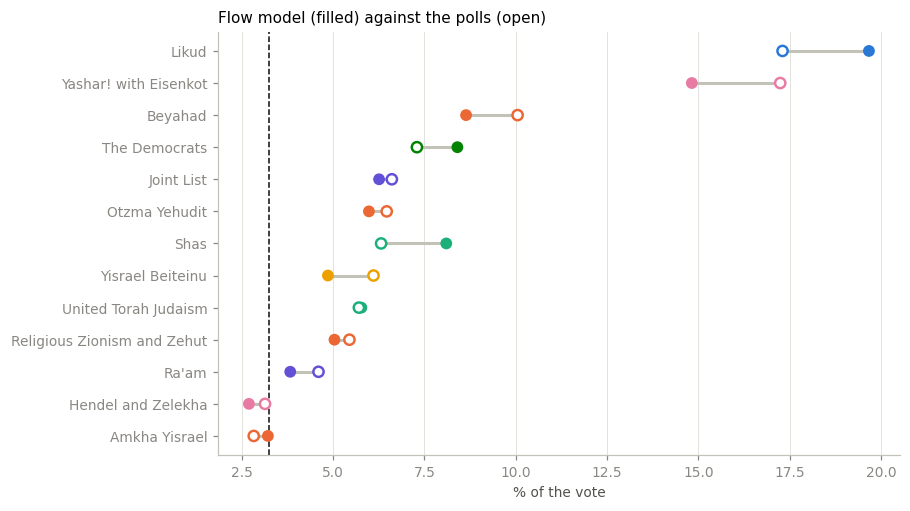

In [58]:
shown = flow_table.drop(index="others").sort_values("poll share %")
y = np.arange(len(shown))
colours = [FAMILY_COLORS[LISTS_2026.loc[k, "family"]] for k in shown.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(y, shown["poll share %"], shown["flow share %"], color="#c3c2b7", linewidth=2)
ax.scatter(shown["flow share %"], y, s=45, color=colours, zorder=3)
ax.scatter(shown["poll share %"], y, s=45, facecolor="white", edgecolor=colours, linewidth=1.6, zorder=3)
ax.axvline(3.25, color="#0b0b0b", linewidth=1, linestyle="--")
ax.set_yticks(y, shown["list"])
ax.grid(axis="y", visible=False)
ax.set(xlabel="% of the vote", title="Flow model (filled) against the polls (open)")
plt.show()

- **The flow model gives the Netanyahu bloc 58 seats** (47.8% of the vote) and the opposition 49, against 53 and 53
  in the polls as published; the Arab lists 13 against 14.
- **The gaps show where opinion has moved since 2022**, as far as the polls can tell: the flow model has more for
  Likud (19.7% against 17.3%), Shas (8.1% against 6.3%) and The Democrats, and less for Yashar!, Beyahad and Yisrael
  Beiteinu.
- Part of the Haredi gap is demography (their boxes grow 4.5% a year) and part is the polls' known miss (5.2).

The flow model is what the polls would show if nobody had changed their vote since their last elections.

Next: the polls model, its back-test, and its combination with the flow model.

## 7. The model, the back-test and the forecast

### 7.1 The polls model

The pieces of sections 4–6 put together:

1. **Start from the poll average** in vote shares (section 5), with the lists outside the table as "others".
2. **Correct the Haredi lists** by the 1.8 seats the polls missed on average (section 5.2), converted to share points
   at the seat price of the poll average and taken from the other lists in proportion.
3. **Draw the poll error.** Each list gets an independent normal error with the size measured in section 5.5
   (1.3 share points); shares below zero are set to zero and every draw is rescaled to 100%. An optional swing between
   the Netanyahu bloc and the opposition is off by default (section 5.5) and used in 7.5 as a sensitivity.
4. **Count the seats** of every draw with the fast Bader-Ofer function (section 4), threshold 3.25% and the surplus
   agreements of 2026.

A list near the threshold passes in some draws and fails in others, so its seats, and every other list's, come out
as a distribution. The model is built and tested here and back-tested on 2021 and 2022 (7.2); 7.3 combines it with the flow model,
and 7.4 runs the combination on 2026.

In [59]:
def seat_price(shares, threshold=3.25):
    """Share points per seat: the share above the threshold divided by 120."""
    lists = shares.drop("others", errors="ignore")
    return lists[lists >= threshold].sum() / 120


def apply_correction(shares, family, correction_seats):
    """Add each corrected family's seats (as share points, split by its lists' shares), rescale the rest."""
    out = shares.astype(float).copy()
    price = seat_price(shares)
    added = pd.Series(0.0, index=shares.index)
    for fam, seats in correction_seats.items():
        members = family.index[family == fam].intersection(shares.index)
        added[members] = seats * price * shares[members] / shares[members].sum()
    rest = shares.index.difference(added.index[added != 0])
    out[rest] *= (100 - (shares[added != 0] + added[added != 0]).sum()) / shares[rest].sum()
    out[added != 0] += added[added != 0]
    return out


def simulate(shares, agreements, n=20_000, list_error=None, bloc_swing=0.0, bloc=None, seed=2026, threshold=3.25):
    """Simulated elections. shares: vote share (%) per list plus "others". Returns (shares, seats) per draw."""
    list_error = LIST_ERROR_POINTS if list_error is None else list_error
    rng = np.random.default_rng(seed)
    base = shares.to_numpy(float)
    is_list = (shares.index != "others").astype(float)
    drawn = base + rng.normal(0, 1, size=(n, len(base))) * list_error * is_list    # "others" carries no error
    swing = rng.normal(0, 1, size=(n, 1)) * bloc_swing                              # drawn always: same draws either way
    if bloc_swing:
        side = bloc.reindex(shares.index)
        netanyahu, opposition = (side == "Netanyahu").to_numpy(), (side == "Opposition").to_numpy()
        drawn += swing * (netanyahu * base / base[netanyahu].sum() - opposition * base / base[opposition].sum())
    drawn = np.clip(drawn, 0, None)
    drawn = 100 * drawn / drawn.sum(axis=1, keepdims=True)
    seats = bader_ofer_fast(drawn, agreement_units(shares.index, agreements), threshold)
    return pd.DataFrame(drawn, columns=shares.index), pd.DataFrame(seats, columns=shares.index)


def summarize(seats, bloc):
    """Per list: median seats, 80% interval, P(pass). Per bloc: median, 80% interval, P(61+)."""
    lists = seats.drop(columns="others", errors="ignore")
    per_list = pd.DataFrame({"median": lists.median(), "low (10%)": lists.quantile(0.1), "high (90%)": lists.quantile(0.9),
                             "mean": lists.mean(), "P(pass)": (lists > 0).mean()})
    totals = lists.T.groupby(bloc.reindex(lists.columns)).sum().T
    per_bloc = pd.DataFrame({"median": totals.median(), "low (10%)": totals.quantile(0.1),
                             "high (90%)": totals.quantile(0.9), "P(61+)": (totals >= 61).mean()})
    return per_list, per_bloc, totals

#### The 2026 inputs

The poll average of section 5 (vote shares, seven pollsters), the blocs as the pollsters count them, and the five
surplus agreements of 2026 (from the Hebrew Wikipedia page of the election): Likud with Religious Zionism, Yashar! with
The Democrats, Beyahad with Yisrael Beiteinu, Shas with United Torah Judaism, and the Joint List with Ra'am. They are
defined in `data/lists_2026.csv` and read in 6.6.

In [60]:
average_2026 = pd.concat([baseline_2026["share % (7 pollsters)"], pd.Series({"others": OTHERS_2026})])
average_2026 = 100 * average_2026 / average_2026.sum()
FAMILY_2026 = LISTS_2026["family"]
BLOC_2026 = LISTS_2026["bloc"]
corrected_2026 = apply_correction(average_2026, FAMILY_2026, POLL_CORRECTION)
print("Agreements:", AGREEMENTS_2026)
print(f"Seat price at the poll average: {seat_price(average_2026):.3f} share points per seat; "
      f"the Haredi correction adds {(corrected_2026 - average_2026)[['shas', 'utj']].sum():.2f} points to Shas and UTJ")

Agreements: [('likud', 'religious_zionism'), ('yashar', 'democrats'), ('utj', 'shas'), ('beyahad', 'yisrael_beiteinu'), ('joint_list', 'raam')]
Seat price at the poll average: 0.776 share points per seat; the Haredi correction adds 1.39 points to Shas and UTJ


#### Tests of the model

1. With no error, every draw must give exactly the reference seat count of `bader_ofer` for the input shares.
2. The same seed must give the same draws.
3. Every draw must share out exactly 120 seats.
4. The drawn errors must have the intended size.

In [61]:
_, exact = simulate(corrected_2026, AGREEMENTS_2026, n=50, list_error=0)
reference = bader_ofer(corrected_2026, AGREEMENTS_2026)
assert (exact == reference).all().all()

drawn_a, seats_a = simulate(corrected_2026, AGREEMENTS_2026, n=5_000)
drawn_b, seats_b = simulate(corrected_2026, AGREEMENTS_2026, n=5_000)
assert drawn_a.equals(drawn_b) and seats_a.equals(seats_b)
assert (seats_a.sum(axis=1) == 120).all()

spread = (drawn_a - corrected_2026).drop(columns="others").std()
print(f"Drawn error, standard deviation by list: {spread.min():.2f}–{spread.max():.2f} share points "
      f"(intended {LIST_ERROR_POINTS:.2f}; rescaling to 100% shrinks it a little)")

Drawn error, standard deviation by list: 1.23–1.33 share points (intended 1.30; rescaling to 100% shrinks it a little)


#### The central scenario: no error

Before any uncertainty, the poll average itself through the seat rule, with and without the Haredi correction.

In [62]:
central = pd.DataFrame({
    "list": LISTS_2026["list"],
    "bloc": BLOC_2026,
    "poll share %": average_2026,
    "corrected share %": corrected_2026,
    "seats, polls as published": bader_ofer(average_2026, AGREEMENTS_2026),
    "seats, corrected": bader_ofer(corrected_2026, AGREEMENTS_2026),
}, index=average_2026.index.drop("others"))
blocs = central.groupby("bloc")[["seats, polls as published", "seats, corrected"]].sum()
display(central.round(2))
blocs

,list,bloc,poll share %,corrected share %,"seats, polls as published","seats, corrected"
likud,Likud,Netanyahu,17.31,17.03,23,22
yashar,Yashar! with Eisenkot,Opposition,17.24,16.97,23,22
beyahad,Beyahad,Opposition,10.05,9.89,13,13
democrats,The Democrats,Opposition,7.30,7.18,9,9
otzma_yehudit,Otzma Yehudit,Netanyahu,6.47,6.37,8,8
joint_list,Joint List,Arab lists,6.61,6.51,8,8
utj,United Torah Judaism,Netanyahu,5.71,6.37,7,8
yisrael_beiteinu,Yisrael Beiteinu,Opposition,6.11,6.01,8,8
shas,Shas,Netanyahu,6.32,7.05,8,9
religious_zionism,Religious Zionism and Zehut,Netanyahu,5.45,5.36,7,7


,"seats, polls as published","seats, corrected"
bloc,,
Arab lists,14,14
Netanyahu,53,54
Opposition,53,52


Hendel and Zelekha (3.1%) and Amkha Yisrael (2.8%) are under the threshold in the poll average, so they win nothing
here and their votes are lost. As published, the polls give the Netanyahu bloc 53 seats, the opposition 53 and the
Arab lists 14. The correction adds a seat to each Haredi list, one taken from Likud and one from Yashar!, so the bloc
rises to 54. But a list 0.1 points under the
threshold is close to a coin flip, which this central run cannot show. The simulation can.

#### How a list near the threshold is simulated

The drawn shares of the two lists closest to the threshold, over 5,000 simulated elections. Each draw where a list
lands to the right of the line, it passes and wins at least four seats.

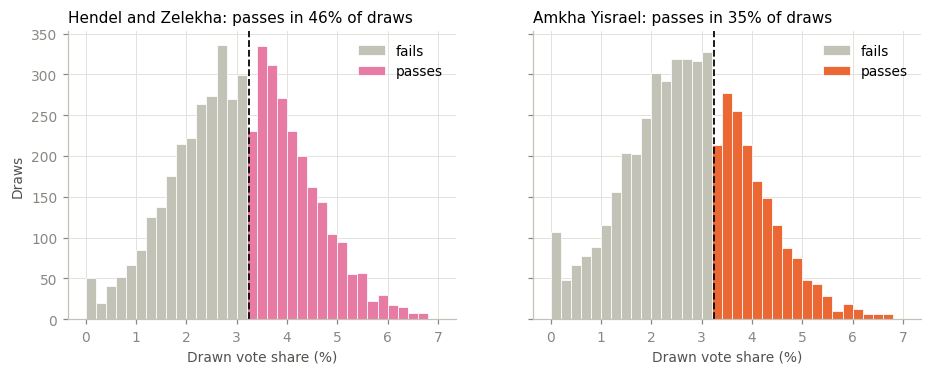

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.arange(0, 7.01, 0.2)
for ax, key in zip(axes, ["hendel_zelekha", "amkha_yisrael"]):
    values = drawn_a[key]
    colour = FAMILY_COLORS[FAMILY_2026[key]]
    ax.hist(values[values < 3.25], bins=bins, color="#c3c2b7", edgecolor="white", linewidth=0.5, label="fails")
    ax.hist(values[values >= 3.25], bins=bins, color=colour, edgecolor="white", linewidth=0.5, label="passes")
    ax.axvline(3.25, color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.set(xlabel="Drawn vote share (%)",
           title=f"{LISTS_2026.loc[key, 'list']}: passes in {(values >= 3.25).mean():.0%} of draws")
    ax.legend(loc="upper right")
axes[0].set_ylabel("Draws")
plt.show()

The errors are drawn with the size measured in 2021–2022 (1.3 points), so a list polling at 3.1% passes in close
to half the draws, and one at 2.8% in about a third. Whether these lists pass moves seats between every other list,
which is why the forecast is a distribution and not a single number.

### 7.2 Back-test on 2021 and 2022

The model, run as it would have been run in the final week of the 2021 and 2022 campaigns, and
compared with what happened. Three things are scored:

- **seats per list**: whether the result fell inside the 80% interval (if the intervals are honest, about 8 lists
  in 10 should);
- **the threshold**: a Brier score for each list's chance of passing (0 is perfect, 0.25 is a coin flip);
- **the blocs**: whether the Netanyahu bloc's result fell inside its interval, and the chance of 61 seats the model
  gave it.

Two caveats. The 2021–2022 polls give seats only, so their vote shares have to be rebuilt from the seats (below); the
2026 run uses the printed shares. And the Haredi correction and the error size were measured on these same two
elections, so this back-test checks that the pieces fit together; it is not a test on unseen data. That test is
2026 itself (section 8).

#### Vote shares from seats

D'Hondt hands out seats like rounding down at a common divisor, so a list with *s* seats has on average *s* + ½
divisors' worth of votes. Each list's share is therefore (seats + ½) times a divisor chosen so that the lists add up
to 100 minus the share left outside the table. That share is not in the polls; the back-test takes the previous
election's share lost below the threshold, which was known at the time.

The half seat matters. Without it, a list the polls give 4 seats lands right at 3.25%, fails in half the draws and
hands its votes to the large lists, which then come out 2–3 seats above the polls.

In [64]:
BACKTEST_BLOCS = {
    "K24": {"Likud": "Netanyahu", "Shas": "Netanyahu", "United Torah Judaism": "Netanyahu",
            "Religious Zionism": "Netanyahu", "Joint List": "Arab lists", "Ra'am": "Arab lists"},
    "K25": {"Likud": "Netanyahu", "Religious Zionism": "Netanyahu", "Shas": "Netanyahu",
            "United Torah Judaism": "Netanyahu", "Hadash-Ta'al": "Arab lists", "Ra'am": "Arab lists"},
}   # every other list is "Other"


def seats_to_shares(seats, outside_pct):
    """Vote shares from average seats, (seats + 1/2) x divisor; "others" holds the share left outside."""
    shares = (seats + 0.5).where(seats > 0, 0)
    shares *= (100 - outside_pct) / shares.sum()
    return pd.concat([shares, pd.Series({"others": outside_pct})])


def backtest(e, correction):
    previous = ELECTIONS.index[ELECTIONS.index.get_loc(e) - 1]
    poll = final_week(e)
    shares = seats_to_shares(poll, national.loc[previous, "below_threshold_pct"])
    family = list_votes[list_votes["election"] == e].set_index("list")["family"]
    if correction:
        shares = apply_correction(shares, family, POLL_CORRECTION)
    result = list_votes[list_votes["election"] == e].set_index("list")["seats"].reindex(poll.index)
    scored = poll.index[(poll > 0) | (result > 0)]          # the 2021 Economic Party: polled at 0, won 0
    bloc = pd.Series({name: BACKTEST_BLOCS[e].get(name, "Other") for name in scored})
    _, seats = simulate(shares, AGREEMENTS[e], threshold=ELECTIONS.loc[e, "threshold_pct"])
    central = bader_ofer(shares, AGREEMENTS[e], ELECTIONS.loc[e, "threshold_pct"])
    return {"poll": poll[scored], "shares": shares, "seats": seats[scored], "central": central[scored],
            "bloc": bloc, "result": result[scored]}


backtests = {(e, correction): backtest(e, correction) for e in ["K24", "K25"] for correction in (False, True)}

#### Scores

In [65]:
def score(run):
    seats, result = run["seats"], run["result"]
    low, high, passes = seats.quantile(0.1), seats.quantile(0.9), (seats > 0).mean()
    totals = seats.T.groupby(run["bloc"]).sum().T
    bloc_actual = result.groupby(run["bloc"]).sum()
    return {
        "lists inside the 80% interval": f"{((result >= low) & (result <= high)).sum()} of {len(result)}",
        "Brier score, pass or fail": ((passes - (result > 0)) ** 2).mean(),
        "Netanyahu bloc: result": bloc_actual["Netanyahu"],
        "Netanyahu bloc: median": totals["Netanyahu"].median(),
        "Netanyahu bloc: 80% interval": f"{totals['Netanyahu'].quantile(0.1):.0f}–{totals['Netanyahu'].quantile(0.9):.0f}",
        "P(Netanyahu bloc 61+)": (totals["Netanyahu"] >= 61).mean(),
    }


scores_table = pd.DataFrame({f"{ELECTIONS.loc[e, 'label']}, {'with' if c else 'without'} correction": score(run)
                             for (e, c), run in backtests.items()})
scores_table

,"2021, without correction","2021, with correction","2022, without correction","2022, with correction"
lists inside the 80% interval,10 of 13,10 of 13,11 of 11,11 of 11
"Brier score, pass or fail",0.05438,0.058793,0.077254,0.078556
Netanyahu bloc: result,52,52,64,64
Netanyahu bloc: median,52.0,53.0,62.0,64.0
Netanyahu bloc: 80% interval,47–56,48–58,58–67,59–69
P(Netanyahu bloc 61+),0.0082,0.02095,0.706,0.8132


- **The intervals hold.** 10 of the 13 lists of 2021 and all 11 of 2022 fell inside their 80% intervals: 21 of 24,
  close to what honest 80% intervals should catch (about 19, give or take 2).
- **The threshold calls are good**: Brier scores of 0.05–0.08. The one list that failed, Meretz in 2022, was given a
  one-in-three chance of failing.
- **The blocs fall inside their intervals both times.** In 2021 the model gave the Netanyahu bloc a 1–2% chance of
  61 seats (it won 52); in 2022 a 71% chance without the correction and 81% with it (it won 64).
- **The Haredi correction moves the 2022 bloc median from 62 to the actual 64**, but it was fitted on these
  elections, so that is expected rather than proof.

The point accuracy is the polls' own (section 5): the simulation does not make the centre better, it puts honest
error bars around it. A median is also a poor point estimate for a list near the threshold, which either wins
nothing or wins four seats: Ra'am 2021 passed in 40% of the draws, so its median was 0.

The chart shows every list with the Haredi correction.

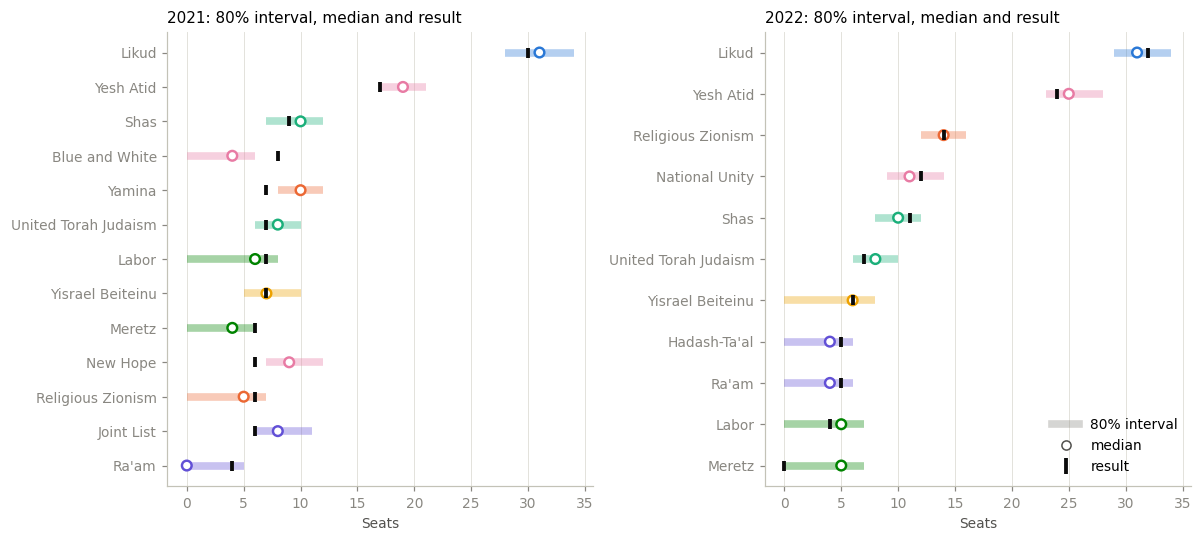

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True)
for ax, e in zip(axes, ["K24", "K25"]):
    run = backtests[(e, True)]
    seats = run["seats"]
    order_ = run["result"].sort_values().index
    y = np.arange(len(order_))
    family = list_votes[list_votes["election"] == e].set_index("list")["family"]
    colours = [FAMILY_COLORS[family[name]] for name in order_]
    ax.hlines(y, seats.quantile(0.1)[order_], seats.quantile(0.9)[order_], color=colours, linewidth=5, alpha=0.35)
    ax.scatter(seats.median()[order_], y, s=40, facecolor="white", edgecolor=colours, linewidth=1.6, zorder=3)
    ax.scatter(run["result"][order_], y, s=40, color="#0b0b0b", marker="|", linewidth=2.5, zorder=4)
    ax.set_yticks(y, order_)
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Seats", title=f"{ELECTIONS.loc[e, 'label']}: 80% interval, median and result")
handles = [plt.Line2D([], [], color="#898781", linewidth=5, alpha=0.35, label="80% interval"),
           plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="#52514e", label="median"),
           plt.Line2D([], [], marker="|", linestyle="", color="#0b0b0b", markersize=10, markeredgewidth=2.5, label="result")]
axes[1].legend(handles=handles, loc="lower right")
fig.tight_layout()
plt.show()

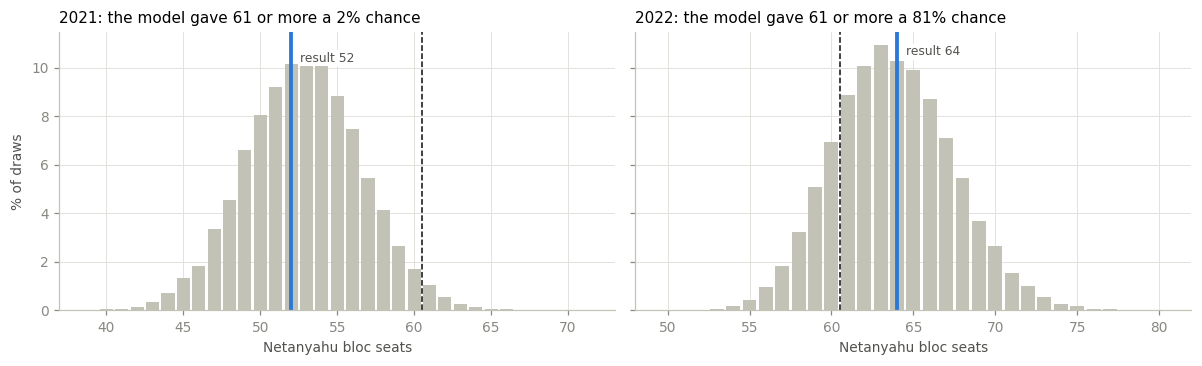

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, e in zip(axes, ["K24", "K25"]):
    run = backtests[(e, True)]
    totals = run["seats"].T.groupby(run["bloc"]).sum().T["Netanyahu"]
    actual = run["result"].groupby(run["bloc"]).sum()["Netanyahu"]
    counts = 100 * totals.value_counts().sort_index() / len(totals)
    ax.bar(counts.index, counts, width=0.85, color="#c3c2b7")
    ax.axvline(60.5, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.axvline(actual, color=FAMILY_COLORS["Likud"], linewidth=2.5)
    ax.annotate(f"result {actual}", (actual, counts.max()), xytext=(6, 0), textcoords="offset points",
                fontsize=8, color="#52514e", va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set(xlabel="Netanyahu bloc seats",
           title=f"{ELECTIONS.loc[e, 'label']}: the model gave 61 or more a {(totals >= 61).mean():.0%} chance")
axes[0].set_ylabel("% of draws")
fig.tight_layout()
plt.show()

The misses outside the intervals are the 2021 lists that moved late: Blue and White, which the polls had at 4 and
which won 8, and New Hope and Yamina, which faded. A model built on the final polls cannot see a late swing the polls
did not see.

### 7.3 Combining the polls and the flow model

Two forecasts of the same election: the polls (opinion today, with known errors) and the flow model (each place's
recent vote with 2026's population, which misses whatever has changed since). Weighting each by the inverse of its
error variance gives the combination with the smallest expected error, if the two errors are independent.

- **The polls' error**: the back-test shares of 7.2 (with the Haredi correction) against the results of 2021 and
  2022, by camp: the right-religious families, the centre-left with Yisrael Beiteinu, and the Arab lists.
- **The flow model's error**: each camp's share carried forward one election, for every pair from 2015 to 2022
  (2013 is left out: Yisrael Beiteinu ran inside Likud's list then). This error grows with the time between
  elections, so it is measured per year (variance divided by the years between the two elections) and scaled to the
  four years from 2022 to 2026.

In [68]:
CAMPS = {"Right-religious": ["Likud", "Right", "Haredi"], "Centre-left": ["Centre", "Left", "Yisrael Beiteinu"],
         "Arab lists": ["Arab lists"]}
family_share = list_votes.pivot_table(index="election", columns="family", values="share_pct", aggfunc="sum").fillna(0)
camp_share = pd.DataFrame({c: family_share[f].sum(axis=1) for c, f in CAMPS.items()})

carried = pd.DataFrame([{"from": ELECTIONS.loc[a, "label"], "to": ELECTIONS.loc[b, "label"],
                         "years": (ELECTIONS.loc[b, "date"] - ELECTIONS.loc[a, "date"]).days / 365.25,
                         **(camp_share.loc[a] - camp_share.loc[b]).to_dict()}
                        for a, b in zip(order[1:-1], order[2:])])
HORIZON_2026 = (ELECTION_DAY_2026 - ELECTIONS.loc["K25", "date"]).days / 365.25
flow_variance = (carried[list(CAMPS)] ** 2).sum() / carried["years"].sum() * HORIZON_2026

poll_camp_errors = {}
for e in ["K24", "K25"]:
    family = list_votes[list_votes["election"] == e].set_index("list")["family"]
    poll = backtests[(e, True)]["shares"].drop("others")
    poll_camp = pd.Series({c: poll[family.reindex(poll.index).isin(f).to_numpy()].sum() for c, f in CAMPS.items()})
    poll_camp_errors[ELECTIONS.loc[e, "label"]] = poll_camp - camp_share.loc[e]
poll_variance = (pd.DataFrame(poll_camp_errors).T ** 2).mean()

POLL_WEIGHT = float(flow_variance.mean() / (poll_variance.mean() + flow_variance.mean()))
display(carried.round(2))
print(f"Weight on the polls: {POLL_WEIGHT:.2f}; on the flow model: {1 - POLL_WEIGHT:.2f}")
pd.DataFrame({"polls: error sd": np.sqrt(poll_variance),
              "flow model: error sd at 4 years": np.sqrt(flow_variance)}).round(2)

,from,to,years,Right-religious,Centre-left,Arab lists
0,2015,Apr 2019,4.06,-4.05,0.54,2.78
1,Apr 2019,Sep 2019,0.44,1.53,1.41,-2.78
2,Sep 2019,2020,0.46,-2.44,3.92,-2.07
3,2020,2021,1.06,0.48,-3.45,4.06
4,2021,2022,1.61,-1.25,3.40,-2.12


Weight on the polls: 0.77; on the flow model: 0.23


,polls: error sd,flow model: error sd at 4 years
Right-religious,1.03,3.72
Centre-left,2.76,4.64
Arab lists,2.80,4.61


Carried forward over four years, a camp's share misses by 3.7–4.6 points (one standard deviation); the polls missed
by 1.0–2.8 points. The weights come out at **77% for the polls and 23% for the flow model**, and the combination gives
the Netanyahu bloc 55 seats before any uncertainty is added: between the corrected polls' 54 and the flow model's 58.

Two caveats. The polls' error rests on two elections, and the flow model's mostly on elections less than two years
apart, scaled up by an assumption (error variance growing in proportion to the time between elections). The
single-model and equal-weight forecasts are in 7.5.

In [69]:
def combine(polls):
    return POLL_WEIGHT * polls + (1 - POLL_WEIGHT) * flow_2026.reindex(polls.index)


blended_2026 = combine(corrected_2026)
combination = pd.DataFrame({"list": LISTS_2026["list"], "bloc": BLOC_2026,
                            "polls (corrected) %": corrected_2026, "flow %": flow_2026, "combined %": blended_2026,
                            "polls seats": bader_ofer(corrected_2026, AGREEMENTS_2026),
                            "flow seats": bader_ofer(flow_2026, AGREEMENTS_2026),
                            "combined seats": bader_ofer(blended_2026, AGREEMENTS_2026)},
                           index=corrected_2026.index).drop(index="others")
display(combination.round(2))
combination.groupby("bloc")[["polls seats", "flow seats", "combined seats"]].sum()

,list,bloc,polls (corrected) %,flow %,combined %,polls seats,flow seats,combined seats
likud,Likud,Netanyahu,17.03,19.67,17.63,22,27,23
yashar,Yashar! with Eisenkot,Opposition,16.97,14.82,16.48,22,20,22
beyahad,Beyahad,Opposition,9.89,8.64,9.61,13,12,13
democrats,The Democrats,Opposition,7.18,8.40,7.46,9,11,9
otzma_yehudit,Otzma Yehudit,Netanyahu,6.37,5.98,6.28,8,7,8
joint_list,Joint List,Arab lists,6.51,6.26,6.45,8,8,8
utj,United Torah Judaism,Netanyahu,6.37,5.78,6.23,8,7,8
yisrael_beiteinu,Yisrael Beiteinu,Opposition,6.01,4.86,5.75,8,6,7
shas,Shas,Netanyahu,7.05,8.10,7.28,9,11,9
religious_zionism,Religious Zionism and Zehut,Netanyahu,5.36,5.04,5.29,7,6,7


,polls seats,flow seats,combined seats
bloc,,,
Arab lists,14,13,14
Netanyahu,54,58,55
Opposition,52,49,51


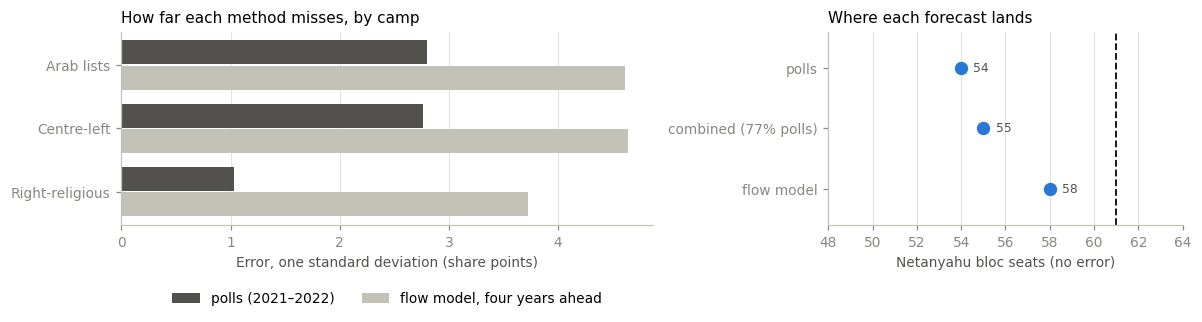

In [70]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [3, 2]})
camps = list(CAMPS)
y = np.arange(len(camps))
left.barh(y + 0.2, np.sqrt(poll_variance[camps]), height=0.38, color="#52514e", label="polls (2021–2022)")
left.barh(y - 0.2, np.sqrt(flow_variance[camps]), height=0.38, color="#c3c2b7", label="flow model, four years ahead")
left.set_yticks(y, camps)
left.grid(axis="y", visible=False)
left.set(xlabel="Error, one standard deviation (share points)", title="How far each method misses, by camp")
left.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)

bloc_seats = combination.groupby("bloc")[["polls seats", "combined seats", "flow seats"]].sum().loc["Netanyahu"]
labels = ["polls", f"combined ({POLL_WEIGHT:.0%} polls)", "flow model"]
yy = np.arange(len(labels))[::-1]
right.axvline(61, color="#0b0b0b", linewidth=1.2, linestyle="--")
right.scatter(bloc_seats.to_numpy(), yy, s=60, color=FAMILY_COLORS["Likud"], zorder=3)
for value, level in zip(bloc_seats, yy):
    right.annotate(f"{value:.0f}", (value, level), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8,
                   color="#52514e")
right.set_yticks(yy, labels)
right.grid(axis="y", visible=False)
right.set(xlim=(48, 64), ylim=(-0.6, 2.6), xlabel="Netanyahu bloc seats (no error)", title="Where each forecast lands")
fig.tight_layout()
plt.show()

### 7.4 The 2026 forecast

The combined forecast of 7.3, with the errors of the polls model, 20,000 simulated elections.

In [71]:
FORECAST_DRAWS = 20_000
drawn_2026, seats_2026 = simulate(blended_2026, AGREEMENTS_2026, n=FORECAST_DRAWS)
per_list_2026, per_bloc_2026, totals_2026 = summarize(seats_2026, BLOC_2026)
totals_2026["Opposition + Arab lists"] = totals_2026["Opposition"] + totals_2026["Arab lists"]
BLOC_ORDER = ["Netanyahu", "Opposition", "Arab lists"]

forecast_table = pd.DataFrame({
    "list": LISTS_2026["list"], "bloc": BLOC_2026, "poll share %": average_2026, "corrected share %": corrected_2026,
    "flow share %": flow_2026, "combined share %": blended_2026,
    "median seats": per_list_2026["median"],
    "80% interval": [f"{lo:.0f}–{hi:.0f}" for lo, hi in zip(per_list_2026["low (10%)"], per_list_2026["high (90%)"])],
    "P(pass)": per_list_2026["P(pass)"],
}, index=per_list_2026.index)
forecast_table["bloc"] = pd.Categorical(forecast_table["bloc"], BLOC_ORDER)
forecast_table = forecast_table.sort_values(["bloc", "median seats", "combined share %"], ascending=[True, False, False])
forecast_table.style.format({"poll share %": "{:.2f}", "corrected share %": "{:.2f}", "flow share %": "{:.2f}",
                             "combined share %": "{:.2f}", "median seats": "{:.0f}",
                             "P(pass)": "{:.0%}"}).hide(axis="index")

list,bloc,poll share %,corrected share %,flow share %,combined share %,median seats,80% interval,P(pass)
Likud,Netanyahu,17.31,17.03,19.67,17.63,23,20–25,100%
Shas,Netanyahu,6.32,7.05,8.10,7.28,9,7–11,100%
Otzma Yehudit,Netanyahu,6.47,6.37,5.98,6.28,8,6–10,99%
United Torah Judaism,Netanyahu,5.71,6.37,5.78,6.23,8,6–10,99%
Religious Zionism and Zehut,Netanyahu,5.45,5.36,5.04,5.29,6,4–9,95%
Amkha Yisrael,Netanyahu,2.83,2.78,3.22,2.88,0,0–5,39%
Yashar! with Eisenkot,Opposition,17.24,16.97,14.82,16.48,21,19–24,100%
Beyahad,Opposition,10.05,9.89,8.64,9.61,12,10–14,100%
The Democrats,Opposition,7.30,7.18,8.40,7.46,9,7–11,100%
Yisrael Beiteinu,Opposition,6.11,6.01,4.86,5.75,7,5–9,98%


In [72]:
def bloc_summary(totals):
    return pd.DataFrame({b: {"median": totals[b].median(),
                             "80% interval": f"{totals[b].quantile(0.1):.0f}–{totals[b].quantile(0.9):.0f}",
                             "P(61+)": (totals[b] >= 61).mean()}
                         for b in BLOC_ORDER + ["Opposition + Arab lists"]}).T


bloc_table = bloc_summary(totals_2026)
bloc_table.style.format({"median": "{:.0f}", "P(61+)": "{:.1%}"})

,median,80% interval,P(61+)
Netanyahu,55,51–60,7.7%
Opposition,52,47–56,1.0%
Arab lists,13,8–16,0.0%
Opposition + Arab lists,65,60–69,87.6%


- **No bloc reaches 61 in most simulated elections.** The Netanyahu bloc's median is 55 seats (80% interval 51–60),
  and it reaches 61 in 7.7% of the draws, about one in thirteen.
- **The opposition alone reaches 61 in 1% of the draws.** With the Arab lists it does in 88%: a majority without the
  Netanyahu bloc depends on the Arab lists in almost every draw.
- **Likud is the largest list**, 23 seats (20–25), ahead of Yashar! with 21 (19–24).
- **Ra'am passes in 81% of the draws**, Hendel and Zelekha in 42%, Amkha Yisrael in 39%.

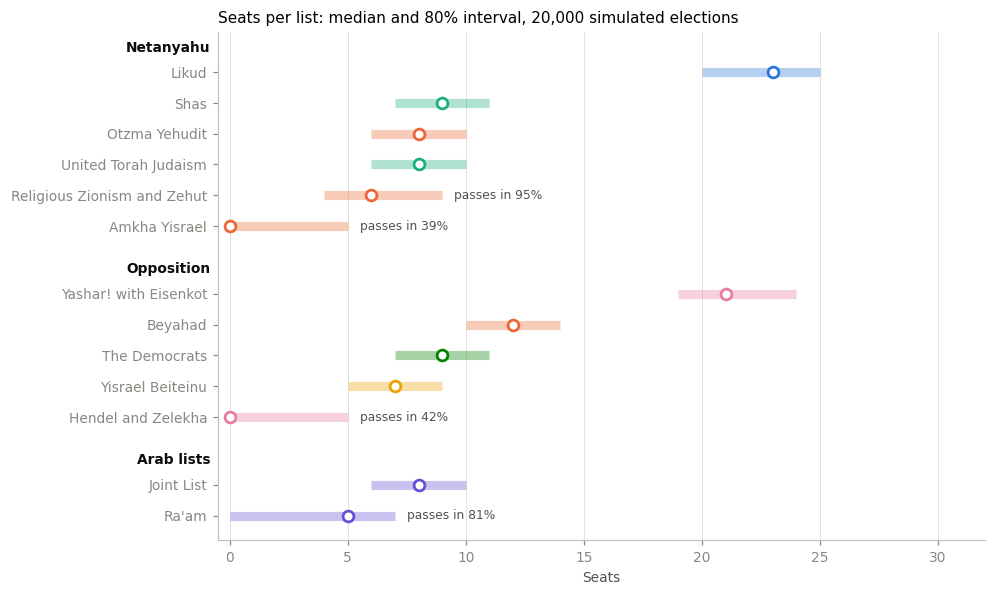

In [73]:
fig, ax = plt.subplots(figsize=(9, 6))
y, ticks, labels = 0, [], []
for bloc in reversed(BLOC_ORDER):
    rows = forecast_table[forecast_table["bloc"] == bloc].iloc[::-1]
    for key, row in rows.iterrows():
        colour = FAMILY_COLORS[FAMILY_2026[key]]
        low, high = per_list_2026.loc[key, ["low (10%)", "high (90%)"]]
        ax.hlines(y, low, high, color=colour, linewidth=6, alpha=0.35)
        ax.scatter(row["median seats"], y, s=50, facecolor="white", edgecolor=colour, linewidth=1.8, zorder=3)
        if row["P(pass)"] < 0.95:
            ax.annotate(f"passes in {row['P(pass)']:.0%}", (high, y), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8, color="#52514e")
        ticks.append(y)
        labels.append(row["list"])
        y += 1
    ax.text(-0.01, y - 0.2, bloc, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9,
            fontweight="bold", color="#0b0b0b")
    y += 1.2
ax.set_ylim(-0.8, y - 0.9)
ax.set_yticks(ticks, labels)
ax.grid(axis="y", visible=False)
ax.set(xlim=(-0.5, 32), xlabel="Seats", title="Seats per list: median and 80% interval, 20,000 simulated elections")
plt.show()

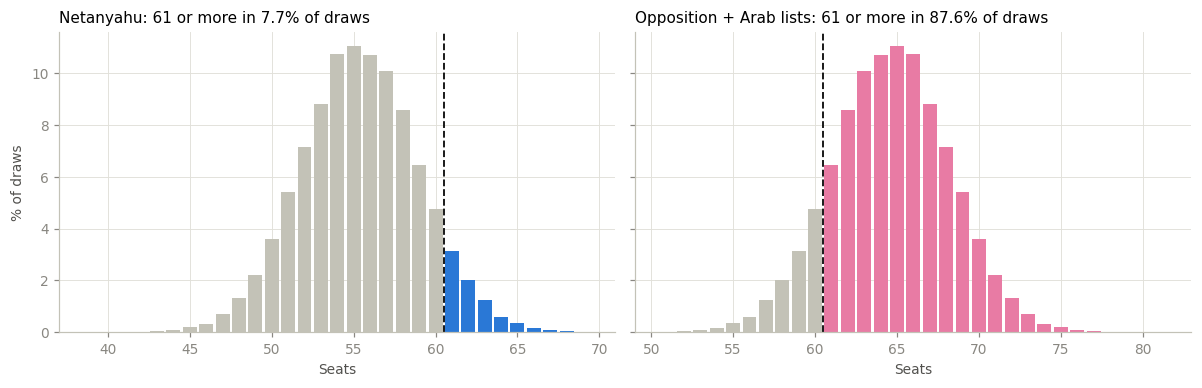

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, colour) in zip(axes, [("Netanyahu", FAMILY_COLORS["Likud"]),
                                     ("Opposition + Arab lists", FAMILY_COLORS["Centre"])]):
    counts = totals_2026[name].value_counts().sort_index()
    ax.bar(counts.index, counts / FORECAST_DRAWS * 100, width=0.85,
           color=[colour if s >= 61 else "#c3c2b7" for s in counts.index])
    ax.axvline(60.5, color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.set(xlabel="Seats", title=f"{name}: 61 or more in {(totals_2026[name] >= 61).mean():.1%} of draws")
axes[0].set_ylabel("% of draws")
fig.tight_layout()
plt.show()

#### What the threshold lists decide

Two lists sit just under the threshold, one in each camp: Amkha Yisrael counts in the Netanyahu bloc, Hendel and
Zelekha in the opposition. The draws split four ways by which of them passes.

In [75]:
amkha_passes = seats_2026["amkha_yisrael"] > 0
hendel_passes = seats_2026["hendel_zelekha"] > 0
rows = {}
for amkha in (True, False):
    for hendel in (True, False):
        mask = (amkha_passes == amkha) & (hendel_passes == hendel)
        t = totals_2026[mask]
        rows[(f"Amkha Yisrael {'passes' if amkha else 'fails'}", f"Hendel and Zelekha {'passes' if hendel else 'fails'}")] = {
            "% of draws": 100 * mask.mean(), "Netanyahu median": t["Netanyahu"].median(),
            "P(Netanyahu 61+)": (t["Netanyahu"] >= 61).mean(), "Opposition median": t["Opposition"].median(),
            "P(Opposition + Arab 61+)": (t["Opposition + Arab lists"] >= 61).mean()}
conditional = pd.DataFrame(rows).T
conditional.style.format({"% of draws": "{:.0f}", "Netanyahu median": "{:.0f}", "Opposition median": "{:.0f}",
                          "P(Netanyahu 61+)": "{:.1%}", "P(Opposition + Arab 61+)": "{:.1%}"})

When Amkha Yisrael passes and Hendel and Zelekha fails (almost one draw in four), the Netanyahu bloc's median is 58
and its chance of 61 is 20%. In the opposite case (about one draw in four) it is 53 and about 1%. The two small
lists move the bloc by five seats between its best and worst case.

In [76]:
OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)
forecast_table.round({"poll share %": 2, "corrected share %": 2, "flow share %": 2, "combined share %": 2, "P(pass)": 3}).to_csv(
    OUTPUTS / "forecast_2026_lists.csv", index_label="key")
bloc_table.assign(**{"P(61+)": bloc_table["P(61+)"].astype(float).round(3)}).to_csv(
    OUTPUTS / "forecast_2026_blocs.csv", index_label="bloc")
print("Saved to outputs/: forecast_2026_lists.csv, forecast_2026_blocs.csv")

Saved to outputs/: forecast_2026_lists.csv, forecast_2026_blocs.csv


### 7.5 Sensitivity

The forecast rests on choices made in sections 5–7. Each row below changes one of them and reruns the 20,000
draws with the same random numbers, so the differences are the effect of that choice alone.

- **Polls only, flow only, equal weights**: the two models alone, and an even split instead of the weight of 7.3.
- **No Haredi correction**: the polls as published, combined with the flow model.
- **Bloc swing**: a shared error moving votes between the Netanyahu bloc and the opposition, with a standard deviation
  of one list error (1.3 points). Its size is hand-set: two elections cannot measure it (section 5.5).
- **Polls weighted by sample size**: every poll of the final week, weighted by its respondents (section 5.4).
- **Arab turnout as in 2021 or 2020**: the Arab lists' total share from the turnout model of section 6 at that
  election's Arab turnout, split between the Joint List and Ra'am as in the polls, and the other lists rescaled.

In [77]:
def poll_shares(rows):
    """Each poll's list shares summing to 100 with "others", Blue and White folded into the opposition."""
    raw = rows[share_columns].fillna(0)
    raw.columns = [c.removesuffix("_pct") for c in raw.columns]
    out = raw.div(raw.sum(axis=1), axis=0) * 100
    withdrawn = out.pop("blue_white")
    out[opposition] += out[opposition].mul(withdrawn / out[opposition].sum(axis=1), axis=0)
    out["others"] = out.drop(columns=on_ballot).sum(axis=1)
    return out[list(on_ballot) + ["others"]]


assert np.allclose(poll_shares(with_shares.reset_index()).mean(), average_2026[list(on_ballot) + ["others"]])

week = k26[(k26["date"] > k26["date"].max() - pd.Timedelta(days=7)) & k26[share_columns].notna().any(axis=1)]
weighted_2026 = poll_shares(week).mul(week["respondents"].to_numpy(), axis=0).sum() / week["respondents"].sum()


def with_arab_turnout(shares, turnout):
    """The Arab lists' total share from the turnout model, split as in the polls; the other lists rescaled."""
    target = sector_model({**PARAMS_2026, "turnout_arab": turnout})["arab_lists_share"]
    arab = ["joint_list", "raam"]
    out = shares.copy()
    out[arab] *= target / shares[arab].sum()
    rest = shares.index.difference(arab)
    out[rest] *= (100 - target) / shares[rest].sum()
    return out


def run_scenario(shares, **options):
    _, seats = simulate(shares, AGREEMENTS_2026, n=FORECAST_DRAWS, **options)
    totals = seats.drop(columns="others").T.groupby(BLOC_2026).sum().T
    return {"Netanyahu": totals["Netanyahu"].median(),
            "Netanyahu 80%": f"{totals['Netanyahu'].quantile(0.1):.0f}–{totals['Netanyahu'].quantile(0.9):.0f}",
            "Opposition": totals["Opposition"].median(), "Arab lists": totals["Arab lists"].median(),
            "P(Netanyahu 61+)": (totals["Netanyahu"] >= 61).mean(),
            "P(Opposition + Arab 61+)": ((totals["Opposition"] + totals["Arab lists"]) >= 61).mean()}


sensitivity = pd.DataFrame({
    "Main forecast (polls and flow combined)": run_scenario(blended_2026),
    "Polls only": run_scenario(corrected_2026),
    "Flow only": run_scenario(flow_2026),
    "Equal weights": run_scenario(0.5 * corrected_2026 + 0.5 * flow_2026),
    "No Haredi correction": run_scenario(combine(average_2026)),
    "Bloc swing of 1.3 points (hand-set)": run_scenario(blended_2026, bloc_swing=LIST_ERROR_POINTS, bloc=BLOC_2026),
    "Polls weighted by sample size": run_scenario(combine(apply_correction(weighted_2026, FAMILY_2026, POLL_CORRECTION))),
    f"Arab turnout as in 2021 ({100 * history.loc['K24', 'turnout_arab']:.0f}%)":
        run_scenario(with_arab_turnout(blended_2026, history.loc["K24", "turnout_arab"])),
    f"Arab turnout as in 2020 ({100 * history.loc['K23', 'turnout_arab']:.0f}%)":
        run_scenario(with_arab_turnout(blended_2026, history.loc["K23", "turnout_arab"])),
}).T
sensitivity.style.format({"Netanyahu": "{:.0f}", "Opposition": "{:.0f}", "Arab lists": "{:.0f}",
                          "P(Netanyahu 61+)": "{:.1%}", "P(Opposition + Arab 61+)": "{:.1%}"})

,Netanyahu,Netanyahu 80%,Opposition,Arab lists,P(Netanyahu 61+),P(Opposition + Arab 61+)
Main forecast (polls and flow combined),55,51–60,52,13,7.7%,87.6%
Polls only,54,50–59,53,13,3.9%,93.3%
Flow only,59,55–64,49,12,39.7%,50.1%
Equal weights,57,52–62,51,13,15.7%,77.0%
No Haredi correction,54,50–59,52,13,4.7%,92.1%
Bloc swing of 1.3 points (hand-set),55,50–60,52,13,9.9%,85.2%
Polls weighted by sample size,57,53–62,50,13,19.4%,71.7%
Arab turnout as in 2021 (44%),56,52–61,53,11,13.2%,80.2%
Arab turnout as in 2020 (64%),54,49–58,50,16,2.7%,95.0%


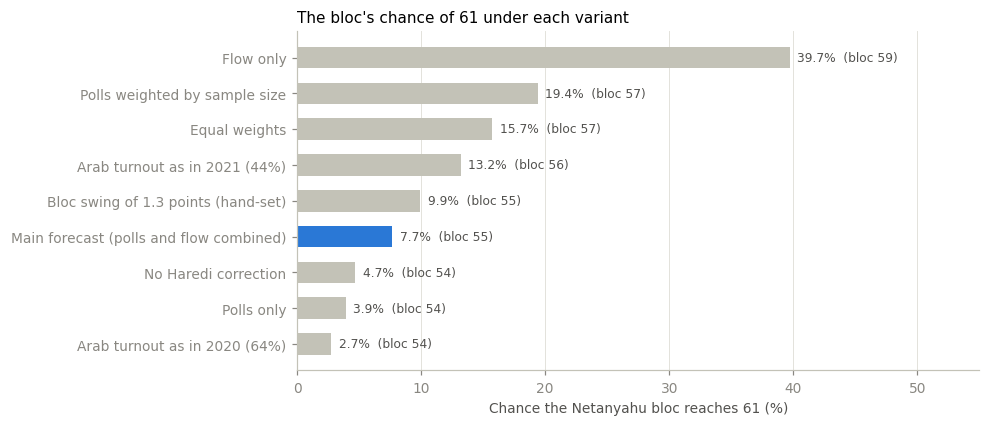

In [78]:
chance = sensitivity["P(Netanyahu 61+)"].astype(float).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(chance.index, 100 * chance, height=0.6,
        color=[FAMILY_COLORS["Likud"] if name.startswith("Main") else "#c3c2b7" for name in chance.index])
for y, name in enumerate(chance.index):
    ax.annotate(f"{100 * chance[name]:.1f}%  (bloc {sensitivity.loc[name, 'Netanyahu']:.0f})", (100 * chance[name], y),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 55)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Chance the Netanyahu bloc reaches 61 (%)", title="The bloc's chance of 61 under each variant")
plt.show()

- **The weight on the flow model matters most.** Polls alone give the Netanyahu bloc 54 seats and a 3.9% chance of
  61; equal weights 57 and 16%; the flow model alone 59 and 40%.
- **Every variant but the flow model alone leaves the bloc short of 61 in most draws**; its chance of 61 runs from
  2.7% to 19.4%.
- **How the polls are averaged matters next.** Weighting them by sample size gives Next Data, the pollster with by
  far the largest Likud, 44% of the weight among the polls that print shares: the bloc's median rises to 57 and its
  chance of 61 to 19%.
- **Arab turnout moves the Arab lists two to three seats each way**: 11 at 2021's turnout (the bloc 56, a 13% chance
  of 61), 16 at 2020's (the bloc 54, 3%).
- **The Haredi correction and the bloc swing matter less**: 4.7% without the correction, 9.9% with a bloc swing.

### 7.6 The forecast in one paragraph

On the polls of 15–21 October, corrected for their past misses of the Haredi parties and combined with a flow model
of every polling place (77% polls, 23% flow), the Netanyahu bloc wins about 55 seats (80% interval 51–60) and reaches
61 in about one simulated election in thirteen. The opposition and the Arab lists together win about 65. The largest
uncertainties are how much weight the flow model deserves, the two lists just under the threshold, and how the polls
are averaged.

## 8. Limitations and scoring after the election

### 8.1 Limitations

- **Two elections.** The poll error, the Haredi correction and the back-test all rest on 2021 and 2022, the only
  campaigns with published polls in the data. The correction and the error size are checked on the same elections
  they were measured on. 2015, when the final polls missed Likud by several seats, is not in the data.
- **The polls carry most of the weight.** The model corrects one known bias and adds a flow model at 23%, but it
  cannot see a late shift the polls miss, as with Blue and White in 2021.
- **The flow model's camps.** It carries 2022's Likud, Religious Zionism and centre votes into today's lists and
  splits them between the new lists by the polls, so who Beyahad or Yashar! take their voters from is an assumption.
- **The weight between the two models** rests on two elections of polls and five pairs of elections for the flow
  model, most of them less than two years apart, scaled to four years by assumption.
- **Independent list errors.** Lists of one camp may be missed together. The bloc-swing sensitivity covers this only
  roughly, at a hand-set size.
- **One error size for every list.** A list at 3% gets the same 1.3-point error as one at 17%, which may make the
  threshold calls less certain than they should be.
- **Seats-only polls in the back-test.** The 2021–2022 shares are rebuilt from seats; the 2026 run uses the printed
  shares, so the back-test checks a slightly different input.
- **No pollster house effects.** The pollsters disagree widely in 2026 (Likud 18–30 seats), and the average gives
  each one vote; section 7.5 shows how much the weighting matters.
- **Turnout.** The roll forecast overshot the published 2026 roll by 1% (2.7% in the Arab sector), voters living
  abroad are not modelled, and Arab turnout enters through the polls, the flow model's place averages and the scenarios.
- **The polls end on 21 October**, six days before the election.

### 8.2 Scoring after the election

Once the CEC publishes the results, this section scores the forecast against them, with the poll average as
published as the baseline:

- **per list**: how many results fall inside their 80% intervals, the seat error, and the Brier score of each
  list's chance of passing the threshold;
- **the bloc**: the Netanyahu bloc's result against its forecast interval, and the probability the forecast gave to
  what happened (61 or more, or not).

To run it:

1. Save the CEC's results by locality as `data/cec_results/k26_2026/results_by_town.csv`, converted to UTF-8 like
   the other years.
2. Fill in `LETTERS_2026` with each list's ballot letters from the CEC's list of the 2026 lists.
3. Run the notebook.

The 2026 seats are counted with `bader_ofer` and the five 2026 surplus agreements of `data/lists_2026.csv`.

In [79]:
def score_forecast(seats, actual, bloc, baseline):
    """Scores simulated seats (draws x lists) against the actual seats, next to a baseline seat count."""
    lists = actual.index
    draws = seats[lists]
    low, high, median, passes = draws.quantile(0.1), draws.quantile(0.9), draws.median(), (draws > 0).mean()
    side = bloc.reindex(lists)
    bloc_draws = draws.T.groupby(side).sum().T["Netanyahu"]
    bloc_actual = actual.groupby(side).sum()["Netanyahu"]
    p61 = (bloc_draws >= 61).mean()
    return pd.DataFrame({
        "forecast": {
            "results inside the 80% interval": f"{((actual >= low) & (actual <= high)).sum()} of {len(lists)}",
            "seat error per list (median)": f"{(median - actual).abs().mean():.2f}",
            "Brier score, pass or fail": f"{((passes - (actual > 0)) ** 2).mean():.3f}",
            "Netanyahu bloc, forecast against result":
                f"{bloc_draws.median():.0f} ({bloc_draws.quantile(0.1):.0f}–{bloc_draws.quantile(0.9):.0f}) vs {bloc_actual}",
            "probability given to what happened": f"{(p61 if bloc_actual >= 61 else 1 - p61):.0%}"},
        "polls as published": {
            "results inside the 80% interval": "–",
            "seat error per list (median)": f"{(baseline[lists] - actual).abs().mean():.2f}",
            "Brier score, pass or fail": f"{(((baseline[lists] > 0).astype(float) - (actual > 0)) ** 2).mean():.3f}",
            "Netanyahu bloc, forecast against result": f"{baseline[lists].groupby(side).sum()['Netanyahu']:.0f} vs {bloc_actual}",
            "probability given to what happened": "–"},
    })

The scoring, run on the 2022 back-test to show what it reports:

In [80]:
run_2022 = backtests[("K25", True)]
score_forecast(run_2022["seats"], run_2022["result"], run_2022["bloc"], backtests[("K25", False)]["central"])

,forecast,polls as published
results inside the 80% interval,11 of 11,–
seat error per list (median),1.18,1.27
"Brier score, pass or fail",0.079,0.091
"Netanyahu bloc, forecast against result",64 (59–69) vs 64,60 vs 64
probability given to what happened,81%,–


#### 2026

In [81]:
RESULTS_2026 = DATA / "cec_results" / "k26_2026" / "results_by_town.csv"
LETTERS_2026 = {}   # ballot letters -> list key in lists_2026.csv, from the CEC's list of the 2026 lists

if RESULTS_2026.exists() and LETTERS_2026:
    results_2026, letters_2026 = clean(pd.read_csv(RESULTS_2026, encoding="utf-8-sig"))
    votes_2026 = results_2026[letters_2026].sum().rename(index=LETTERS_2026)
    votes_2026 = votes_2026.groupby(lambda key: key if key in on_ballot else "others").sum()
    actual_2026 = bader_ofer(votes_2026, AGREEMENTS_2026).drop("others")
    display(score_forecast(seats_2026, actual_2026, BLOC_2026, bader_ofer(average_2026, AGREEMENTS_2026)))
else:
    print("The 2026 results are not in data/ yet. The forecast above was made before the election; "
          "see the steps at the top of this section to score it.")

The 2026 results are not in data/ yet. The forecast above was made before the election; see the steps at the top of this section to score it.


## 9. Manual scenarios

Some things the data cannot measure: how many Arab voters will turn out, how loyal they will be to the Arab lists, how
the Joint List and Ra'am will split, or a late shift between two lists. This section takes the main forecast, applies
such assumptions by hand, and reruns the 20,000 simulated elections with the same random draws, so the difference
from the main forecast is the effect of the assumptions alone.

Edit `SCENARIO` and rerun the cells below.

| Setting | What it does | `None` means |
|---|---|---|
| `poll_weight` | % weight of the polls against the flow model | the weight of 7.3 (77%) |
| `arab_turnout` | Arab turnout at the ballot boxes, % | the turnout the forecast implies |
| `jewish_turnout` | Jewish turnout with the double envelopes, % | 2022's (73.4%) |
| `arab_loyalty` | % of the Arab sector's valid votes that go to the Arab lists | 2022's (85.1%) |
| `joint_list_share` | the Joint List's % of the two Arab lists' votes | the forecast's split |
| `list_adjustments` | share points added to or taken from lists, e.g. `{"likud": 1.0, "yashar": -1.0}` | no change |

The turnout and loyalty settings set the Arab lists' total share through the turnout model of section 6.4, and the
other lists are rescaled so that the shares still add up to 100. The values saved below are hand-set expectations:
87% loyalty and a 60/40 split, with turnout left at what the forecast implies.

In [82]:
SCENARIO = {
    "poll_weight": None,
    "arab_turnout": None,
    "jewish_turnout": None,
    "arab_loyalty": 87,
    "joint_list_share": 60,
    "list_adjustments": {},
}

ARAB = ["joint_list", "raam"]


def scenario_shares(s):
    """The main forecast's shares with the manual settings applied."""
    weight = POLL_WEIGHT if s["poll_weight"] is None else s["poll_weight"] / 100
    shares = weight * corrected_2026 + (1 - weight) * flow_2026.reindex(corrected_2026.index)
    if any(s[k] is not None for k in ("arab_turnout", "jewish_turnout", "arab_loyalty")):
        p = PARAMS_2026.copy()
        p["turnout_arab"] = (implied_arab_turnout(shares[ARAB].sum(), PARAMS_2026) if s["arab_turnout"] is None
                             else s["arab_turnout"] / 100)
        if s["jewish_turnout"] is not None:
            p["turnout_jewish"] = s["jewish_turnout"] / 100
        if s["arab_loyalty"] is not None:
            p["loyalty"] = s["arab_loyalty"] / 100
        target = sector_model(p)["arab_lists_share"]
        rest = shares.index.difference(ARAB)
        shares[rest] *= (100 - target) / shares[rest].sum()
        shares[ARAB] *= target / shares[ARAB].sum()
    if s["joint_list_share"] is not None:
        total = shares[ARAB].sum()
        shares[ARAB] = [total * s["joint_list_share"] / 100, total * (1 - s["joint_list_share"] / 100)]
    for key, points in s["list_adjustments"].items():
        shares[key] += points
    shares = shares.clip(lower=0)
    return 100 * shares / shares.sum()

In [83]:
scenario_2026 = scenario_shares(SCENARIO)
_, scenario_seats = simulate(scenario_2026, AGREEMENTS_2026, n=FORECAST_DRAWS)
scenario_lists, _, scenario_totals = summarize(scenario_seats, BLOC_2026)
scenario_totals["Opposition + Arab lists"] = scenario_totals["Opposition"] + scenario_totals["Arab lists"]

implied = implied_arab_turnout(blended_2026[ARAB].sum(), PARAMS_2026)
print(f"Arab lists' share: main forecast {blended_2026[ARAB].sum():.2f}%, scenario {scenario_2026[ARAB].sum():.2f}% "
      f"(the forecast implies an Arab turnout of {100 * implied:.1f}% at 2022's loyalty)")

blocs_compared = pd.concat({"main forecast": bloc_summary(totals_2026), "scenario": bloc_summary(scenario_totals)}, axis=1)
for column in [("main forecast", "P(61+)"), ("scenario", "P(61+)")]:
    blocs_compared[column] = blocs_compared[column].map("{:.1%}".format)
blocs_compared

Arab lists' share: main forecast 10.82%, scenario 11.04% (the forecast implies an Arab turnout of 51.0% at 2022's loyalty)


main forecast                     scenario                    
                               median 80% interval P(61+)   median 80% interval P(61+)
Netanyahu                        55.0        51–60   7.7%     55.0        51–60   7.0%
Opposition                       52.0        47–56   1.0%     52.0        47–56   0.9%
Arab lists                       13.0         8–16   0.0%     14.0         9–17   0.0%
Opposition + Arab lists          65.0        60–69  87.6%     65.0        60–69  88.5%

In [84]:
lists_compared = pd.DataFrame({
    "list": LISTS_2026["list"], "bloc": BLOC_2026,
    "main share %": blended_2026, "scenario share %": scenario_2026,
    "main seats": per_list_2026["median"], "scenario seats": scenario_lists["median"],
    "main P(pass)": per_list_2026["P(pass)"], "scenario P(pass)": scenario_lists["P(pass)"],
}, index=per_list_2026.index)
lists_compared["bloc"] = pd.Categorical(lists_compared["bloc"], BLOC_ORDER)
(lists_compared.sort_values(["bloc", "main share %"], ascending=[True, False])
   .style.format({"main share %": "{:.2f}", "scenario share %": "{:.2f}", "main seats": "{:.0f}",
                  "scenario seats": "{:.0f}", "main P(pass)": "{:.0%}", "scenario P(pass)": "{:.0%}"})
   .hide(axis="index"))

list,bloc,main share %,scenario share %,main seats,scenario seats,main P(pass),scenario P(pass)
Likud,Netanyahu,17.63,17.58,23,23,100%,100%
Shas,Netanyahu,7.28,7.27,9,9,100%,100%
Otzma Yehudit,Netanyahu,6.28,6.26,8,8,99%,99%
United Torah Judaism,Netanyahu,6.23,6.22,8,8,99%,99%
Religious Zionism and Zehut,Netanyahu,5.29,5.28,6,6,95%,95%
Amkha Yisrael,Netanyahu,2.88,2.88,0,0,39%,39%
Yashar! with Eisenkot,Opposition,16.48,16.44,21,21,100%,100%
Beyahad,Opposition,9.61,9.59,12,12,100%,100%
The Democrats,Opposition,7.46,7.44,9,9,100%,100%
Yisrael Beiteinu,Opposition,5.75,5.74,7,7,98%,98%


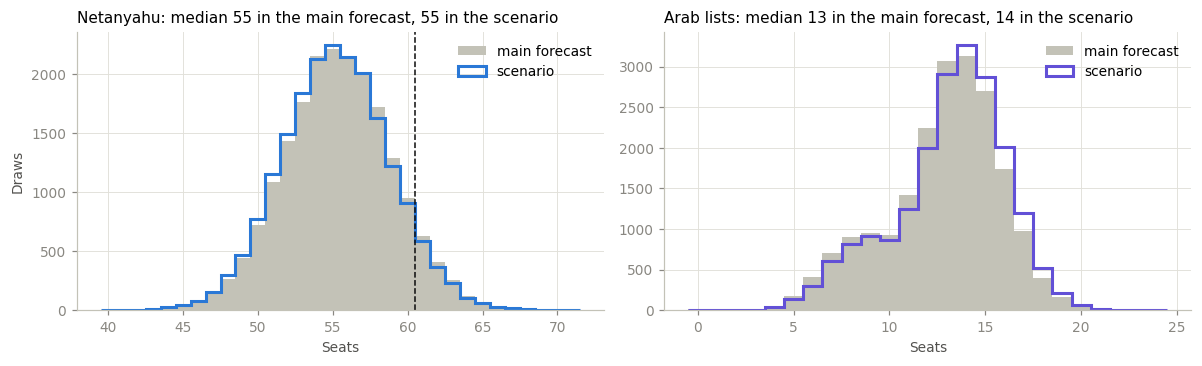

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (bloc, bins) in zip(axes, [("Netanyahu", np.arange(39.5, 72.5)), ("Arab lists", np.arange(-0.5, 25.5))]):
    ax.hist(totals_2026[bloc], bins=bins, color="#c3c2b7", label="main forecast")
    ax.hist(scenario_totals[bloc], bins=bins, histtype="step", linewidth=2,
            color=FAMILY_COLORS["Likud" if bloc == "Netanyahu" else "Arab lists"], label="scenario")
    ax.set(xlabel="Seats", title=f"{bloc}: median {totals_2026[bloc].median():.0f} in the main forecast, "
                                 f"{scenario_totals[bloc].median():.0f} in the scenario")
    ax.legend(loc="upper right")
axes[0].axvline(60.5, color="#0b0b0b", linewidth=1, linestyle="--")
axes[0].set_ylabel("Draws")
fig.tight_layout()
plt.show()